In [1]:
from pathlib import Path

import pandas as pd

data_dir = Path("CMAPSSData")
columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]

datasets = {}

for subset in ("train", "test"):
    for fd in range(1, 5):
        name = f"{subset}_FD{fd:03d}"
        path = data_dir / f"{name}.txt"
        datasets[name] = pd.read_csv(
            path,
            sep=r"\s+",
            header=None,
            names=columns,
        )

# RUL files contain one target value per corresponding test engine.
rul_targets = {
    f"RUL_FD{fd:03d}": pd.read_csv(
        data_dir / f"RUL_FD{fd:03d}.txt",
        sep=r"\s+",
        header=None,
        names=["RUL"],
    )
    for fd in range(1, 5)
}

for name, df in datasets.items():
    print(f"\n{'=' * 80}\n{name}: {df.shape[0]} rows × {df.shape[1]} columns")

    print("\nVariable types:")
    print(df.dtypes.to_string())

    missing = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
    })
    print("\nMissingness:")
    print(missing.to_string())

    print("\nDescriptive statistics:")
    print(df.describe().T.to_string())

    print("\nUnique-value counts:")
    print(df.nunique().to_string())

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
    print("\nCategorical columns and values:")
    if categorical_columns:
        for column in categorical_columns:
            print(f"{column}: {df[column].dropna().unique().tolist()}")
    else:
        print("None detected; the loaded variables are numeric.")

    print(
        "\nEngine IDs (identifiers, not categorical features):",
        sorted(df["engine_id"].unique().tolist()),
    )

for name, df in rul_targets.items():
    print(f"\n{name}: {len(df)} RUL values")
    print(df.describe().to_string())
    print("Missing values:", int(df["RUL"].isna().sum()))


train_FD001: 20631 rows × 26 columns

Variable types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64

Missingness:
           missing_count  missing_percent
engine_id              0              0.0
cycle                  0              0.0
setting_1              0              0.0
setting_2              0              0.0
setting_3              0              0.0
sensor_1               0              0.0
sensor_2               0              0.0
sensor_3               0              0.0
sensor_

**Discussion.** The files contain 20,631 training rows and 13,096 test rows, each with 26 columns; the RUL file supplies 100 test-engine outcomes. The inspected files have no missing values. Each training row is an engine-cycle observation, so the 20,631 rows are repeated measurements from 100 engines rather than independent engines.

Engine-level sample size: 100
Model summary, coefficients, confidence intervals, and Wald tests:
                      coef   exp(coef)  se(coef)  coef lower 95%  coef upper 95%           z              p
param  covariate                                                                                           
alpha_ sensor_11  0.002194    1.002197  0.038814       -0.073880        0.078269    0.056532   9.549176e-01
       sensor_12  0.036828    1.037514  0.035059       -0.031886        0.105541    1.050457   2.935080e-01
       sensor_13  0.021898    1.022139  0.040122       -0.056740        0.100536    0.545784   5.852142e-01
       sensor_14 -0.058192    0.943469  0.040801       -0.138160        0.021777   -1.426237   1.537998e-01
       sensor_15  0.006083    1.006102  0.031045       -0.054763        0.066929    0.195952   8.446478e-01
       sensor_17  0.001405    1.001406  0.024366       -0.046351        0.049161    0.057673   9.540089e-01
       sensor_2  -0.040514    0.960295 

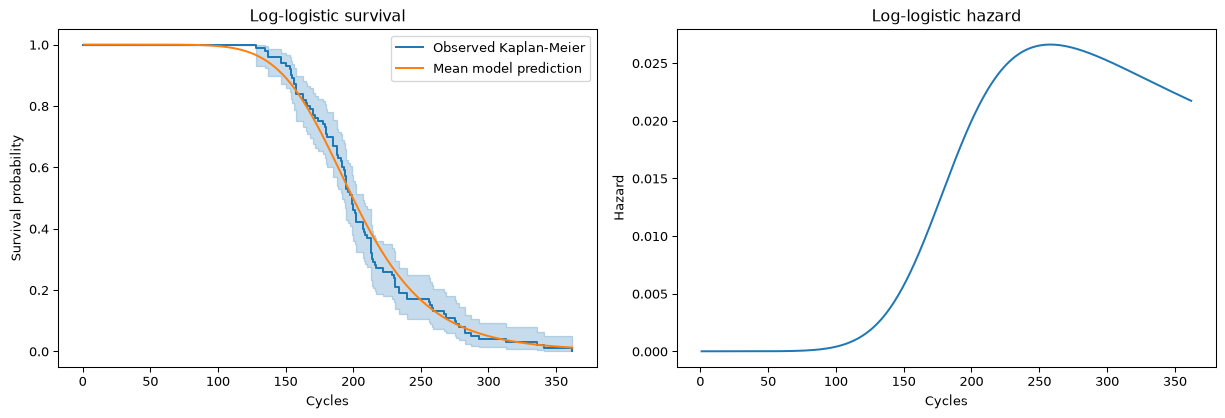

In [2]:
# Fit a log-logistic proportional-odds model using one baseline record per FD001 engine.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter, LogLogisticAFTFitter
from lifelines.utils import concordance_index

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
fd001_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

baseline = (
    fd001_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
)
failure_times = (
    fd001_raw.groupby("engine_id", as_index=False)["cycle"]
    .max()
    .rename(columns={"cycle": "T"})
)
fd001_life = baseline[["engine_id", *columns[5:]]].merge(
    failure_times, on="engine_id", validate="one_to_one"
)
fd001_life["event"] = 1

sensor_cols = [
    col for col in columns[5:]
    if fd001_life[col].nunique() > 1
]
fd001_X = fd001_life[sensor_cols].copy()
fd001_X = (fd001_X - fd001_X.mean()) / fd001_X.std(ddof=0)
fd001_model_data = pd.concat(
    [fd001_life[["T", "event"]], fd001_X], axis=1
)

assert len(fd001_raw) == 20631
assert fd001_life["engine_id"].nunique() == 100
assert fd001_life["event"].eq(1).all()

aft_model = LogLogisticAFTFitter(penalizer=0.1)
aft_model.fit(fd001_model_data, duration_col="T", event_col="event")

print("Engine-level sample size:", len(fd001_life))
print("Model summary, coefficients, confidence intervals, and Wald tests:")
print(
    aft_model.summary[
        ["coef", "exp(coef)", "se(coef)", "coef lower 95%",
         "coef upper 95%", "z", "p"]
    ].to_string()
)
print("AIC:", round(aft_model.AIC_, 2))
print(
    "Concordance index:",
    concordance_index(
        fd001_life["T"],
        aft_model.predict_median(fd001_X),
        event_observed=fd001_life["event"],
    ),
)
print("Likelihood-ratio test against the intercept-only model:")
print(aft_model.log_likelihood_ratio_test())
print(
    "Interpretation: this log-logistic AFT parameterization is a "
    "proportional-odds model. Positive alpha_ coefficients indicate "
    "longer survival; exp(coef) is the corresponding time ratio. "
    "The 0.1 ridge penalty stabilizes the sensor model."
)

timeline = np.arange(1, int(fd001_life["T"].max()) + 1)
aft_survival = aft_model.predict_survival_function(
    fd001_X, times=timeline
).mean(axis=1)
aft_hazard = aft_model.predict_hazard(
    fd001_X, times=timeline
).mean(axis=1)
fd001_km = KaplanMeierFitter().fit(
    fd001_life["T"],
    event_observed=fd001_life["event"],
    label="Observed Kaplan-Meier",
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fd001_km.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].plot(timeline, aft_survival, label="Mean model prediction")
axes[0].set(
    title="Log-logistic survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
axes[0].legend()

axes[1].plot(timeline, aft_hazard)
axes[1].set(title="Log-logistic hazard", xlabel="Cycles", ylabel="Hazard")
fig.tight_layout()
plt.show()

**Discussion.** The log-logistic proportional-odds model estimates covariate associations with engine failure time from one baseline record per engine (100 engines). Review the coefficient estimates alongside their 95% confidence intervals, Wald tests, and fitted survival/hazard plots; the intervals and diagnostics matter given the engine-level sample size.

Model summary, coefficients, confidence intervals, and Wald tests:
               coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%         z         p
covariate                                                                                   
sensor_2   0.213245   1.237688  0.122440       -0.026733        0.453223  1.741632  0.081573
sensor_3   0.095499   1.100208  0.107371       -0.114945        0.305943  0.889426  0.373774
sensor_4   0.091337   1.095638  0.145131       -0.193115        0.375788  0.629338  0.529128
sensor_6   0.113884   1.120623  0.099351       -0.080840        0.308609  1.146284  0.251678
sensor_7  -0.035151   0.965460  0.144506       -0.318377        0.248076 -0.243246  0.807815
sensor_8  -0.117316   0.889304  0.158808       -0.428573        0.193942 -0.738727  0.460073
sensor_9  -0.195848   0.822138  0.167392       -0.523930        0.132235 -1.169994  0.242003
sensor_11 -0.060333   0.941451  0.174232       -0.401821        0.281156 -0.346279  0.729133
sen

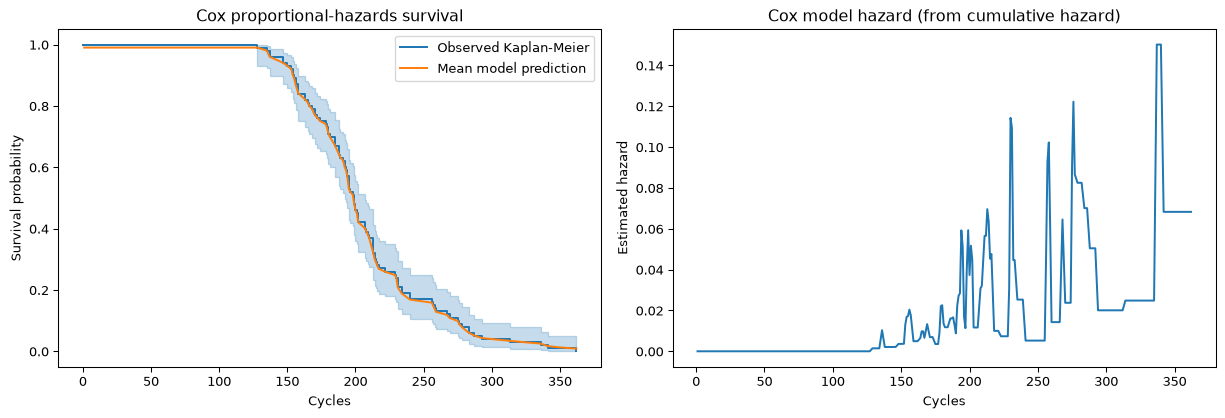

In [3]:
# Fit a Cox proportional-hazards model and check its proportional-hazards assumption.
from lifelines import CoxPHFitter

cox_model_data = pd.concat(
    [fd001_life[["T", "event"]], fd001_X], axis=1
)
cox_model = CoxPHFitter(penalizer=0.1)
cox_model.fit(cox_model_data, duration_col="T", event_col="event")

print("Model summary, coefficients, confidence intervals, and Wald tests:")
print(
    cox_model.summary[
        ["coef", "exp(coef)", "se(coef)", "coef lower 95%",
         "coef upper 95%", "z", "p"]
    ].to_string()
)
print("Partial AIC:", round(cox_model.AIC_partial_, 2))
print("Concordance index:", round(cox_model.concordance_index_, 3))
print("Proportional-hazards diagnostics:")
cox_model.check_assumptions(
    cox_model_data,
    show_plots=False,
    p_value_threshold=0.05,
)

cox_survival = cox_model.predict_survival_function(
    fd001_X, times=timeline
).mean(axis=1)
cox_cumulative_hazard = cox_model.predict_cumulative_hazard(
    fd001_X, times=timeline
).mean(axis=1)
cox_hazard = np.gradient(
    cox_cumulative_hazard.to_numpy(),
    timeline,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fd001_km.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].plot(timeline, cox_survival, label="Mean model prediction")
axes[0].set(
    title="Cox proportional-hazards survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
axes[0].legend()

axes[1].plot(timeline, cox_hazard)
axes[1].set(
    title="Cox model hazard (from cumulative hazard)",
    xlabel="Cycles",
    ylabel="Estimated hazard",
)
fig.tight_layout()
plt.show()

**Discussion.** The Cox proportional-hazards fit reports sensor hazard ratios and uncertainty, with proportional-hazards diagnostics to assess the model assumption. Interpret coefficient directions conditionally on that assumption; the diagnostic plots are part of the model assessment, not proof of causation.

Engine-level sample size: 100
Observed events: 100
Median cycles to failure: 199.0
Kaplan-Meier event-table summary:
          at_risk   observed  censored
count   67.000000  67.000000      67.0
mean    49.104478   1.492537       0.0
std     31.464812   0.859407       0.0
min      1.000000   0.000000       0.0
25%     20.000000   1.000000       0.0
50%     48.000000   1.000000       0.0
75%     76.500000   2.000000       0.0
max    100.000000   5.000000       0.0
Nelson-Aalen cumulative-hazard estimate and confidence intervals:
       FD001 engines  FD001 engines_lower_0.95  FD001 engines_upper_0.95
275.0       2.258409                  1.752983                  2.909561
276.0       2.358409                  1.824942                  3.047820
278.0       2.469520                  1.903567                  3.203738
283.0       2.737378                  2.086900                  3.590607
287.0       2.904044                  2.196162                  3.840096
293.0       3.104044        

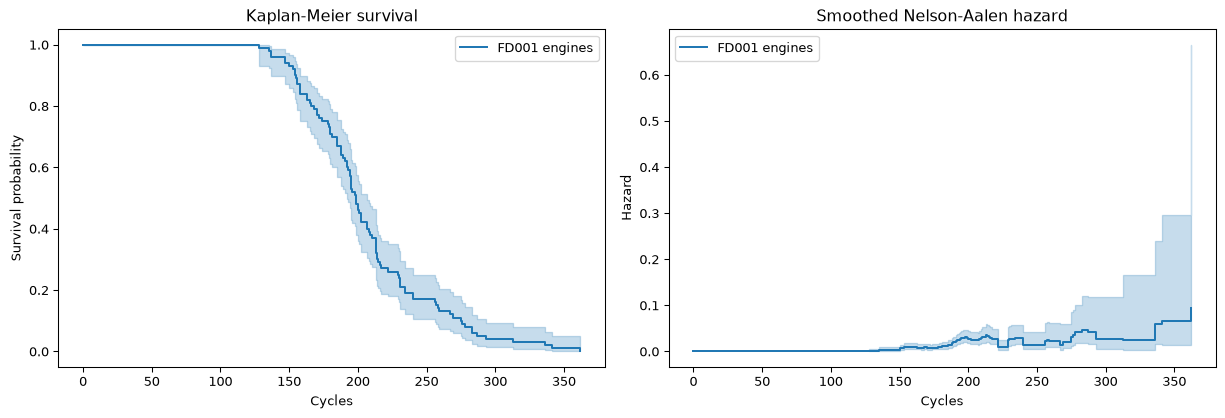

In [4]:
# Estimate FD001 survival with Kaplan-Meier and hazard with Nelson-Aalen.
from lifelines import KaplanMeierFitter, NelsonAalenFitter
from scipy.stats import norm

event_table = fd001_life[["T", "event"]]
kmf = KaplanMeierFitter().fit(
    event_table["T"],
    event_observed=event_table["event"],
    label="FD001 engines",
)
naf = NelsonAalenFitter().fit(
    event_table["T"],
    event_observed=event_table["event"],
    label="FD001 engines",
)

print("Engine-level sample size:", len(event_table))
print("Observed events:", int(event_table["event"].sum()))
print("Median cycles to failure:", kmf.median_survival_time_)
print("Kaplan-Meier event-table summary:")
print(kmf.event_table[["at_risk", "observed", "censored"]].describe())
print("Nelson-Aalen cumulative-hazard estimate and confidence intervals:")
print(
    pd.concat(
        [naf.cumulative_hazard_, naf.confidence_interval_],
        axis=1,
    ).tail(10).to_string()
)
print("KM/NA are nonparametric estimators, so regression coefficients do not apply.")

wald_time = 200
survival_at_time = float(kmf.predict(wald_time))
events_by_time = kmf.event_table.loc[:wald_time]
risk_sets = events_by_time["at_risk"]
observed_events = events_by_time["observed"]
valid_rows = risk_sets > observed_events
greenwood_sum = (
    observed_events[valid_rows]
    / (
        risk_sets[valid_rows]
        * (risk_sets[valid_rows] - observed_events[valid_rows])
    )
).sum()
greenwood_se = survival_at_time * np.sqrt(greenwood_sum)
wald_statistic = (survival_at_time - 0.5) / greenwood_se
wald_p_value = 2 * norm.sf(abs(wald_statistic))
wald_ci = np.clip(
    [
        survival_at_time - 1.96 * greenwood_se,
        survival_at_time + 1.96 * greenwood_se,
    ],
    0,
    1,
)
print(
    f"Wald test at {wald_time} cycles: H0: S(t) = 0.5; "
    f"S(t)={survival_at_time:.3f}, SE={greenwood_se:.3f}, "
    f"95% Wald CI=({wald_ci[0]:.3f}, {wald_ci[1]:.3f}), "
    f"z={wald_statistic:.3f}, p={wald_p_value:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
kmf.plot_survival_function(ax=axes[0], ci_show=True)
axes[0].set(
    title="Kaplan-Meier survival",
    xlabel="Cycles",
    ylabel="Survival probability",
)
naf.plot_hazard(ax=axes[1], bandwidth=8)
axes[1].set(
    title="Smoothed Nelson-Aalen hazard",
    xlabel="Cycles",
    ylabel="Hazard",
)
fig.tight_layout()
plt.show()

**Discussion.** Kaplan?Meier and Nelson?Aalen provide non-parametric survival and cumulative-hazard estimates for the 100 engines. All 100 training engines have observed failure events, and the estimated median failure time is 199 cycles; the confidence bands show uncertainty in the tail as fewer engines remain at risk.

Test-set model comparison (100 engines):
              C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)    IAE    ISE      AIC      BIC
Model                                                                                                     
Kaplan-Meier   0.7175                  0.8166       31.2933        36.5812 8.0390 0.7973      NaN      NaN
Cox PH         0.7100                  0.7997       32.3554        38.9310 8.1555 0.8176 740.4214 779.4989
AIC/BIC are not defined for Kaplan-Meier here (shown as NaN).
Cox BIC uses the partial log-likelihood and number of sensor coefficients.
IAE/ISE integrate absolute/squared error between mean predicted and actual test-RUL survival.


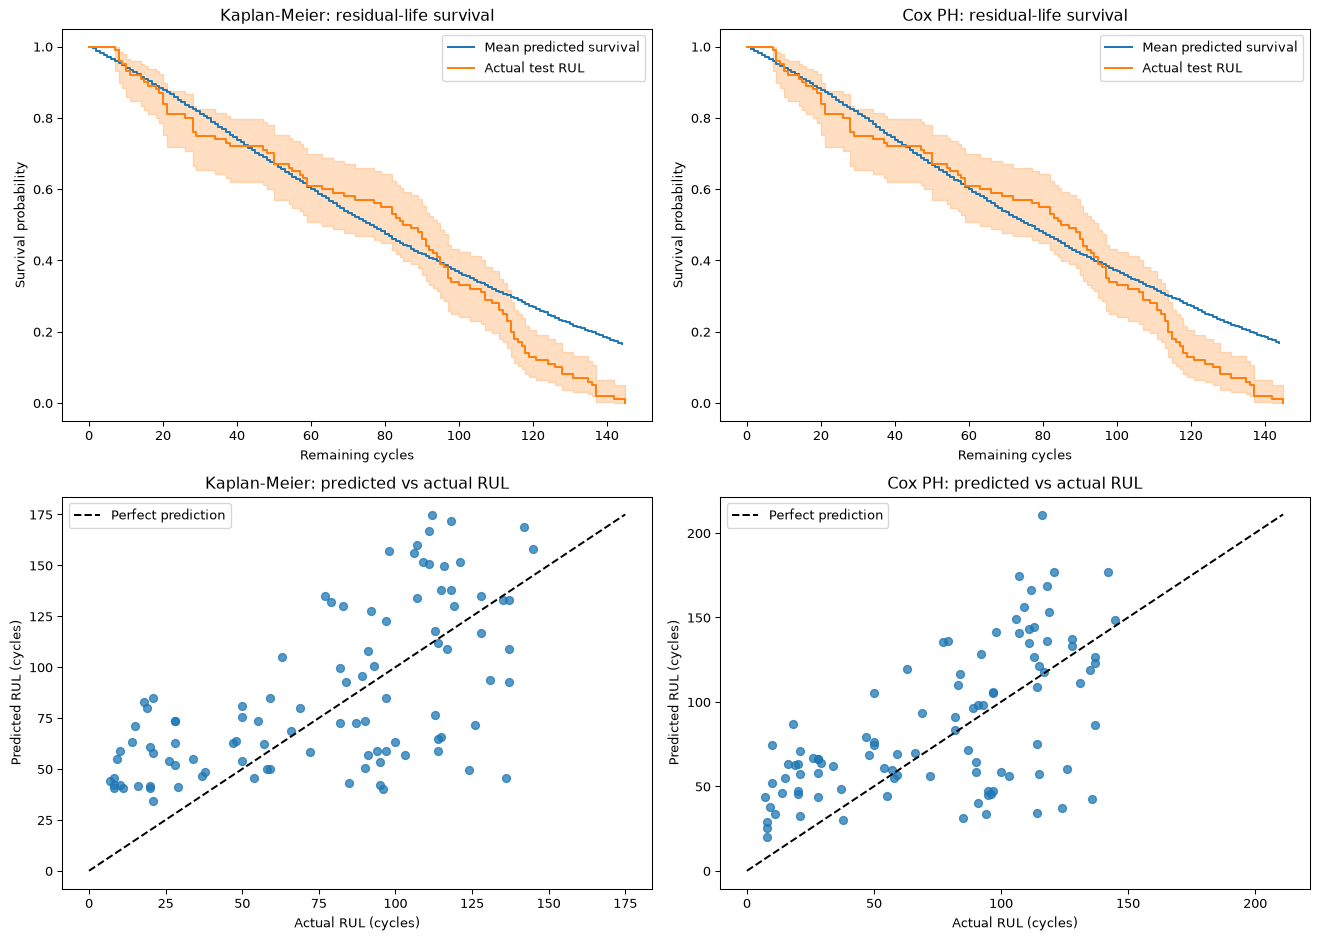

In [5]:
# Compare FD001 test RUL predictions from train-fitted Kaplan-Meier and Cox PH models.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score

columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]

train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"],
)["RUL"].to_numpy()

train_baseline = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
)
train_failure_times = (
    train_raw.groupby("engine_id", as_index=False)["cycle"]
    .max()
    .rename(columns={"cycle": "T"})
)
train_life = train_baseline[["engine_id", *columns[5:]]].merge(
    train_failure_times,
    on="engine_id",
    validate="one_to_one",
)

sensor_cols = [
    col for col in columns[5:]
    if train_life[col].nunique() > 1
]
train_mean = train_life[sensor_cols].mean()
train_sd = train_life[sensor_cols].std(ddof=0).replace(0, 1)
X_train = (train_life[sensor_cols] - train_mean) / train_sd

cox_train = X_train.copy()
cox_train["T"] = train_life["T"]
cox_train["event"] = 1

km_model = KaplanMeierFitter().fit(
    train_life["T"],
    event_observed=np.ones(len(train_life)),
)
cox_model = CoxPHFitter(penalizer=0.1).fit(
    cox_train,
    duration_col="T",
    event_col="event",
)

test_baseline = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .first()
    .sort_values("engine_id")
)
test_age = (
    test_raw.groupby("engine_id")["cycle"]
    .max()
    .sort_index()
    .to_numpy()
)

assert len(train_life) == 100
assert len(test_baseline) == len(test_age) == len(actual_rul) == 100
assert test_baseline["engine_id"].to_list() == list(range(1, 101))

X_test = (
    test_baseline.set_index("engine_id")
    .loc[range(1, 101), sensor_cols]
    - train_mean
) / train_sd

max_train_T = int(train_life["T"].max())
rul_grid = np.arange(0, max_train_T + 1)

km_at_test_age = km_model.predict(test_age).to_numpy()
assert np.all(km_at_test_age > 0), "A test age is beyond the KM survival support."

km_survival = np.vstack([
    np.asarray(km_model.predict(age + rul_grid)) / survival_at_age
    for age, survival_at_age in zip(test_age, km_at_test_age)
])
km_survival[:, 0] = 1.0

cox_survival = cox_model.predict_survival_function(
    X_test,
    times=rul_grid,
    conditional_after=test_age.tolist(),
).to_numpy().T

supported_rul = np.maximum(0, max_train_T - test_age)
outside_support = rul_grid[None, :] > supported_rul[:, None]
km_survival[outside_support] = 0.0
cox_survival[outside_support] = 0.0
km_survival = np.clip(km_survival, 0.0, 1.0)
cox_survival = np.clip(cox_survival, 0.0, 1.0)

predicted_rul = {
    "Kaplan-Meier": np.trapezoid(km_survival, rul_grid, axis=1),
    "Cox PH": np.trapezoid(cox_survival, rul_grid, axis=1),
}

actual_km = KaplanMeierFitter().fit(
    actual_rul,
    event_observed=np.ones(len(actual_rul)),
    label="Actual test RUL",
)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_survival = np.asarray(actual_km.predict(metric_horizons))

survival_predictions = {
    "Kaplan-Meier": km_survival,
    "Cox PH": cox_survival,
}
results = []

for model_name, survival_curves in survival_predictions.items():
    dynamic_auc_values = []

    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            predicted_risk = 1.0 - survival_curves[:, horizon]
            dynamic_auc_values.append(
                roc_auc_score(failed_by_horizon, predicted_risk)
            )

    predicted_mean_survival = survival_curves.mean(axis=0)[metric_horizons]
    is_km = model_name == "Kaplan-Meier"

    results.append({
        "Model": model_name,
        "C-index": concordance_index(
            actual_rul,
            predicted_rul[model_name],
        ),
        "Cumulative/Dynamic AUC": np.mean(dynamic_auc_values),
        "MAE (cycles)": mean_absolute_error(
            actual_rul,
            predicted_rul[model_name],
        ),
        "RMSE (cycles)": mean_squared_error(
            actual_rul,
            predicted_rul[model_name],
        ) ** 0.5,
        "IAE": np.trapezoid(
            np.abs(predicted_mean_survival - actual_survival),
            metric_horizons,
        ),
        "ISE": np.trapezoid(
            (predicted_mean_survival - actual_survival) ** 2,
            metric_horizons,
        ),
        "AIC": np.nan if is_km else cox_model.AIC_partial_,
        "BIC": (
            np.nan if is_km else
            -2 * cox_model.log_likelihood_
            + len(sensor_cols) * np.log(len(train_life))
        ),
    })

comparison = pd.DataFrame(results).set_index("Model")
print("Test-set model comparison (100 engines):")
print(comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("AIC/BIC are not defined for Kaplan-Meier here (shown as NaN).")
print("Cox BIC uses the partial log-likelihood and number of sensor coefficients.")
print("IAE/ISE integrate absolute/squared error between mean predicted and actual test-RUL survival.")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for axis, model_name, curves in [
    (axes[0, 0], "Kaplan-Meier", km_survival),
    (axes[0, 1], "Cox PH", cox_survival),
]:
    axis.step(
        metric_horizons,
        curves.mean(axis=0)[metric_horizons],
        where="post",
        label="Mean predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(
        title=f"{model_name}: residual-life survival",
        xlabel="Remaining cycles",
        ylabel="Survival probability",
    )
    axis.legend()

for axis, model_name in zip(axes[1], predicted_rul):
    predictions = predicted_rul[model_name]
    limit = max(int(actual_rul.max()), int(np.ceil(predictions.max())))
    axis.scatter(actual_rul, predictions, alpha=0.75)
    axis.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
    axis.set(
        title=f"{model_name}: predicted vs actual RUL",
        xlabel="Actual RUL (cycles)",
        ylabel="Predicted RUL (cycles)",
    )
    axis.legend()

fig.tight_layout()
plt.show()

**Discussion.** On the 100 test engines, Kaplan?Meier has C-index 0.7175, dynamic AUC 0.8166, MAE 31.29 cycles, and RMSE 36.58 cycles; Cox has 0.7100, 0.7997, MAE 32.36, and RMSE 38.93. Kaplan?Meier is slightly better on these ranking and error measures, while AIC/BIC are available only for Cox, not the non-parametric estimator.

FD001 test comparison (100 engines; predicted RUL is integrated residual survival):
                        C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)    IAE    ISE      AIC      BIC
Model                                                                                                               
Kaplan-Meier             0.7175                  0.8166       31.2933        36.5812 8.0390 0.7973      NaN      NaN
Cox PH                   0.7100                  0.7997       32.3554        38.9310 8.1555 0.8176 740.4214 779.4989
Random survival forest   0.7159                  0.7973       31.9272        37.8754 8.5594 0.9416      NaN      NaN
AIC/BIC are not likelihood criteria for Kaplan-Meier or RSF and are shown as NaN.
Cox AIC is partial AIC; Cox BIC uses partial log-likelihood and sensor coefficient count.
IAE/ISE compare mean predicted residual survival with empirical survival of RUL_FD001.
SHAP explains the Random-Forest surrogate of RSF risk (higher score mean

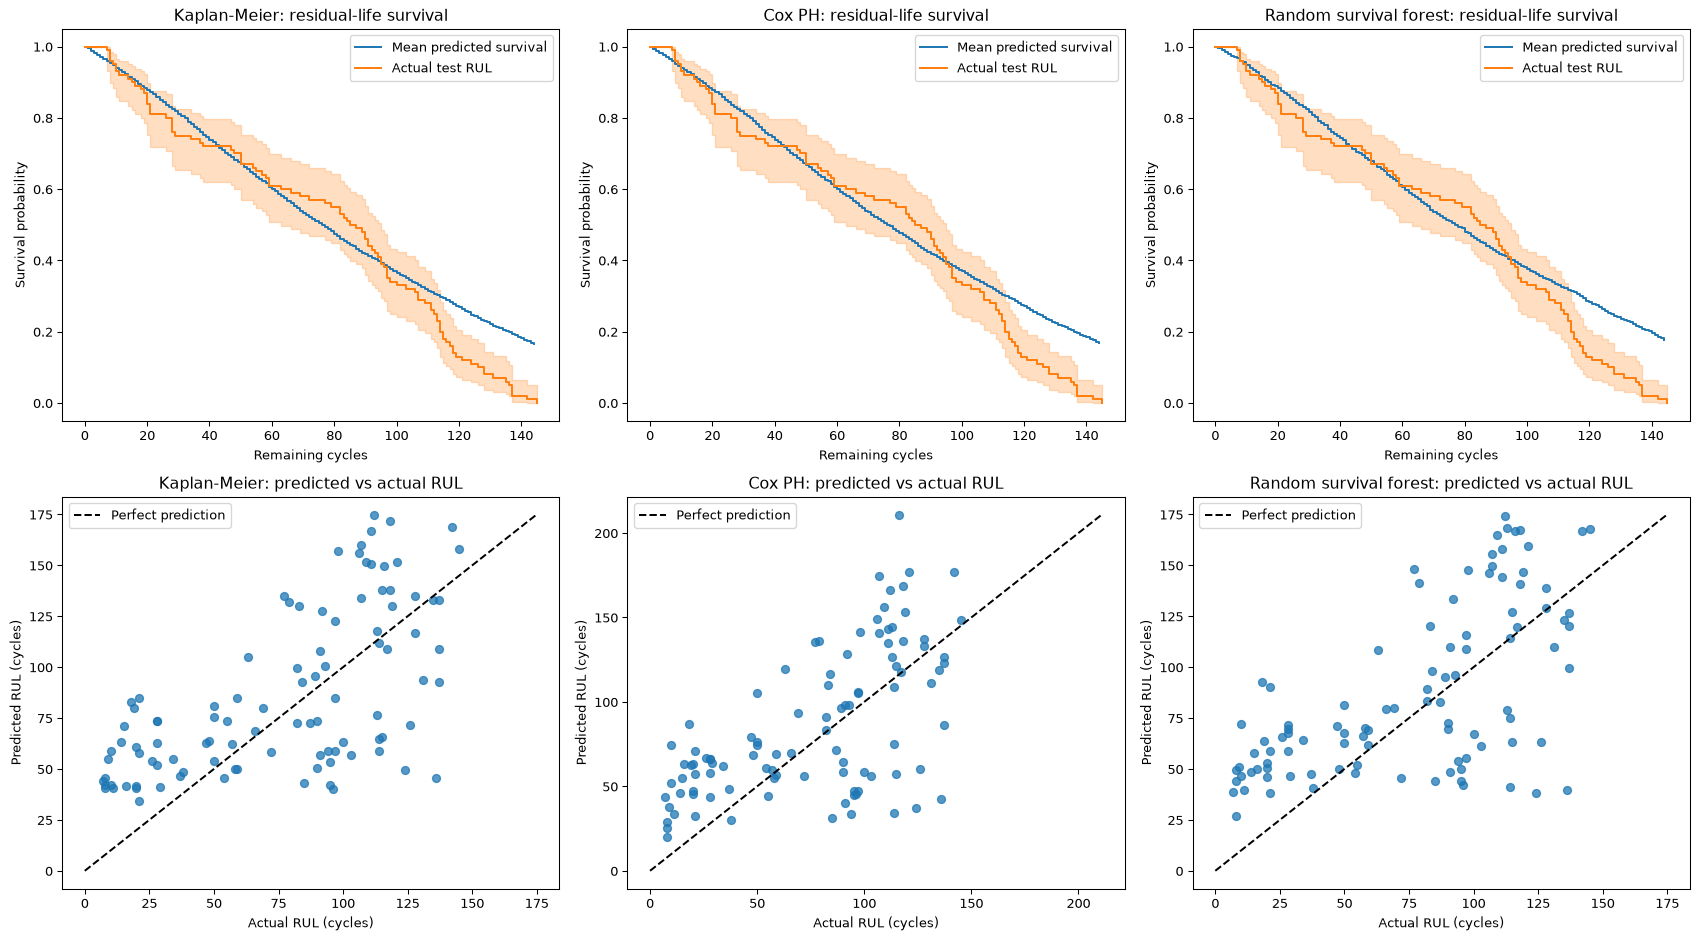

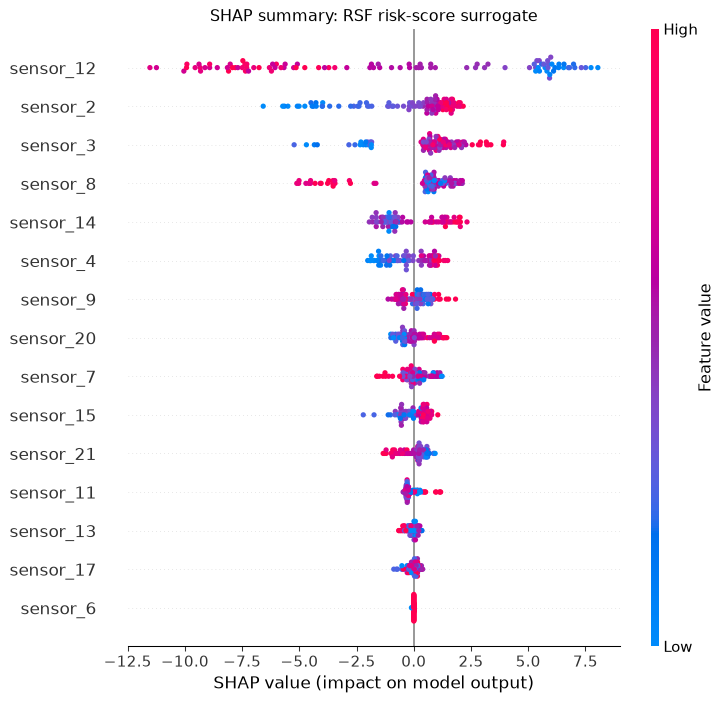

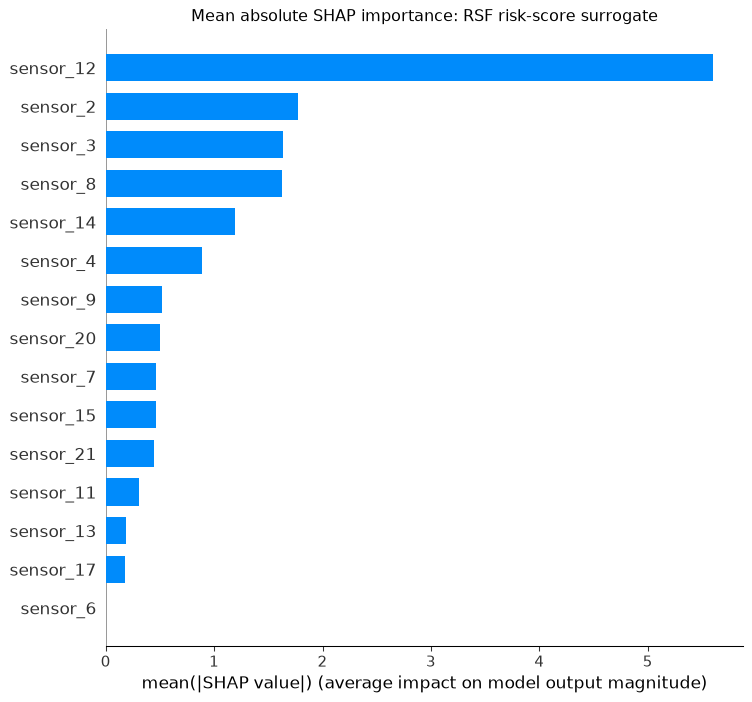

In [6]:
# Compare Kaplan-Meier, Cox PH, and random survival forest predictions for FD001, with SHAP TreeExplainer analysis.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Use one cycle-1 sensor record for each engine; training T is its observed failure cycle.
train_baseline = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
train_end = (
    train_raw.groupby("engine_id", as_index=False)["cycle"]
    .max().rename(columns={"cycle": "T"})
)
train_life = train_baseline[["engine_id", *columns[5:]]].merge(
    train_end, on="engine_id", validate="one_to_one"
)
sensor_cols = [col for col in columns[5:] if train_life[col].nunique() > 1]
train_mean = train_life[sensor_cols].mean()
train_sd = train_life[sensor_cols].std(ddof=0).replace(0, 1)
X_train = (train_life[sensor_cols] - train_mean) / train_sd
assert len(train_raw) == 20631 and len(train_life) == 100

# Fit all models on the same 100 complete training lifetimes and baseline sensors.
train_events = np.ones(len(train_life), dtype=bool)
km_model = KaplanMeierFitter().fit(
    train_life["T"], event_observed=train_events
)
cox_train = X_train.copy()
cox_train["T"] = train_life["T"]
cox_train["event"] = 1
cox_model = CoxPHFitter(penalizer=0.1).fit(
    cox_train, duration_col="T", event_col="event"
)
rsf_model = RandomSurvivalForest(
    n_estimators=300,
    min_samples_leaf=3,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
)
rsf_model.fit(
    X_train,
    Surv.from_arrays(train_events, train_life["T"].to_numpy()),
)

# Align each test RUL target to its engine's final test cycle and baseline sensor row.
test_baseline = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first().sort_values("engine_id")
)
test_age = (
    test_raw.groupby("engine_id")["cycle"].max().sort_index().to_numpy()
)
assert len(test_baseline) == len(test_age) == len(actual_rul) == 100
assert test_baseline["engine_id"].to_list() == list(range(1, 101))
X_test = (
    test_baseline.set_index("engine_id").loc[range(1, 101), sensor_cols]
    - train_mean
) / train_sd

# Convert fitted survival curves to residual survival conditional on reaching each test age.
max_train_T = int(train_life["T"].max())
rul_grid = np.arange(0, max_train_T + 1)
km_at_age = km_model.predict(test_age).to_numpy()
assert np.all(km_at_age > 0), "A test age is beyond the training KM survival support."
km_survival = np.vstack([
    np.asarray(km_model.predict(age + rul_grid)) / survival_at_age
    for age, survival_at_age in zip(test_age, km_at_age)
])
km_survival[:, 0] = 1.0
cox_survival = cox_model.predict_survival_function(
    X_test, times=rul_grid, conditional_after=test_age.tolist()
).to_numpy().T
rsf_functions = rsf_model.predict_survival_function(X_test)
rsf_at_age = np.asarray([
    survival_function(age)
    for survival_function, age in zip(rsf_functions, test_age)
])
assert np.all(rsf_at_age > 0), "A test age is beyond an RSF subject's survival support."
rsf_survival = np.vstack([
    survival_function(np.minimum(age + rul_grid, max_train_T)) / survival_at_age
    for survival_function, age, survival_at_age
    in zip(rsf_functions, test_age, rsf_at_age)
])

# Predictions are restricted to the remaining training-time support; integrate survival for mean RUL.
supported_rul = np.maximum(0, max_train_T - test_age)
outside_support = rul_grid[None, :] > supported_rul[:, None]
for survival_curves in (km_survival, cox_survival, rsf_survival):
    survival_curves[outside_support] = 0.0
    np.clip(survival_curves, 0.0, 1.0, out=survival_curves)
predicted_rul = {
    "Kaplan-Meier": np.trapezoid(km_survival, rul_grid, axis=1),
    "Cox PH": np.trapezoid(cox_survival, rul_grid, axis=1),
    "Random survival forest": np.trapezoid(rsf_survival, rul_grid, axis=1),
}

# Compare the same requested scores on all 100 engines against the supplied RUL targets.
actual_km = KaplanMeierFitter().fit(
    actual_rul, event_observed=np.ones(len(actual_rul)), label="Actual test RUL"
)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_survival = np.asarray(actual_km.predict(metric_horizons))
survival_predictions = {
    "Kaplan-Meier": km_survival,
    "Cox PH": cox_survival,
    "Random survival forest": rsf_survival,
}
results = []
for model_name, survival_curves in survival_predictions.items():
    auc_values = []
    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            predicted_risk = 1.0 - survival_curves[:, horizon]
            auc_values.append(roc_auc_score(failed_by_horizon, predicted_risk))
    mean_survival = survival_curves.mean(axis=0)[metric_horizons]
    is_cox = model_name == "Cox PH"
    results.append({
        "Model": model_name,
        "C-index": concordance_index(actual_rul, predicted_rul[model_name]),
        "Cumulative/Dynamic AUC": np.mean(auc_values),
        "MAE (cycles)": mean_absolute_error(actual_rul, predicted_rul[model_name]),
        "RMSE (cycles)": mean_squared_error(actual_rul, predicted_rul[model_name]) ** 0.5,
        "IAE": np.trapezoid(np.abs(mean_survival - actual_survival), metric_horizons),
        "ISE": np.trapezoid((mean_survival - actual_survival) ** 2, metric_horizons),
        "AIC": np.nan if not is_cox else cox_model.AIC_partial_,
        "BIC": (
            np.nan if not is_cox else
            -2 * cox_model.log_likelihood_
            + len(sensor_cols) * np.log(len(train_life))
        ),
    })
comparison = pd.DataFrame(results).set_index("Model")
print("FD001 test comparison (100 engines; predicted RUL is integrated residual survival):")
print(comparison.to_string(float_format=lambda value: f"{value:.4f}"))
print("AIC/BIC are not likelihood criteria for Kaplan-Meier or RSF and are shown as NaN.")
print("Cox AIC is partial AIC; Cox BIC uses partial log-likelihood and sensor coefficient count.")
print("IAE/ISE compare mean predicted residual survival with empirical survival of RUL_FD001.")

# TreeExplainer cannot parse scikit-survival's RandomSurvivalForest directly; explain an RF surrogate of its risk score.
rsf_train_risk = rsf_model.predict(X_train)
risk_surrogate = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=0.8,
    n_jobs=-1,
    random_state=42,
).fit(X_train, rsf_train_risk)
shap_background = shap.sample(X_train, min(100, len(X_train)), random_state=42)
tree_explainer = shap.TreeExplainer(
    risk_surrogate,
    data=shap_background,
    feature_perturbation="interventional",
)
shap_values = tree_explainer(X_test, check_additivity=False)
print(
    "SHAP explains the Random-Forest surrogate of RSF risk (higher score means higher risk). "
    "Surrogate training R-squared:",
    round(risk_surrogate.score(X_train, rsf_train_risk), 3),
)
shap_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=sensor_cols
).sort_values(ascending=False)
print("Top mean absolute SHAP features:")
print(shap_importance.head(10).to_string())

# Plot predicted versus actual survival and per-engine RUL, followed by SHAP summary and importance plots.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for axis, model_name, survival_curves in zip(
    axes[0], survival_predictions, survival_predictions.values()
):
    axis.step(
        metric_horizons,
        survival_curves.mean(axis=0)[metric_horizons],
        where="post",
        label="Mean predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(
        title=f"{model_name}: residual-life survival",
        xlabel="Remaining cycles",
        ylabel="Survival probability",
    )
    axis.legend()
for axis, model_name in zip(axes[1], predicted_rul):
    predictions = predicted_rul[model_name]
    limit = max(int(actual_rul.max()), int(np.ceil(predictions.max())))
    axis.scatter(actual_rul, predictions, alpha=0.75)
    axis.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
    axis.set(
        title=f"{model_name}: predicted vs actual RUL",
        xlabel="Actual RUL (cycles)",
        ylabel="Predicted RUL (cycles)",
    )
    axis.legend()
fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values.values, X_test, show=False)
plt.title("SHAP summary: RSF risk-score surrogate")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values.values, X_test, plot_type="bar", show=False)
plt.title("Mean absolute SHAP importance: RSF risk-score surrogate")
plt.tight_layout()
plt.show()


**Discussion.** The random survival forest reaches test C-index 0.7159, dynamic AUC 0.7973, MAE 31.93 cycles, and RMSE 37.88 cycles in this comparison. The SHAP TreeExplainer explanation is for a tree-based surrogate trained to reproduce the RSF risk score, not a direct explanation of the scikit-survival RSF; treat it as an approximation. The survival and hazard plots complement the test-metric table.

Constant variables (their correlations are undefined): ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


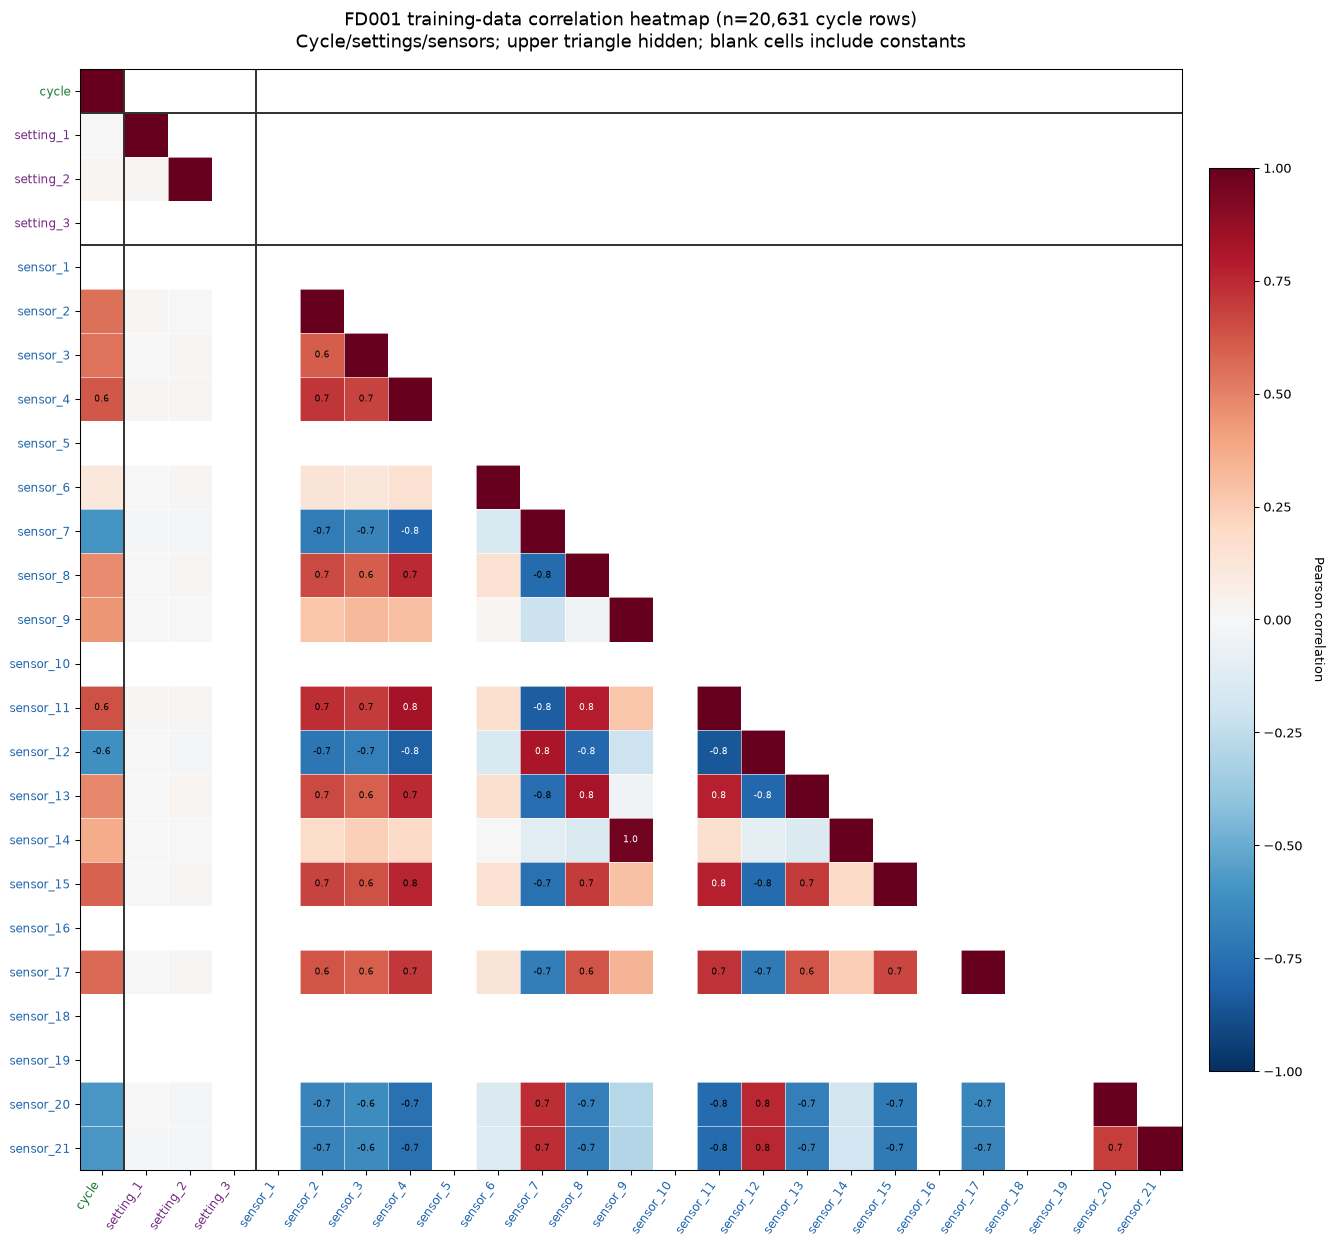

In [7]:
# Plot a Pearson-correlation heatmap for FD001 training variables, excluding engine ID.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fd001_columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
fd001_train_for_corr = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=fd001_columns,
)
# Engine ID labels engines rather than measuring an engine condition, so do not correlate it.
correlation_variables = [
    column for column in fd001_columns if column != "engine_id"
]
correlation_matrix = fd001_train_for_corr[correlation_variables].corr(method="pearson")
correlation_values = correlation_matrix.to_numpy()
constant_variables = [
    column for column in correlation_variables
    if fd001_train_for_corr[column].nunique() == 1
]
upper_triangle = np.triu(np.ones_like(correlation_values, dtype=bool), k=1)
masked_cells = upper_triangle | ~np.isfinite(correlation_values)
masked_correlations = np.ma.array(correlation_values, mask=masked_cells)
print("Constant variables (their correlations are undefined):", constant_variables)

fig, ax = plt.subplots(figsize=(16, 13), constrained_layout=True)
image = ax.imshow(
    masked_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    interpolation="nearest",
)
ax.set_xticks(np.arange(len(correlation_variables)))
ax.set_yticks(np.arange(len(correlation_variables)))
ax.set_xticklabels(correlation_variables, rotation=55, ha="right", fontsize=9)
ax.set_yticklabels(correlation_variables, fontsize=9)
ax.set_xticks(np.arange(-0.5, len(correlation_variables), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(correlation_variables), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.45)
ax.tick_params(which="minor", bottom=False, left=False)

# Delineate cycle, operational settings, and sensor measurements.
for boundary in (0.5, 3.5):
    ax.axhline(boundary, color="#333333", linewidth=1.5)
    ax.axvline(boundary, color="#333333", linewidth=1.5)
for index, variable in enumerate(correlation_variables):
    if variable == "cycle":
        color = "#1b7837"
    elif variable.startswith("setting_"):
        color = "#762a83"
    else:
        color = "#2166ac"
    ax.get_xticklabels()[index].set_color(color)
    ax.get_yticklabels()[index].set_color(color)

# Label stronger off-diagonal correlations without overcrowding the full matrix.
for row in range(len(correlation_variables)):
    for col in range(row):
        value = correlation_values[row, col]
        if abs(value) >= 0.6:
            ax.text(
                col, row, f"{value:.1f}",
                ha="center", va="center", fontsize=7,
                color="white" if abs(value) >= 0.78 else "black",
            )

colorbar = fig.colorbar(image, ax=ax, shrink=0.82, pad=0.02)
colorbar.set_label("Pearson correlation", rotation=270, labelpad=18)
ax.set_title(
    f"FD001 training-data correlation heatmap (n={len(fd001_train_for_corr):,} cycle rows)\n"
    "Cycle/settings/sensors; upper triangle hidden; blank cells include constants",
    fontsize=14,
    pad=16,
)
plt.show()


**Discussion.** The heatmap visualizes pairwise Pearson correlations among training variables (excluding engine ID), making strongly correlated sensor groups visible for later feature-selection experiments. Correlation is descriptive and does not by itself establish sensor importance or predictive value.

Selected training-only |r| distance threshold: 0.487
Silhouette score: 0.144
Representatives (6/15 sensors): ['sensor_9', 'sensor_11', 'sensor_2', 'sensor_17', 'sensor_3', 'sensor_6']
RSF comparison (AIC/BIC are not defined for RSF):
                                 C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)    IAE    ISE  AIC  BIC
Model                                                                                                                
Baseline RSF (all sensors)        0.7159                  0.7973       31.9272        37.8754 8.5594 0.9416  N/A  N/A
Correlation representatives RSF   0.7239                  0.8090       31.2478        37.0511 8.3627 0.9171  N/A  N/A
Improvement over baseline (positive C-index/AUC and negative MAE/IAE/ISE differences are favorable):
C-index                   0.007941
Cumulative/Dynamic AUC    0.011684
MAE (cycles)             -0.679382
RMSE (cycles)            -0.824369
IAE                      -0.196617
ISE               

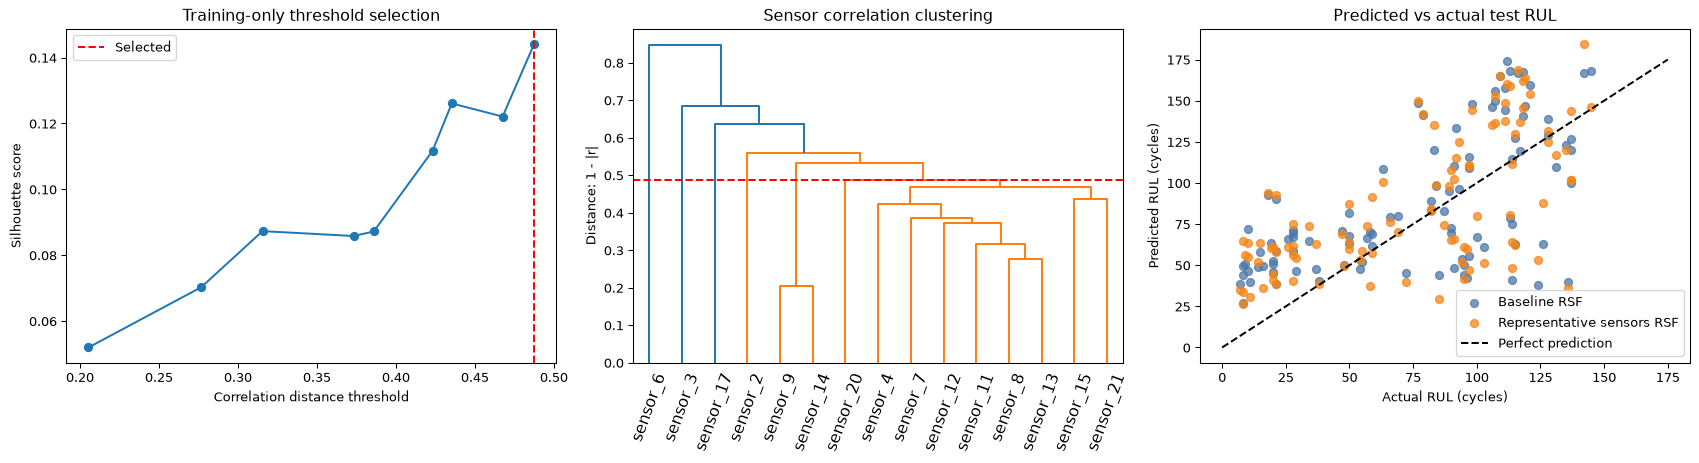

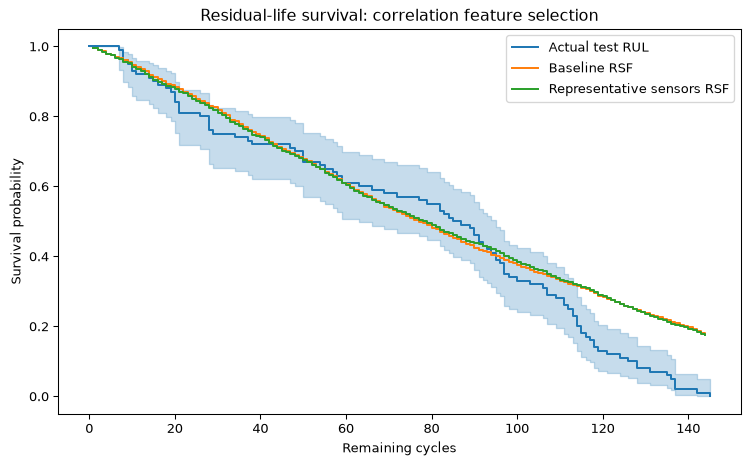

In [8]:
# Compare the baseline FD001 RSF with a training-only hierarchical correlation-cluster sensor-selection RSF.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, silhouette_score
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

fd001_columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
fd001_train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=fd001_columns,
)
fd001_test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=fd001_columns,
)
fd001_actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()
fd001_train_baseline = (
    fd001_train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
fd001_train_end = (
    fd001_train_raw.groupby("engine_id", as_index=False)["cycle"]
    .max().rename(columns={"cycle": "T"})
)
fd001_train_life = fd001_train_baseline[
    ["engine_id", *fd001_columns[5:]]
].merge(fd001_train_end, on="engine_id", validate="one_to_one")
fd001_sensor_cols = [
    column for column in fd001_columns[5:]
    if fd001_train_life[column].nunique() > 1
]
fd001_train_mean = fd001_train_life[fd001_sensor_cols].mean()
fd001_train_sd = fd001_train_life[fd001_sensor_cols].std(ddof=0).replace(0, 1)
fd001_X_train = (
    (fd001_train_life[fd001_sensor_cols] - fd001_train_mean)
    / fd001_train_sd
)
fd001_test_baseline = (
    fd001_test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first().sort_values("engine_id")
)
fd001_test_age = (
    fd001_test_raw.groupby("engine_id")["cycle"].max().sort_index().to_numpy()
)
assert len(fd001_train_raw) == 20631 and len(fd001_train_life) == 100
assert len(fd001_test_baseline) == len(fd001_test_age) == len(fd001_actual_rul) == 100
assert fd001_test_baseline["engine_id"].to_list() == list(range(1, 101))
fd001_X_test = (
    fd001_test_baseline.set_index("engine_id")
    .loc[range(1, 101), fd001_sensor_cols]
    - fd001_train_mean
) / fd001_train_sd
fd001_event = np.ones(len(fd001_train_life), dtype=bool)
fd001_time = fd001_train_life["T"].to_numpy()
fd001_rul_grid = np.arange(0, int(fd001_time.max()) + 1)
fd001_metric_horizons = np.arange(1, int(fd001_actual_rul.max()))
fd001_actual_km = KaplanMeierFitter().fit(
    fd001_actual_rul,
    event_observed=np.ones(len(fd001_actual_rul)),
    label="Actual test RUL",
)
fd001_actual_survival = np.asarray(
    fd001_actual_km.predict(fd001_metric_horizons)
)

# Shared evaluator: transform inputs are learned only from training engines; test RUL is evaluation-only.
def fd001_fit_score_rsf(model_name, X_train_model, X_test_model):
    assert X_train_model.shape[0] == 100 and X_test_model.shape[0] == 100
    model = RandomSurvivalForest(
        n_estimators=300,
        min_samples_leaf=3,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42,
    )
    model.fit(X_train_model, Surv.from_arrays(fd001_event, fd001_time))
    survival_functions = model.predict_survival_function(X_test_model)
    survival_at_age = np.asarray([
        fn(age) for fn, age in zip(survival_functions, fd001_test_age)
    ])
    if np.any(survival_at_age <= 0):
        raise ValueError(f"{model_name}: an engine's test age exceeds RSF survival support.")
    curves = np.vstack([
        fn(np.minimum(age + fd001_rul_grid, fd001_time.max())) / at_age
        for fn, age, at_age in zip(
            survival_functions, fd001_test_age, survival_at_age
        )
    ])
    max_residual_support = np.maximum(0, int(fd001_time.max()) - fd001_test_age)
    curves[fd001_rul_grid[None, :] > max_residual_support[:, None]] = 0.0
    curves = np.clip(curves, 0.0, 1.0)
    predictions = np.trapezoid(curves, fd001_rul_grid, axis=1)
    auc_values = []
    for horizon in fd001_metric_horizons:
        failed_by_horizon = (fd001_actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            auc_values.append(roc_auc_score(failed_by_horizon, 1.0 - curves[:, horizon]))
    mean_survival = curves.mean(axis=0)[fd001_metric_horizons]
    metrics = {
        "Model": model_name,
        "C-index": concordance_index(fd001_actual_rul, predictions),
        "Cumulative/Dynamic AUC": float(np.mean(auc_values)),
        "MAE (cycles)": mean_absolute_error(fd001_actual_rul, predictions),
        "RMSE (cycles)": mean_squared_error(fd001_actual_rul, predictions) ** 0.5,
        "IAE": np.trapezoid(
            np.abs(mean_survival - fd001_actual_survival), fd001_metric_horizons
        ),
        "ISE": np.trapezoid(
            (mean_survival - fd001_actual_survival) ** 2, fd001_metric_horizons
        ),
        "AIC": np.nan,
        "BIC": np.nan,
    }
    return {"metrics": metrics, "curves": curves, "predictions": predictions, "model": model}

fd001_rsf_baseline = fd001_fit_score_rsf(
    "Baseline RSF (all sensors)", fd001_X_train, fd001_X_test
)

# Cluster sensors by 1 - |Pearson r|; select the threshold by training-only silhouette score.
fd001_abs_corr = fd001_X_train.corr().abs().to_numpy()
fd001_sensor_distance = 1.0 - fd001_abs_corr
np.fill_diagonal(fd001_sensor_distance, 0.0)
fd001_linkage = linkage(
    squareform(fd001_sensor_distance, checks=False), method="average"
)
fd001_threshold_rows = []
# Bound the data-driven search to thresholds <= 0.5 so clusters merge only at distance <= 0.5.
for threshold in np.unique(fd001_linkage[:, 2]):
    if not 0 < threshold <= 0.5:
        continue
    labels = fcluster(fd001_linkage, t=float(threshold), criterion="distance")
    cluster_count = len(np.unique(labels))
    if 1 < cluster_count < len(fd001_sensor_cols):
        score = silhouette_score(
            fd001_sensor_distance, labels, metric="precomputed"
        )
        fd001_threshold_rows.append({
            "threshold": float(threshold),
            "clusters": cluster_count,
            "silhouette": score,
            "labels": labels,
        })
if not fd001_threshold_rows:
    raise ValueError("No valid hierarchical clustering thresholds were found.")
fd001_threshold_results = pd.DataFrame(fd001_threshold_rows)
fd001_best_threshold = fd001_threshold_results.sort_values(
    ["silhouette", "threshold"], ascending=[False, True]
).iloc[0]
fd001_selected_labels = fd001_best_threshold["labels"]
fd001_representative_sensors = []
for cluster_id in np.unique(fd001_selected_labels):
    members = np.flatnonzero(fd001_selected_labels == cluster_id)
    within_corr = fd001_abs_corr[np.ix_(members, members)].copy()
    np.fill_diagonal(within_corr, 0.0)
    centrality = within_corr.mean(axis=1) if len(members) > 1 else np.zeros(1)
    selected_index = members[int(np.argmax(centrality))]
    fd001_representative_sensors.append(fd001_sensor_cols[selected_index])
fd001_X_train_corr = fd001_X_train[fd001_representative_sensors]
fd001_X_test_corr = fd001_X_test[fd001_representative_sensors]
fd001_rsf_corr = fd001_fit_score_rsf(
    "Correlation representatives RSF", fd001_X_train_corr, fd001_X_test_corr
)
fd001_corr_comparison = pd.DataFrame([
    fd001_rsf_baseline["metrics"], fd001_rsf_corr["metrics"]
]).set_index("Model")
print("Selected training-only |r| distance threshold:", round(float(fd001_best_threshold["threshold"]), 3))
print("Silhouette score:", round(float(fd001_best_threshold["silhouette"]), 3))
print("Representatives (", len(fd001_representative_sensors), "/", len(fd001_sensor_cols), " sensors): ",
      fd001_representative_sensors, sep="")
print("RSF comparison (AIC/BIC are not defined for RSF):")
print(fd001_corr_comparison.to_string(float_format=lambda value: f"{value:.4f}", na_rep="N/A"))
print("Improvement over baseline (positive C-index/AUC and negative MAE/IAE/ISE differences are favorable):")
print((fd001_corr_comparison.loc["Correlation representatives RSF", ["C-index", "Cumulative/Dynamic AUC", "MAE (cycles)", "RMSE (cycles)", "IAE", "ISE"]]
       - fd001_corr_comparison.loc["Baseline RSF (all sensors)", ["C-index", "Cumulative/Dynamic AUC", "MAE (cycles)", "RMSE (cycles)", "IAE", "ISE"]]).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(fd001_threshold_results["threshold"], fd001_threshold_results["silhouette"], marker="o")
axes[0].axvline(float(fd001_best_threshold["threshold"]), color="red", linestyle="--", label="Selected")
axes[0].set(title="Training-only threshold selection", xlabel="Correlation distance threshold", ylabel="Silhouette score")
axes[0].legend()
dendrogram(fd001_linkage, labels=fd001_sensor_cols, ax=axes[1], leaf_rotation=70)
axes[1].axhline(float(fd001_best_threshold["threshold"]), color="red", linestyle="--")
axes[1].set(title="Sensor correlation clustering", ylabel="Distance: 1 - |r|")
for model_name, result, color in [
    ("Baseline RSF", fd001_rsf_baseline, "#4c78a8"),
    ("Representative sensors RSF", fd001_rsf_corr, "#f58518"),
]:
    axes[2].scatter(
        fd001_actual_rul, result["predictions"], alpha=0.75, label=model_name, color=color
    )
limit = max(int(fd001_actual_rul.max()), int(np.ceil(fd001_rsf_baseline["predictions"].max())))
axes[2].plot([0, limit], [0, limit], "k--", label="Perfect prediction")
axes[2].set(title="Predicted vs actual test RUL", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
axes[2].legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
fd001_actual_km.plot_survival_function(ax=ax, ci_show=True)
for name, result in [("Baseline RSF", fd001_rsf_baseline), ("Representative sensors RSF", fd001_rsf_corr)]:
    ax.step(fd001_metric_horizons, result["curves"].mean(axis=0)[fd001_metric_horizons],
            where="post", label=name)
ax.set(title="Residual-life survival: correlation feature selection", xlabel="Remaining cycles", ylabel="Survival probability")
ax.legend()
plt.tight_layout()
plt.show()


**Discussion.** Hierarchical clustering selected six representatives from 15 candidate sensors using training data. The reduced-sensor RSF has test C-index 0.7239, MAE 31.25 cycles, and RMSE 37.05 cycles versus 0.7159, 31.93, and 37.88 for the baseline RSF. This is a modest improvement on these measures; the reported silhouette score (0.144) indicates weak cluster separation.

PCA suitability: KMO=0.928; Bartlett chi-square(105)=815.36, p=2.45e-110.
Retained 10/15 PCs; cumulative variance=0.917; Kaiser eigenvalues > 1: 2.
Selected K-means k=2; training silhouette=0.342.
K-means diagnostics by k:
 k  inertia  silhouette  calinski_harabasz  davies_bouldin
 2  806.872       0.342             69.061           1.136
 3  715.493       0.195             44.737           1.741
 4  619.895       0.220             39.005           1.570
 5  577.913       0.166             32.777           1.624
 6  543.796       0.141             28.753           1.772
 7  519.559       0.128             25.535           1.890
Permutation test of best silhouette against independently shuffled PC columns (99 permutations; max over k): p=0.140. This tests cluster structure beyond the shuffled-marginal null, not predictive significance.
RSF comparison (AIC/BIC are not defined for RSF):
                                 C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)    IAE   

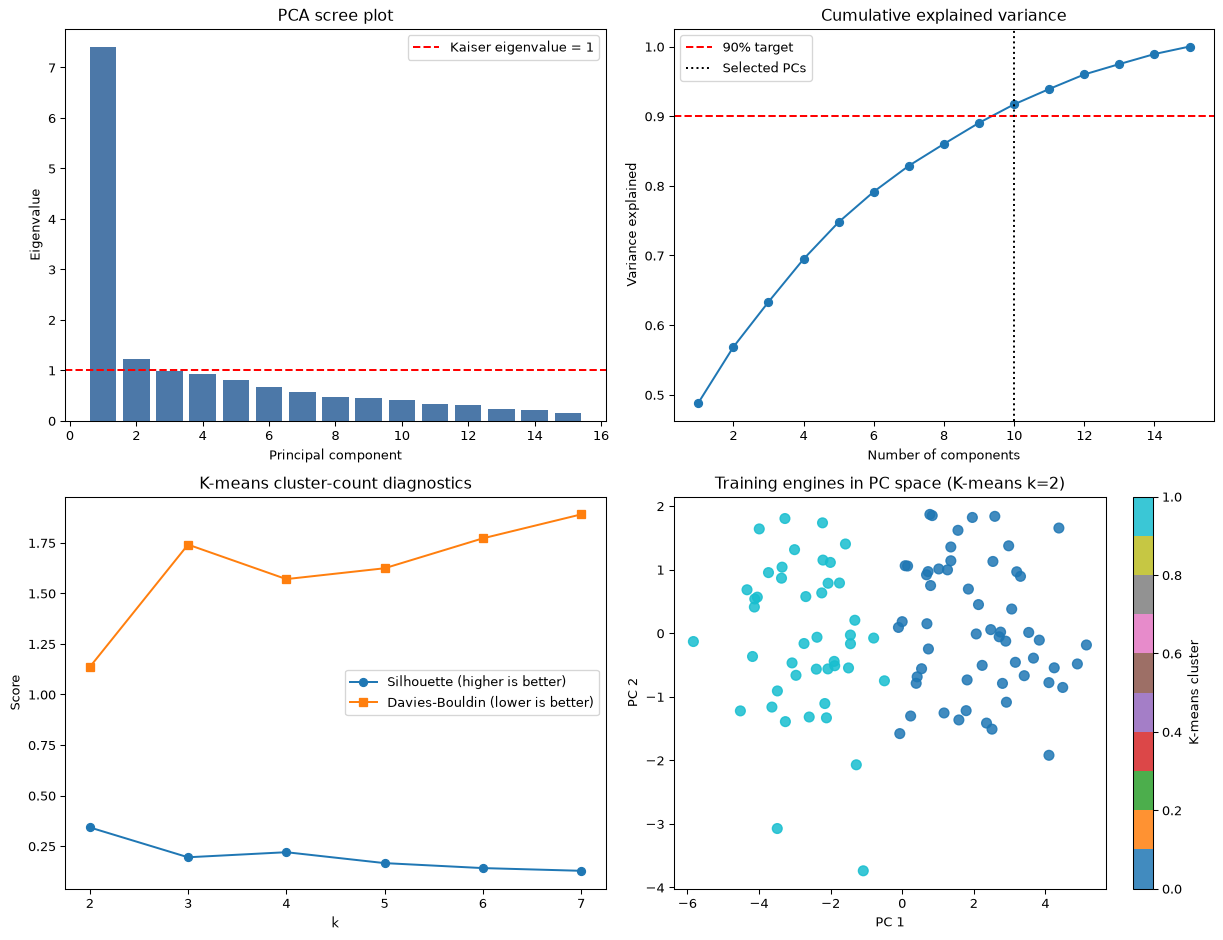

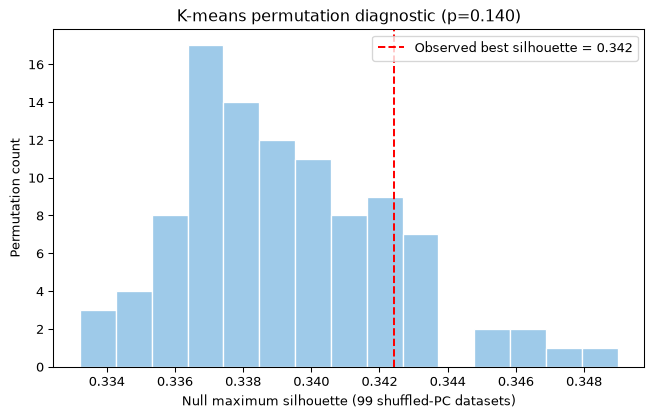

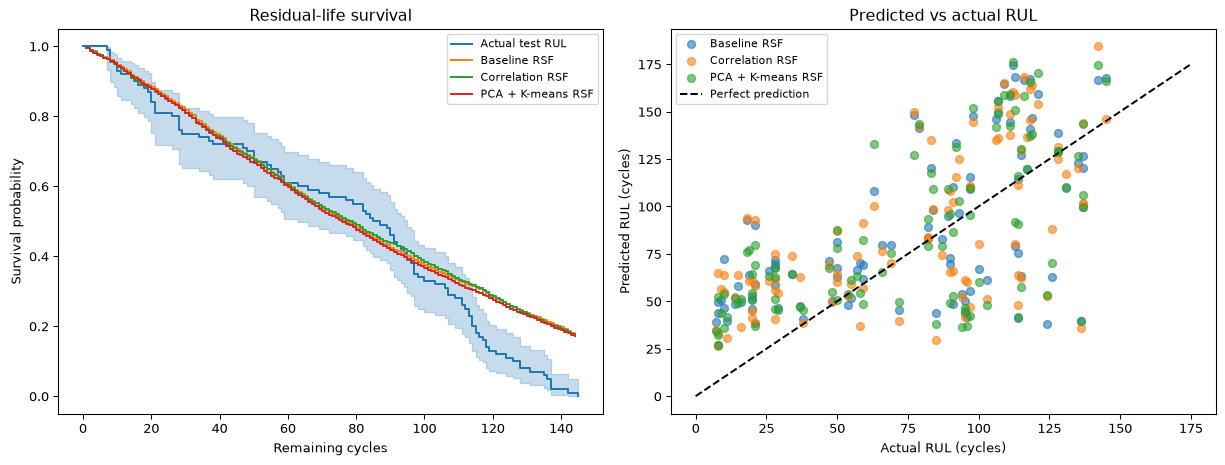

In [9]:
# Fit PCA plus K-means on FD001 training engines and compare transformed-only RSF with prior variants.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    mean_absolute_error,
    roc_auc_score,
    silhouette_score,
)

# PCA suitability statistics: Bartlett sphericity test and overall Kaiser-Meyer-Olkin measure.
fd001_corr_for_pca = fd001_X_train.corr().to_numpy()
fd001_precision = np.linalg.inv(fd001_corr_for_pca)
fd001_partial_corr = -fd001_precision / np.sqrt(
    np.outer(np.diag(fd001_precision), np.diag(fd001_precision))
)
np.fill_diagonal(fd001_partial_corr, 0.0)
fd001_corr_offdiag = fd001_corr_for_pca.copy()
np.fill_diagonal(fd001_corr_offdiag, 0.0)
fd001_kmo = np.sum(fd001_corr_offdiag ** 2) / (
    np.sum(fd001_corr_offdiag ** 2) + np.sum(fd001_partial_corr ** 2)
)
fd001_sign, fd001_logdet = np.linalg.slogdet(fd001_corr_for_pca)
if fd001_sign <= 0:
    raise ValueError("Training sensor correlation matrix is not positive definite.")
fd001_n, fd001_p = fd001_X_train.shape
fd001_bartlett_stat = -(
    fd001_n - 1 - (2 * fd001_p + 5) / 6
) * fd001_logdet
fd001_bartlett_df = fd001_p * (fd001_p - 1) // 2
fd001_bartlett_p = chi2.sf(fd001_bartlett_stat, fd001_bartlett_df)
print(f"PCA suitability: KMO={fd001_kmo:.3f}; Bartlett chi-square({fd001_bartlett_df})="
      f"{fd001_bartlett_stat:.2f}, p={fd001_bartlett_p:.3g}.")

# Retain the smallest training-only PCA representation reaching 90% cumulative variance.
fd001_pca_full = PCA().fit(fd001_X_train)
fd001_cumulative_variance = np.cumsum(fd001_pca_full.explained_variance_ratio_)
fd001_n_components = int(np.searchsorted(fd001_cumulative_variance, 0.90) + 1)
fd001_pca = PCA(n_components=fd001_n_components, svd_solver="full")
fd001_pc_train_array = fd001_pca.fit_transform(fd001_X_train)
fd001_pc_test_array = fd001_pca.transform(fd001_X_test)
fd001_pc_columns = [f"PC_{index + 1}" for index in range(fd001_n_components)]
fd001_pc_train = pd.DataFrame(fd001_pc_train_array, columns=fd001_pc_columns)
fd001_pc_test = pd.DataFrame(fd001_pc_test_array, columns=fd001_pc_columns)
print(f"Retained {fd001_n_components}/{fd001_p} PCs; cumulative variance="
      f"{fd001_cumulative_variance[fd001_n_components - 1]:.3f}; "
      f"Kaiser eigenvalues > 1: {int(np.sum(fd001_pca_full.explained_variance_ > 1))}.")

# Select K-means k by training-only silhouette; report complementary cluster diagnostics.
fd001_kmeans_diagnostics = []
fd001_kmeans_candidates = range(2, min(7, fd001_n - 1) + 1)
for cluster_count in fd001_kmeans_candidates:
    candidate = KMeans(n_clusters=cluster_count, n_init=30, random_state=42)
    candidate_labels = candidate.fit_predict(fd001_pc_train)
    fd001_kmeans_diagnostics.append({
        "k": cluster_count,
        "inertia": candidate.inertia_,
        "silhouette": silhouette_score(fd001_pc_train, candidate_labels),
        "calinski_harabasz": calinski_harabasz_score(fd001_pc_train, candidate_labels),
        "davies_bouldin": davies_bouldin_score(fd001_pc_train, candidate_labels),
    })
fd001_kmeans_diagnostics = pd.DataFrame(fd001_kmeans_diagnostics)

# Permutation test for selected silhouette, comparing with independently shuffled PC columns.
# The max across k is used for each permutation to account for searching over cluster counts.
fd001_observed_best_silhouette = float(fd001_kmeans_diagnostics["silhouette"].max())
fd001_permutation_rng = np.random.default_rng(42)
fd001_null_best_silhouettes = []
for _ in range(99):
    permuted_pc_scores = np.column_stack([
        fd001_permutation_rng.permutation(fd001_pc_train_array[:, component])
        for component in range(fd001_pc_train_array.shape[1])
    ])
    null_silhouettes = []
    for cluster_count in fd001_kmeans_candidates:
        null_labels = KMeans(
            n_clusters=cluster_count, n_init=5, random_state=42
        ).fit_predict(permuted_pc_scores)
        null_silhouettes.append(
            silhouette_score(permuted_pc_scores, null_labels)
        )
    fd001_null_best_silhouettes.append(max(null_silhouettes))
fd001_kmeans_permutation_p = (
    1 + np.sum(np.asarray(fd001_null_best_silhouettes) >= fd001_observed_best_silhouette)
) / (1 + len(fd001_null_best_silhouettes))
fd001_best_k = int(fd001_kmeans_diagnostics.loc[
    fd001_kmeans_diagnostics["silhouette"].idxmax(), "k"
])
fd001_kmeans = KMeans(n_clusters=fd001_best_k, n_init=30, random_state=42)
fd001_kmeans_train_labels = fd001_kmeans.fit_predict(fd001_pc_train)
fd001_kmeans_test_labels = fd001_kmeans.predict(fd001_pc_test)
fd001_kmeans_columns = [f"KMeans_{index}" for index in range(fd001_best_k)]
fd001_kmeans_train_onehot = pd.DataFrame(
    np.eye(fd001_best_k)[fd001_kmeans_train_labels], columns=fd001_kmeans_columns
)
fd001_kmeans_test_onehot = pd.DataFrame(
    np.eye(fd001_best_k)[fd001_kmeans_test_labels], columns=fd001_kmeans_columns
)
fd001_X_train_pca_kmeans = pd.concat(
    [fd001_pc_train.reset_index(drop=True), fd001_kmeans_train_onehot], axis=1
)
fd001_X_test_pca_kmeans = pd.concat(
    [fd001_pc_test.reset_index(drop=True), fd001_kmeans_test_onehot], axis=1
)
fd001_rsf_pca_kmeans = fd001_fit_score_rsf(
    "PCA + K-means RSF", fd001_X_train_pca_kmeans, fd001_X_test_pca_kmeans
)
fd001_pca_kmeans_comparison = pd.DataFrame([
    fd001_rsf_baseline["metrics"], fd001_rsf_corr["metrics"],
    fd001_rsf_pca_kmeans["metrics"],
]).set_index("Model")
print(f"Selected K-means k={fd001_best_k}; training silhouette="
      f"{fd001_kmeans_diagnostics.loc[fd001_kmeans_diagnostics.k == fd001_best_k, 'silhouette'].iloc[0]:.3f}.")
print("K-means diagnostics by k:")
print(fd001_kmeans_diagnostics.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(
    "Permutation test of best silhouette against independently shuffled PC columns "
    f"(99 permutations; max over k): p={fd001_kmeans_permutation_p:.3f}. "
    "This tests cluster structure beyond the shuffled-marginal null, not predictive significance."
)
print("RSF comparison (AIC/BIC are not defined for RSF):")
print(fd001_pca_kmeans_comparison.to_string(float_format=lambda value: f"{value:.4f}", na_rep="N/A"))

# Visualize PCA eigenvalues/variance, K-means selection, and the first two PC scores.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
component_numbers = np.arange(1, fd001_p + 1)
axes[0, 0].bar(component_numbers, fd001_pca_full.explained_variance_, color="#4c78a8")
axes[0, 0].axhline(1.0, color="red", linestyle="--", label="Kaiser eigenvalue = 1")
axes[0, 0].set(title="PCA scree plot", xlabel="Principal component", ylabel="Eigenvalue")
axes[0, 0].legend()
axes[0, 1].plot(component_numbers, fd001_cumulative_variance, marker="o")
axes[0, 1].axhline(0.90, color="red", linestyle="--", label="90% target")
axes[0, 1].axvline(fd001_n_components, color="black", linestyle=":", label="Selected PCs")
axes[0, 1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Variance explained")
axes[0, 1].legend()
axes[1, 0].plot(fd001_kmeans_diagnostics.k, fd001_kmeans_diagnostics.silhouette, marker="o", label="Silhouette (higher is better)")
axes[1, 0].plot(fd001_kmeans_diagnostics.k, fd001_kmeans_diagnostics.davies_bouldin, marker="s", label="Davies-Bouldin (lower is better)")
axes[1, 0].set(title="K-means cluster-count diagnostics", xlabel="k", ylabel="Score")
axes[1, 0].legend()
scatter = axes[1, 1].scatter(
    fd001_pc_train_array[:, 0], fd001_pc_train_array[:, 1],
    c=fd001_kmeans_train_labels, cmap="tab10", s=55, alpha=0.85,
)
axes[1, 1].set(title=f"Training engines in PC space (K-means k={fd001_best_k})", xlabel="PC 1", ylabel="PC 2")
fig.colorbar(scatter, ax=axes[1, 1], label="K-means cluster")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(fd001_null_best_silhouettes, bins=15, color="#9ecae9", edgecolor="white")
ax.axvline(
    fd001_observed_best_silhouette, color="red", linestyle="--",
    label=f"Observed best silhouette = {fd001_observed_best_silhouette:.3f}",
)
ax.set(
    title=f"K-means permutation diagnostic (p={fd001_kmeans_permutation_p:.3f})",
    xlabel="Null maximum silhouette (99 shuffled-PC datasets)",
    ylabel="Permutation count",
)
ax.legend()
fig.tight_layout()
plt.show()

# Compare residual survival and engine-level RUL for baseline and all transformed RSFs.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fd001_actual_km.plot_survival_function(ax=axes[0], ci_show=True)
for name, result in [
    ("Baseline RSF", fd001_rsf_baseline),
    ("Correlation RSF", fd001_rsf_corr),
    ("PCA + K-means RSF", fd001_rsf_pca_kmeans),
]:
    axes[0].step(fd001_metric_horizons, result["curves"].mean(axis=0)[fd001_metric_horizons], where="post", label=name)
    axes[1].scatter(fd001_actual_rul, result["predictions"], alpha=0.6, label=name)
limit = max(int(fd001_actual_rul.max()), int(np.ceil(fd001_rsf_baseline["predictions"].max())))
axes[1].plot([0, limit], [0, limit], "k--", label="Perfect prediction")
axes[0].set(title="Residual-life survival", xlabel="Remaining cycles", ylabel="Survival probability")
axes[1].set(title="Predicted vs actual RUL", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Discussion.** PCA diagnostics support dimension reduction (KMO 0.928; Bartlett test p?2.45?10????); 10 components retain 91.7% of variance. K-means selects two clusters with silhouette 0.342, but the permutation result (p=0.140) does not show clear separation beyond the shuffled-marginal null. The transformed RSF has C-index 0.7147, MAE 31.11 cycles, and RMSE 37.19 cycles; these results do not show a consistent predictive gain over the other RSF variants.

Full-covariance GMM diagnostics (fit on standardized sensors, no PCA):
 components     BIC     AIC  converged  iterations
          1 4003.36 3651.66       True           2
          2 3716.76 3010.76       True          21
          3 4336.56 3276.26       True           7
          4 4420.07 3005.46       True           4
          5 4730.01 2961.10       True           7
          6 4937.95 2814.74       True           2
Selected components=2; converged=True; iterations=21; training silhouette=0.181.
Training component sizes: [81, 19]
Minimum covariance eigenvalues: [0.001, 0.001294]
Mean normalized posterior entropy (0=confident, 1=uncertain): 0.006
RSF comparison (AIC/BIC are not defined for RSF):
                                 C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)    IAE    ISE  AIC  BIC
Model                                                                                                                
Baseline RSF (all sensors)        0.7159            

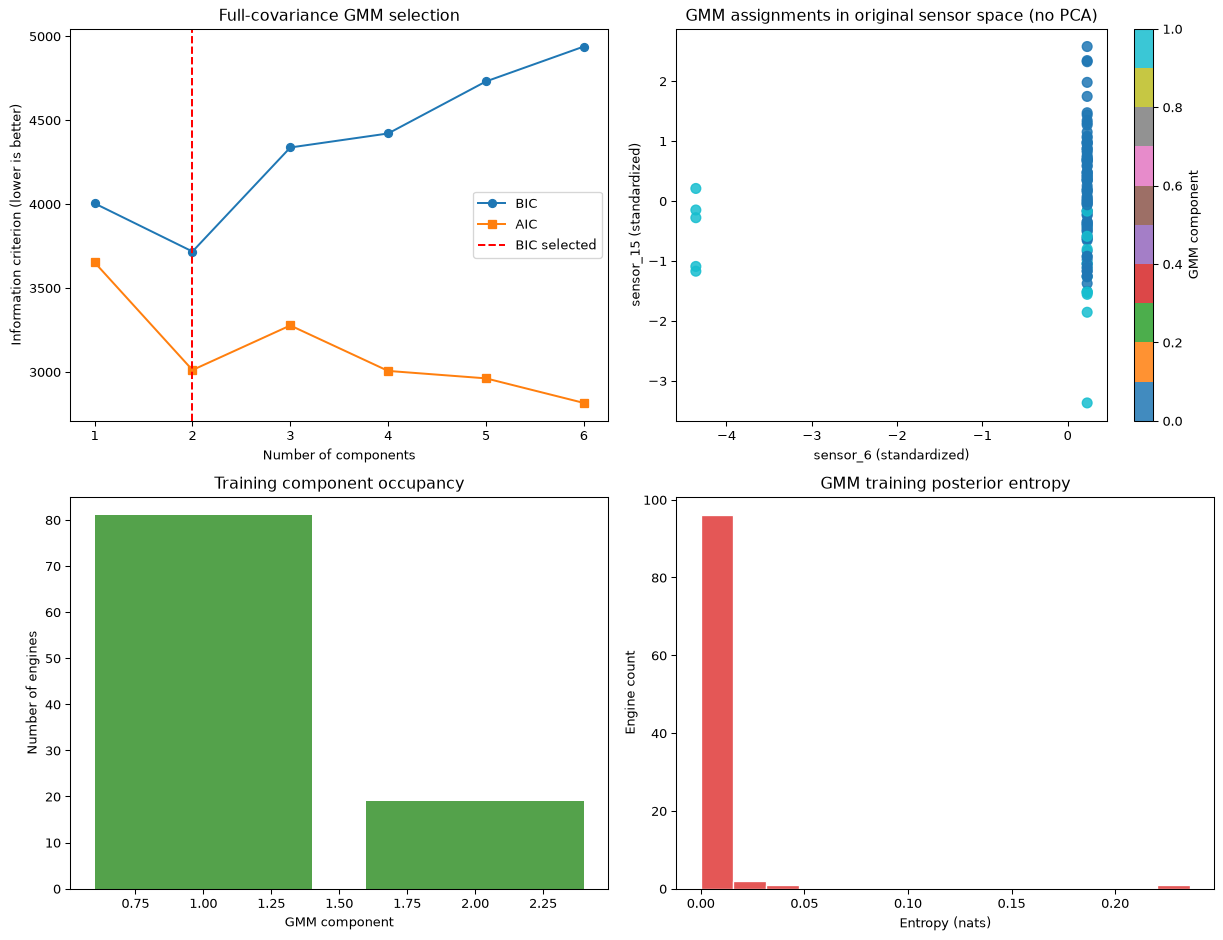

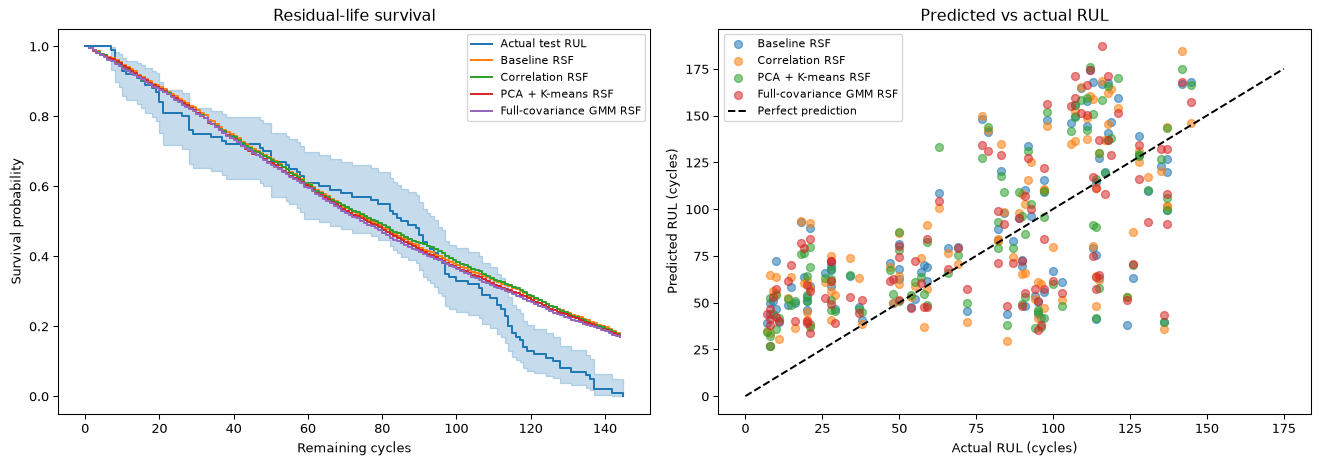

In [10]:
# Fit a full-covariance Gaussian mixture on FD001 sensors without PCA and compare its RSF with prior models.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Select the number of full-covariance mixture components by training-only BIC.
fd001_gmm_candidates = []
fd001_gmm_models = {}
for component_count in range(1, 7):
    candidate = GaussianMixture(
        n_components=component_count,
        covariance_type="full",
        reg_covar=1e-3,
        n_init=5,
        random_state=42,
    )
    candidate.fit(fd001_X_train)
    fd001_gmm_models[component_count] = candidate
    fd001_gmm_candidates.append({
        "components": component_count,
        "BIC": candidate.bic(fd001_X_train),
        "AIC": candidate.aic(fd001_X_train),
        "converged": candidate.converged_,
        "iterations": candidate.n_iter_,
    })
fd001_gmm_diagnostics = pd.DataFrame(fd001_gmm_candidates)
fd001_best_components = int(
    fd001_gmm_diagnostics.loc[fd001_gmm_diagnostics["BIC"].idxmin(), "components"]
)
fd001_gmm = fd001_gmm_models[fd001_best_components]
fd001_gmm_train_prob = fd001_gmm.predict_proba(fd001_X_train)
fd001_gmm_test_prob = fd001_gmm.predict_proba(fd001_X_test)
fd001_gmm_columns = [f"GMM_probability_{index + 1}" for index in range(fd001_best_components)]
fd001_X_train_gmm = pd.DataFrame(fd001_gmm_train_prob, columns=fd001_gmm_columns)
fd001_X_test_gmm = pd.DataFrame(fd001_gmm_test_prob, columns=fd001_gmm_columns)
fd001_rsf_gmm = fd001_fit_score_rsf(
    "Full-covariance GMM RSF", fd001_X_train_gmm, fd001_X_test_gmm
)
fd001_all_comparison = pd.DataFrame([
    fd001_rsf_baseline["metrics"],
    fd001_rsf_corr["metrics"],
    fd001_rsf_pca_kmeans["metrics"],
    fd001_rsf_gmm["metrics"],
]).set_index("Model")

# Diagnose convergence, occupancy, posterior ambiguity, and positive-definite fitted covariances.
fd001_gmm_labels = fd001_gmm.predict(fd001_X_train)
fd001_component_sizes = np.bincount(fd001_gmm_labels, minlength=fd001_best_components)
fd001_min_covariance_eigenvalues = np.asarray([
    np.linalg.eigvalsh(covariance).min()
    for covariance in fd001_gmm.covariances_
])
fd001_train_entropy = -np.sum(
    fd001_gmm_train_prob * np.log(np.clip(fd001_gmm_train_prob, 1e-15, 1.0)),
    axis=1,
)
fd001_avg_normalized_entropy = (
    float(np.mean(fd001_train_entropy / np.log(fd001_best_components)))
    if fd001_best_components > 1 else 0.0
)
fd001_gmm_silhouette = (
    silhouette_score(fd001_X_train, fd001_gmm_labels)
    if 1 < fd001_best_components < len(fd001_X_train) else np.nan
)
print("Full-covariance GMM diagnostics (fit on standardized sensors, no PCA):")
print(fd001_gmm_diagnostics.to_string(index=False, float_format=lambda value: f"{value:.2f}"))
print(f"Selected components={fd001_best_components}; converged={fd001_gmm.converged_}; "
      f"iterations={fd001_gmm.n_iter_}; training silhouette={fd001_gmm_silhouette:.3f}.")
print("Training component sizes:", fd001_component_sizes.tolist())
print("Minimum covariance eigenvalues:", np.round(fd001_min_covariance_eigenvalues, 6).tolist())
print(f"Mean normalized posterior entropy (0=confident, 1=uncertain): {fd001_avg_normalized_entropy:.3f}")
print("RSF comparison (AIC/BIC are not defined for RSF):")
print(fd001_all_comparison.to_string(float_format=lambda value: f"{value:.4f}", na_rep="N/A"))
print("Improvement of each transformed RSF vs baseline:")
score_columns = ["C-index", "Cumulative/Dynamic AUC", "MAE (cycles)", "IAE", "ISE"]
fd001_improvement = fd001_all_comparison[score_columns].subtract(
    fd001_all_comparison.loc["Baseline RSF (all sensors)", score_columns]
)
print(fd001_improvement.to_string(float_format=lambda value: f"{value:+.4f}"))

# Visualize mixture-selection criteria, component assignments without PCA, and posterior uncertainty.
fd001_scatter_features = fd001_X_train.var().sort_values(ascending=False).index[:2].tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].plot(fd001_gmm_diagnostics.components, fd001_gmm_diagnostics.BIC, marker="o", label="BIC")
axes[0, 0].plot(fd001_gmm_diagnostics.components, fd001_gmm_diagnostics.AIC, marker="s", label="AIC")
axes[0, 0].axvline(fd001_best_components, color="red", linestyle="--", label="BIC selected")
axes[0, 0].set(title="Full-covariance GMM selection", xlabel="Number of components", ylabel="Information criterion (lower is better)")
axes[0, 0].legend()
scatter = axes[0, 1].scatter(
    fd001_X_train[fd001_scatter_features[0]],
    fd001_X_train[fd001_scatter_features[1]],
    c=fd001_gmm_labels, cmap="tab10", s=55, alpha=0.85,
)
axes[0, 1].set(title="GMM assignments in original sensor space (no PCA)", xlabel=f"{fd001_scatter_features[0]} (standardized)", ylabel=f"{fd001_scatter_features[1]} (standardized)")
fig.colorbar(scatter, ax=axes[0, 1], label="GMM component")
axes[1, 0].bar(np.arange(1, fd001_best_components + 1), fd001_component_sizes, color="#54a24b")
axes[1, 0].set(title="Training component occupancy", xlabel="GMM component", ylabel="Number of engines")
axes[1, 1].hist(fd001_train_entropy, bins=15, color="#e45756", edgecolor="white")
axes[1, 1].set(title="GMM training posterior entropy", xlabel="Entropy (nats)", ylabel="Engine count")
fig.tight_layout()
plt.show()

# Compare survival curves and per-engine lifetime predictions for every RSF representation.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fd001_actual_km.plot_survival_function(ax=axes[0], ci_show=True)
for name, result in [
    ("Baseline RSF", fd001_rsf_baseline),
    ("Correlation RSF", fd001_rsf_corr),
    ("PCA + K-means RSF", fd001_rsf_pca_kmeans),
    ("Full-covariance GMM RSF", fd001_rsf_gmm),
]:
    axes[0].step(fd001_metric_horizons, result["curves"].mean(axis=0)[fd001_metric_horizons], where="post", label=name)
    axes[1].scatter(fd001_actual_rul, result["predictions"], alpha=0.55, label=name)
limit = max(int(fd001_actual_rul.max()), int(np.ceil(fd001_rsf_baseline["predictions"].max())))
axes[1].plot([0, limit], [0, limit], "k--", label="Perfect prediction")
axes[0].set(title="Residual-life survival", xlabel="Remaining cycles", ylabel="Survival probability")
axes[1].set(title="Predicted vs actual RUL", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Discussion.** The full-covariance Gaussian mixture converged with two components selected by BIC; its training silhouette is 0.181, indicating limited separation. Its RSF test scores (C-index 0.7148, dynamic AUC 0.8145, MAE 31.81 cycles, RMSE 37.46 cycles) do not show a clear improvement over the baseline RSF. The component diagnostics describe the mixture fit, not a supervised prediction test.

XGBoost: trained on 20,631 cycle rows from 100 engines; test predictions on 100 engines.
LightGBM: trained on 20,631 cycle rows from 100 engines; test predictions on 100 engines.
FD001 test comparison (100 engines). Boosters use final-cycle sensors and all 20,631 training rows; grouped CV keeps engines intact.
RSF references retain the earlier cycle-1 sensor setup with survival conditioned on each test engine's observed age.
                                 C-index  Cumulative/Dynamic AUC  MAE (cycles)  RMSE (cycles)     IAE    ISE  AIC  BIC
Model                                                                                                                 
Baseline RSF (all sensors)        0.7159                  0.7973       31.9272        37.8754  8.5594 0.9416  N/A  N/A
Correlation representatives RSF   0.7239                  0.8090       31.2478        37.0511  8.3627 0.9171  N/A  N/A
PCA + K-means RSF                 0.7147                  0.8024       31.1089        37.1911  

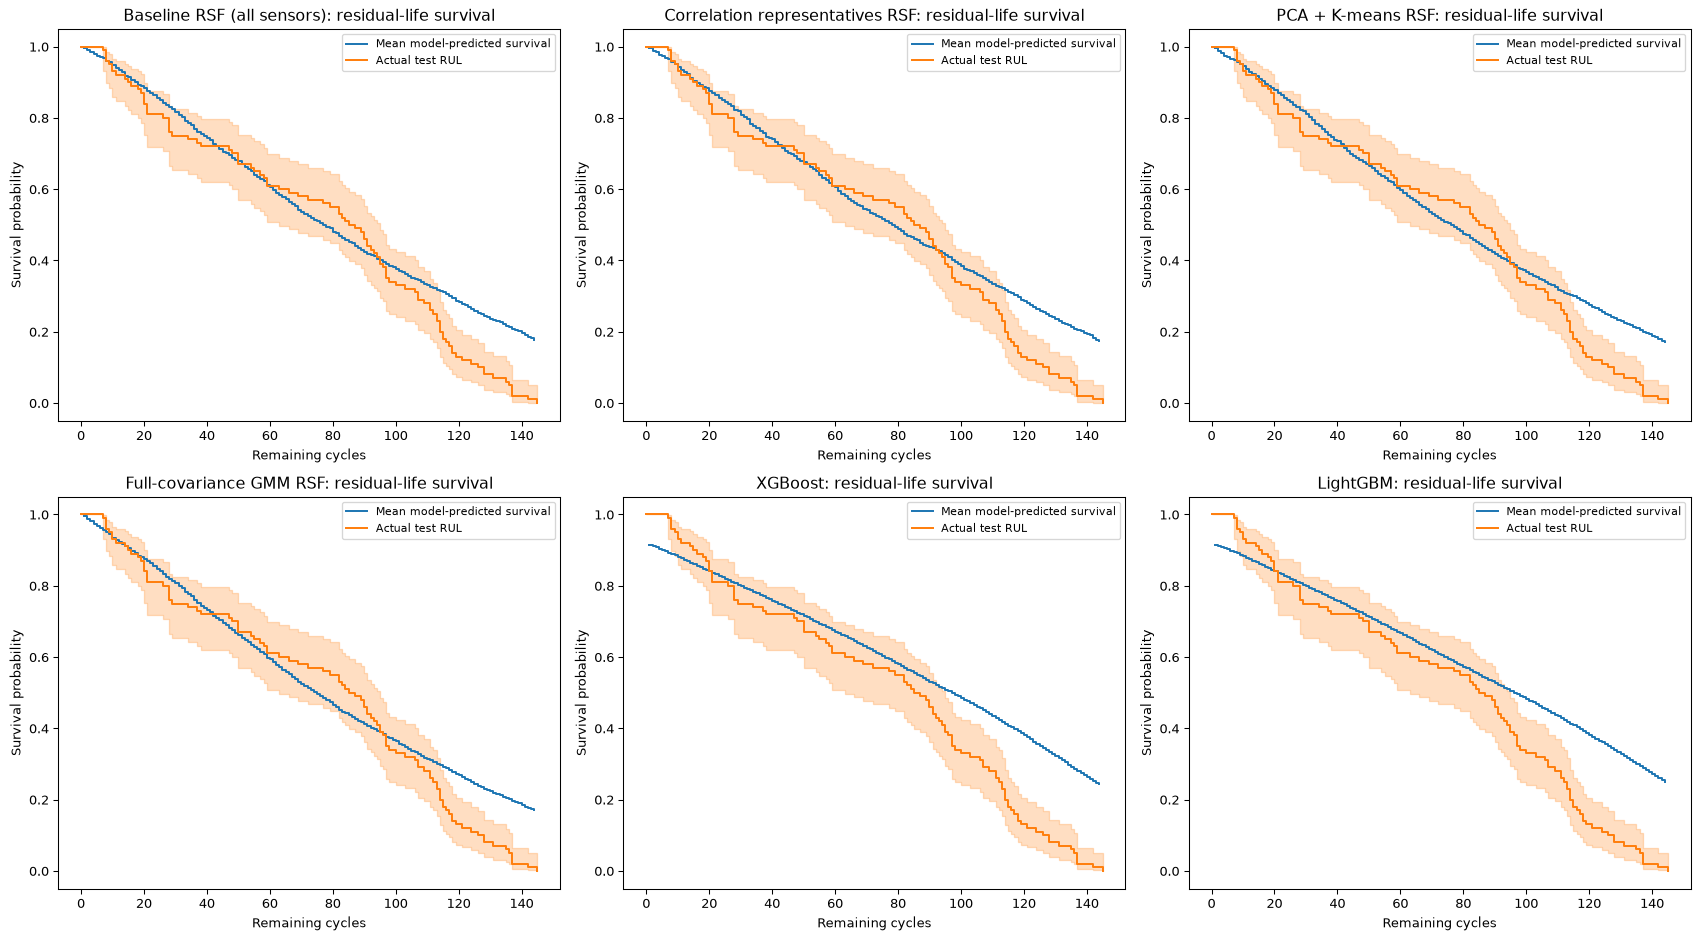

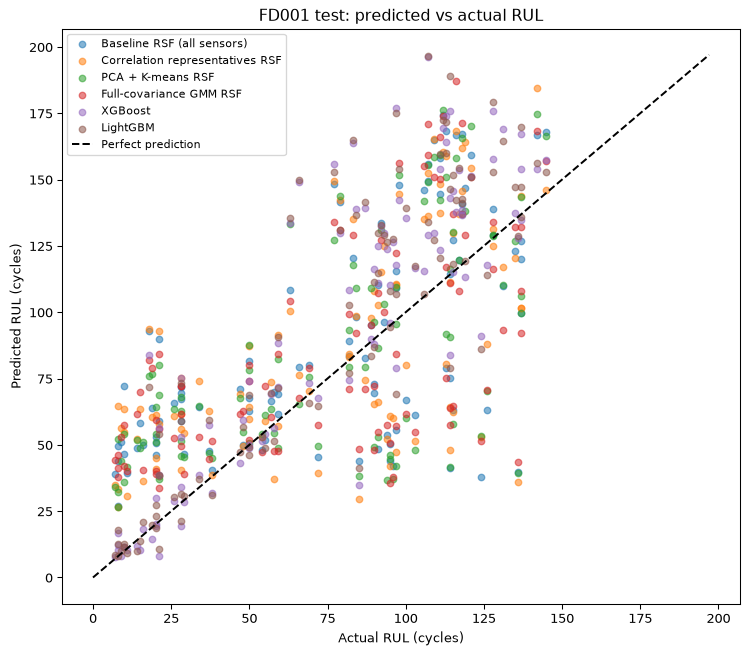

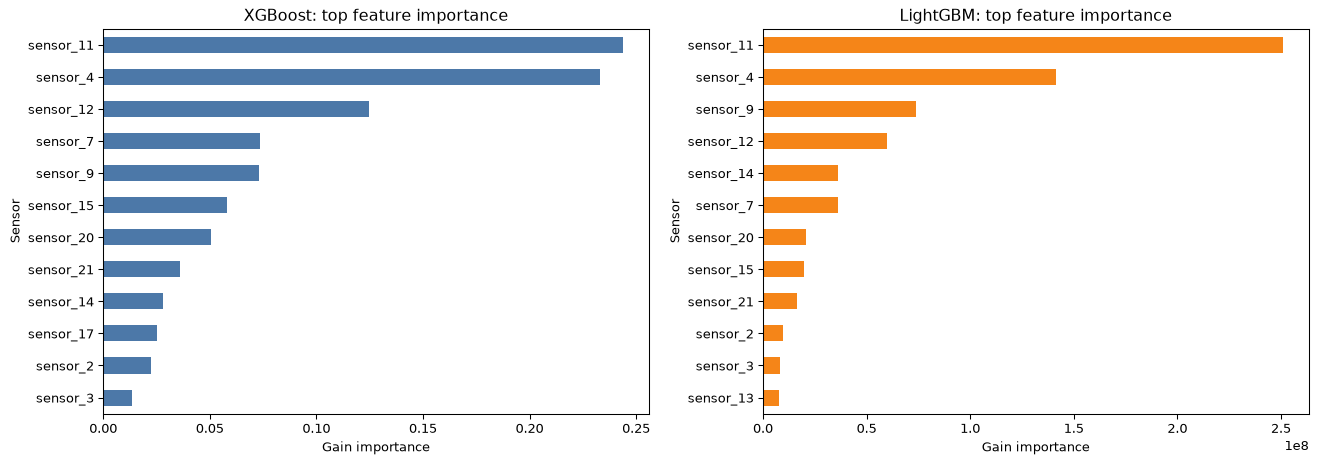

In [11]:
# Predict FD001 test-engine RUL with XGBoost and LightGBM and compare against prior RSF models.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
import lightgbm as lgb
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Train boosters on cycle-level remaining life (T - cycle); test at each engine's last observed cycle.
train_end = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.copy()
train_rows["remaining_life"] = (
    train_rows["engine_id"].map(train_end) - train_rows["cycle"]
).astype(float)
cycle1 = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
nonconstant_sensors = [
    column for column in columns[5:]
    if cycle1[column].nunique() > 1
]
X_rows = train_rows[nonconstant_sensors].astype(float)
y_rows = train_rows["remaining_life"].to_numpy()
groups = train_rows["engine_id"].to_numpy()
test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)
X_test = test_last[nonconstant_sensors].astype(float)
test_age = test_last["cycle"].to_numpy()
assert len(train_raw) == 20631 and train_raw["engine_id"].nunique() == 100
assert len(test_last) == len(actual_rul) == 100
assert test_last["engine_id"].tolist() == list(range(1, 101))

# Grouped out-of-fold predictions keep rows from the same training engine in one fold.
# Their held-out residuals provide a simple empirical uncertainty distribution for survival plots.
folds = GroupKFold(n_splits=5)
booster_specs = {
    "XGBoost": lambda: xgb.XGBRegressor(
        objective="reg:squarederror", n_estimators=250, max_depth=3,
        learning_rate=0.04, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=5.0, min_child_weight=5, random_state=42,
        n_jobs=-1, verbosity=0, importance_type="gain",
    ),
    "LightGBM": lambda: lgb.LGBMRegressor(
        objective="regression", n_estimators=250, learning_rate=0.04,
        num_leaves=15, max_depth=-1, min_child_samples=30,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        reg_lambda=5.0, random_state=42, n_jobs=-1, verbosity=-1,
        importance_type="gain",
    ),
}
booster_predictions = {}
booster_oof_residuals = {}
booster_models = {}
for model_name, make_model in booster_specs.items():
    oof_prediction = np.full(len(X_rows), np.nan)
    for train_index, valid_index in folds.split(X_rows, y_rows, groups):
        fold_model = make_model()
        fold_model.fit(X_rows.iloc[train_index], y_rows[train_index])
        oof_prediction[valid_index] = fold_model.predict(X_rows.iloc[valid_index])
    if not np.isfinite(oof_prediction).all():
        raise ValueError(f"{model_name} grouped out-of-fold predictions are incomplete.")
    model = make_model()
    model.fit(X_rows, y_rows)
    booster_models[model_name] = model
    booster_predictions[model_name] = np.maximum(0.0, model.predict(X_test))
    booster_oof_residuals[model_name] = y_rows - oof_prediction
    print(
        f"{model_name}: trained on {len(X_rows):,} cycle rows from "
        f"{len(np.unique(groups))} engines; test predictions on {len(X_test)} engines."
    )

# Refit the earlier RSF baselines on one cycle-1 row per engine for an apples-to-apples reference.
train_base = cycle1[["engine_id", *nonconstant_sensors]].copy()
train_lifetime = train_base.merge(
    train_end.rename("T"), left_on="engine_id", right_index=True, validate="one_to_one"
)
train_mean = train_lifetime[nonconstant_sensors].mean()
train_sd = train_lifetime[nonconstant_sensors].std(ddof=0).replace(0, 1)
X_train_sensors = (train_lifetime[nonconstant_sensors] - train_mean) / train_sd
test_base = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first().sort_values("engine_id")
)
X_test_first = (
    (test_base.set_index("engine_id").loc[range(1, 101), nonconstant_sensors] - train_mean)
    / train_sd
)
# Keep prior RSF variants consistent: cycle-1 covariates with conditional survival at test_age.
X_test_sensors = X_test_first
train_T = train_lifetime["T"].to_numpy()
train_event = np.ones(len(train_T), dtype=bool)
rsf_outcomes = Surv.from_arrays(train_event, train_T)

# Fit training-only feature-selection and clustering steps exactly as in the earlier notebook chunks.
abs_corr = X_train_sensors.corr().abs().to_numpy()
distance = 1.0 - abs_corr
np.fill_diagonal(distance, 0.0)
hierarchy = linkage(squareform(distance, checks=False), method="average")
threshold_candidates = []
for threshold in np.unique(hierarchy[:, 2]):
    if not 0 < threshold <= 0.5:
        continue
    labels = fcluster(hierarchy, t=float(threshold), criterion="distance")
    cluster_count = len(np.unique(labels))
    if 1 < cluster_count < len(nonconstant_sensors):
        from sklearn.metrics import silhouette_score
        threshold_candidates.append((
            silhouette_score(distance, labels, metric="precomputed"),
            float(threshold),
            labels,
        ))
if not threshold_candidates:
    raise ValueError("Could not form valid correlation clusters for RSF benchmark.")
_, selected_threshold, cluster_labels = max(threshold_candidates, key=lambda row: row[0])
representatives = []
for cluster_id in np.unique(cluster_labels):
    member_indices = np.flatnonzero(cluster_labels == cluster_id)
    within_corr = abs_corr[np.ix_(member_indices, member_indices)].copy()
    np.fill_diagonal(within_corr, 0.0)
    centrality = within_corr.mean(axis=1) if len(member_indices) > 1 else np.zeros(1)
    representatives.append(nonconstant_sensors[member_indices[int(np.argmax(centrality))]])

pca_full = PCA().fit(X_train_sensors)
n_components = int(np.searchsorted(np.cumsum(pca_full.explained_variance_ratio_), 0.90) + 1)
pca = PCA(n_components=n_components, svd_solver="full")
pc_train = pca.fit_transform(X_train_sensors)
pc_test = pca.transform(X_test_sensors)
kmeans_candidates = []
for cluster_count in range(2, 8):
    kmeans_candidate = KMeans(n_clusters=cluster_count, n_init=30, random_state=42)
    labels = kmeans_candidate.fit_predict(pc_train)
    from sklearn.metrics import silhouette_score
    kmeans_candidates.append((silhouette_score(pc_train, labels), cluster_count))
_, selected_k = max(kmeans_candidates)
kmeans = KMeans(n_clusters=selected_k, n_init=30, random_state=42)
kmeans_train_labels = kmeans.fit_predict(pc_train)
kmeans_test_labels = kmeans.predict(pc_test)
X_train_pca_kmeans = np.column_stack([pc_train, np.eye(selected_k)[kmeans_train_labels]])
X_test_pca_kmeans = np.column_stack([pc_test, np.eye(selected_k)[kmeans_test_labels]])

gmm_candidates = []
for component_count in range(1, 7):
    candidate = GaussianMixture(
        n_components=component_count, covariance_type="full",
        reg_covar=1e-3, n_init=5, random_state=42,
    ).fit(X_train_sensors)
    gmm_candidates.append((candidate.bic(X_train_sensors), component_count, candidate))
_, selected_components, gmm = min(gmm_candidates, key=lambda row: row[0])
X_train_gmm = gmm.predict_proba(X_train_sensors)
X_test_gmm = gmm.predict_proba(X_test_sensors)

rsf_inputs = {
    "Baseline RSF (all sensors)": (X_train_sensors, X_test_sensors),
    "Correlation representatives RSF": (
        X_train_sensors[representatives], X_test_sensors[representatives]
    ),
    "PCA + K-means RSF": (X_train_pca_kmeans, X_test_pca_kmeans),
    "Full-covariance GMM RSF": (X_train_gmm, X_test_gmm),
}
rul_grid = np.arange(0, int(train_T.max()) + 1)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_km = KaplanMeierFitter().fit(
    actual_rul, event_observed=np.ones(len(actual_rul)), label="Actual test RUL"
)
actual_survival = np.asarray(actual_km.predict(metric_horizons))
results = []
predicted_curves = {}
predicted_values = {}

def score_rul_predictions(model_name, predictions, survival_curves):
    auc_values = []
    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            auc_values.append(roc_auc_score(failed_by_horizon, 1.0 - survival_curves[:, horizon]))
    mean_survival = survival_curves.mean(axis=0)[metric_horizons]
    results.append({
        "Model": model_name,
        "C-index": concordance_index(actual_rul, predictions),
        "Cumulative/Dynamic AUC": float(np.mean(auc_values)),
        "MAE (cycles)": mean_absolute_error(actual_rul, predictions),
        "RMSE (cycles)": mean_squared_error(actual_rul, predictions) ** 0.5,
        "IAE": np.trapezoid(np.abs(mean_survival - actual_survival), metric_horizons),
        "ISE": np.trapezoid((mean_survival - actual_survival) ** 2, metric_horizons),
        "AIC": np.nan,
        "BIC": np.nan,
    })
    predicted_curves[model_name] = survival_curves
    predicted_values[model_name] = predictions

for model_name, (X_fit, X_predict) in rsf_inputs.items():
    rsf = RandomSurvivalForest(
        n_estimators=300, min_samples_leaf=3, max_features="sqrt",
        n_jobs=-1, random_state=42,
    ).fit(X_fit, rsf_outcomes)
    survival_functions = rsf.predict_survival_function(X_predict)
    at_age = np.asarray([fn(age) for fn, age in zip(survival_functions, test_age)])
    if np.any(at_age <= 0):
        raise ValueError(f"{model_name}: test engine age exceeds fitted survival support.")
    curves = np.vstack([
        fn(np.minimum(age + rul_grid, train_T.max())) / start
        for fn, age, start in zip(survival_functions, test_age, at_age)
    ])
    support = np.maximum(0, int(train_T.max()) - test_age)
    curves[rul_grid[None, :] > support[:, None]] = 0.0
    curves = np.clip(curves, 0.0, 1.0)
    predictions = np.trapezoid(curves, rul_grid, axis=1)
    score_rul_predictions(model_name, predictions, curves)

# For regression boosters, obtain an empirical residual distribution from engine-grouped OOF fits.
# This yields cohort survival curves without treating the point predictions as certain outcomes.
for model_name in booster_specs:
    predictions = booster_predictions[model_name]
    residuals = booster_oof_residuals[model_name]
    simulated_rul = np.maximum(0.0, predictions[:, None] + residuals[None, :])
    curves = np.column_stack([
        np.mean(simulated_rul > horizon, axis=1) for horizon in rul_grid
    ])
    score_rul_predictions(model_name, predictions, curves)

comparison = pd.DataFrame(results).set_index("Model")
print("FD001 test comparison (100 engines). Boosters use final-cycle sensors and all 20,631 training rows; grouped CV keeps engines intact.")
print("RSF references retain the earlier cycle-1 sensor setup with survival conditioned on each test engine's observed age.")
print(comparison.to_string(float_format=lambda value: f"{value:.4f}", na_rep="N/A"))
print("AIC/BIC are N/A: these RSF and boosted-tree predictions are not likelihood-based parametric fits.")
print("Booster IAE/ISE use grouped out-of-fold training residuals to form empirical residual-life survival curves.")
print("Cumulative/dynamic AUC uses each model's predicted cumulative failure risk at each RUL horizon.")

# Plot actual versus predicted lifetime and survival, plus feature importance for both boosters.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
model_names = list(predicted_curves)
for axis, model_name in zip(axes[0], model_names[:3]):
    axis.step(
        metric_horizons,
        predicted_curves[model_name].mean(axis=0)[metric_horizons],
        where="post", label="Mean model-predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(title=f"{model_name}: residual-life survival", xlabel="Remaining cycles", ylabel="Survival probability")
    axis.legend(fontsize=8)
for axis, model_name in zip(axes[1], model_names[3:]):
    axis.step(
        metric_horizons,
        predicted_curves[model_name].mean(axis=0)[metric_horizons],
        where="post", label="Mean model-predicted survival",
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True)
    axis.set(title=f"{model_name}: residual-life survival", xlabel="Remaining cycles", ylabel="Survival probability")
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
limit = max(int(actual_rul.max()), max(int(np.ceil(value.max())) for value in predicted_values.values()))
for model_name, predictions in predicted_values.items():
    ax.scatter(actual_rul, predictions, alpha=0.55, s=24, label=model_name)
ax.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
ax.set(title="FD001 test: predicted vs actual RUL", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, model_name in zip(axes, ("XGBoost", "LightGBM")):
    model = booster_models[model_name]
    importance = pd.Series(model.feature_importances_, index=nonconstant_sensors).sort_values()
    importance.tail(12).plot.barh(ax=axis, color="#4c78a8" if model_name == "XGBoost" else "#f58518")
    axis.set(title=f"{model_name}: top feature importance", xlabel="Gain importance", ylabel="Sensor")
fig.tight_layout()
plt.show()


**Discussion.** Using final-cycle sensor measurements, XGBoost and LightGBM outperform the earlier RSF baselines on test ranking and error in this experiment: XGBoost C-index 0.8345 / MAE 23.04 / RMSE 32.21 cycles and LightGBM 0.8336 / 23.45 / 32.75. Their features and prediction setup differ from the earlier cycle-1 RSF reference, so this is a useful benchmark rather than a perfectly controlled model-only comparison.

Tuning XGBoost: Optuna (30 trials)...
Tuning XGBoost: Adaptive Greedy Search (30 evaluations)...
Tuning LightGBM: Optuna (30 trials)...
Tuning LightGBM: Adaptive Greedy Search (30 evaluations)...

Best parameters and engine-grouped pseudo-censoring CV MAE:
                                 Best CV MAE                                                                                                                                                                                                                                Best params
Model    Search                                                                                                                                                                                                                                                                        
XGBoost  Optuna                    27.514476  {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.08932774169703606, 'min_child_weight': 10, 'subsample': 0.867006944446638, 'cols

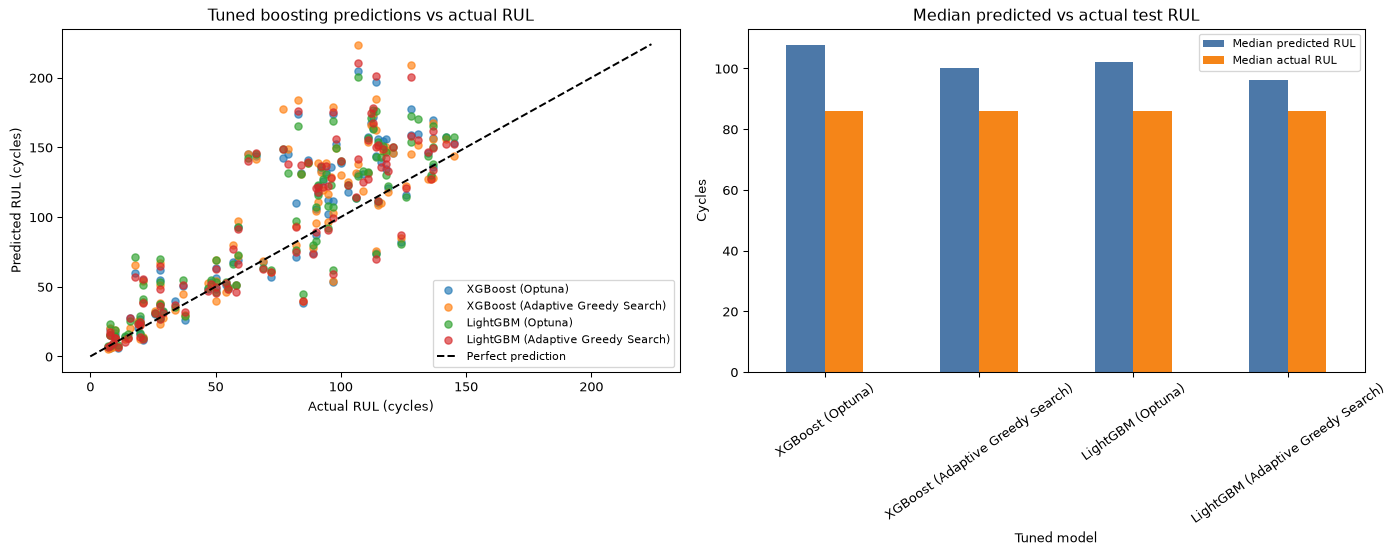

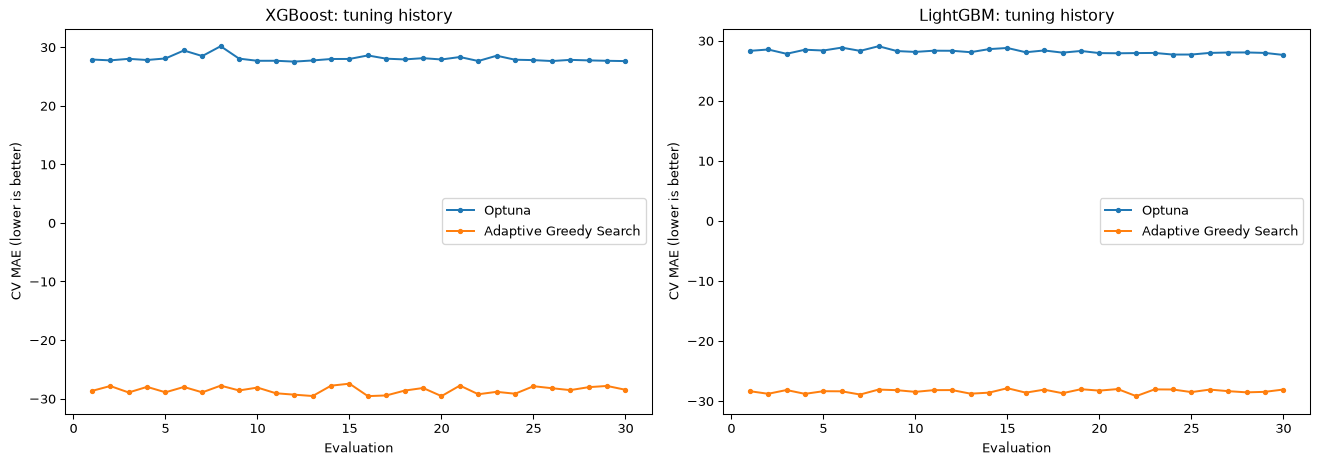

In [12]:
# Tune XGBoost and LightGBM with 30 Optuna trials and 30 adaptive-greedy evaluations, then compare test RUL medians.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
import lightgbm as lgb
from ags import AdaptiveGreedySearch
from lifelines.utils import concordance_index
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold

optuna.logging.set_verbosity(optuna.logging.WARNING)
columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Train on all engine-cycle sensor records; each cycle's target is remaining cycles to failure.
train_end = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.reset_index(drop=True).copy()
train_rows["remaining_life"] = (
    train_rows["engine_id"].map(train_end) - train_rows["cycle"]
).astype(float)
cycle1 = (
    train_rows.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
feature_cols = [
    column for column in columns[5:]
    if cycle1[column].nunique() > 1
]
X_train = train_rows[feature_cols].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
groups = train_rows["engine_id"].to_numpy()
test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test = test_last[feature_cols].astype(float)
actual_test_age = test_last["cycle"].to_numpy()
assert len(train_rows) == 20631 and train_rows["engine_id"].nunique() == 100
assert len(test_last) == len(actual_rul) == 100
assert test_last["engine_id"].tolist() == list(range(1, 101))

# Validate at several pseudo-censoring points per held-out engine; no engine appears in both sides of a fold.
# These cut points mimic test-time prediction: the held-out sensor row precedes its engine's failure.
cut_fractions = (0.25, 0.45, 0.65, 0.85)
row_lookup = {
    int(engine_id): group.set_index("cycle").index.to_series()
    for engine_id, group in train_rows.groupby("engine_id", sort=False)
}
row_positions = {
    int(engine_id): {
        int(cycle): int(position)
        for position, cycle in zip(group.index, group["cycle"])
    }
    for engine_id, group in train_rows.groupby("engine_id", sort=False)
}
cv_splits = []
for fit_indices, held_cycle_indices in GroupKFold(n_splits=3).split(
    X_train, y_train, groups
):
    held_engines = np.unique(groups[held_cycle_indices])
    validation_indices = []
    for engine_id in held_engines:
        lifetime = int(train_end.loc[engine_id])
        for fraction in cut_fractions:
            cutoff_cycle = min(lifetime - 1, max(1, int(round(lifetime * fraction))))
            validation_indices.append(row_positions[int(engine_id)][cutoff_cycle])
    validation_indices = np.asarray(validation_indices, dtype=int)
    if np.intersect1d(groups[fit_indices], groups[validation_indices]).size:
        raise AssertionError("Engine leakage found in grouped validation split.")
    cv_splits.append((fit_indices, validation_indices))

# Score every candidate by equal-fold MAE on pseudo-censored held-out engines.
def evaluate_params(model_name, params):
    fold_mae = []
    for fit_indices, validation_indices in cv_splits:
        if model_name == "XGBoost":
            model = xgb.XGBRegressor(
                objective="reg:squarederror", n_jobs=1, verbosity=0,
                random_state=42, **params,
            )
        else:
            model = lgb.LGBMRegressor(
                objective="regression", n_jobs=1, verbosity=-1,
                random_state=42, subsample_freq=1, **params,
            )
        model.fit(X_train.iloc[fit_indices], y_train[fit_indices])
        prediction = np.maximum(
            0.0, model.predict(X_train.iloc[validation_indices])
        )
        fold_mae.append(mean_absolute_error(y_train[validation_indices], prediction))
    return float(np.mean(fold_mae))

# Define the same bounded model families for Optuna's continuous sampling and AGS's finite search.
def suggest_optuna_params(trial, model_name):
    if model_name == "XGBoost":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 350, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 7),
            "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.65, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
            "gamma": trial.suggest_float("gamma", 0.0, 3.0),
        }
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 350, step=50),
        "num_leaves": trial.suggest_int("num_leaves", 7, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 70),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
    }

ags_grids = {
    "XGBoost": {
        "n_estimators": [100, 150, 200, 250, 300, 350],
        "max_depth": [2, 3, 4, 5, 6, 7],
        "learning_rate": [0.015, 0.03, 0.06, 0.10, 0.15],
        "min_child_weight": [1, 3, 5, 8, 10],
        "subsample": [0.65, 0.75, 0.85, 1.0],
        "colsample_bytree": [0.65, 0.75, 0.85, 1.0],
        "reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
        "gamma": [0.0, 0.25, 0.75, 1.5, 3.0],
    },
    "LightGBM": {
        "n_estimators": [100, 150, 200, 250, 300, 350],
        "num_leaves": [7, 15, 23, 31, 47, 63],
        "max_depth": [3, 4, 5, 6, 8, 10],
        "learning_rate": [0.015, 0.03, 0.06, 0.10, 0.15],
        "min_child_samples": [10, 20, 30, 45, 60, 70],
        "subsample": [0.65, 0.75, 0.85, 1.0],
        "colsample_bytree": [0.65, 0.75, 0.85, 1.0],
        "reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
    },
}

best_configs = {}
search_records = []
for model_name in ("XGBoost", "LightGBM"):
    print(f"Tuning {model_name}: Optuna (30 trials)...")
    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=42),
    )
    study.optimize(
        lambda trial: evaluate_params(
            model_name, suggest_optuna_params(trial, model_name)
        ),
        n_trials=30,
        show_progress_bar=False,
        n_jobs=1,
    )
    best_configs[(model_name, "Optuna") ] = dict(study.best_params)
    search_records.append({
        "Model": model_name,
        "Search": "Optuna",
        "Best CV MAE": study.best_value,
        "Best params": dict(study.best_params),
        "Trial scores": [trial.value for trial in study.trials],
    })

    print(f"Tuning {model_name}: Adaptive Greedy Search (30 evaluations)...")
    if model_name == "XGBoost":
        base_estimator = xgb.XGBRegressor(
            objective="reg:squarederror", n_jobs=1, verbosity=0, random_state=42
        )
    else:
        base_estimator = lgb.LGBMRegressor(
            objective="regression", n_jobs=1, verbosity=-1,
            subsample_freq=1, random_state=42,
        )

    class PrecomputedGroupFolds:
        def __init__(self, splits):
            self.splits = splits

        def split(self, X, y=None):
            return iter(self.splits)

        def get_n_splits(self, X=None, y=None):
            return len(self.splits)

    ags_search = AdaptiveGreedySearch(
        estimator=base_estimator,
        param_grid=ags_grids[model_name],
        cv=3,
        scoring="neg_mean_absolute_error",
        max_evaluations=30,
        n_climbers=4,
        n_jobs=1,
        random_state=42,
        enable_pruning=False,
        candidate_pool_size=64,
    )
    # AGS 3.7.1 does not accept groups in fit; provide precomputed engine-disjoint folds.
    ags_search._cv_splitter = PrecomputedGroupFolds(cv_splits)
    ags_search.fit(X_train, y_train)
    ags_params = dict(ags_search.best_params)
    best_configs[(model_name, "Adaptive Greedy Search")] = ags_params
    search_records.append({
        "Model": model_name,
        "Search": "Adaptive Greedy Search",
        "Best CV MAE": -float(ags_search.best_score),
        "Best params": ags_params,
        "Trial scores": [
            float(value) for value in ags_search.completed_evaluations.values()
        ],
    })

search_summary = pd.DataFrame([
    {key: value for key, value in record.items() if key != "Trial scores"}
    for record in search_records
]).set_index(["Model", "Search"])
print("\nBest parameters and engine-grouped pseudo-censoring CV MAE:")
print(search_summary.to_string())

# Refit each best configuration on every training cycle and predict final-cycle test rows.
tuned_models = {}
test_predictions = {}
for (model_name, search_name), params in best_configs.items():
    if model_name == "XGBoost":
        model = xgb.XGBRegressor(
            objective="reg:squarederror", n_jobs=-1, verbosity=0,
            random_state=42, **params,
        )
    else:
        model = lgb.LGBMRegressor(
            objective="regression", n_jobs=-1, verbosity=-1,
            random_state=42, subsample_freq=1, **params,
        )
    model.fit(X_train, y_train)
    prediction = np.maximum(0.0, model.predict(X_test))
    key = f"{model_name} ({search_name})"
    tuned_models[key] = model
    test_predictions[key] = prediction

# Compare each engine's predicted RUL to its aligned RUL target; report median prediction versus median actual.
result_rows = []
for model_name, prediction in test_predictions.items():
    result_rows.append({
        "Model": model_name,
        "Median predicted RUL": float(np.median(prediction)),
        "Median actual RUL": float(np.median(actual_rul)),
        "Median difference": float(np.median(prediction) - np.median(actual_rul)),
        "Median absolute error": float(np.median(np.abs(prediction - actual_rul))),
        "MAE": mean_absolute_error(actual_rul, prediction),
        "RMSE": mean_squared_error(actual_rul, prediction) ** 0.5,
        "C-index": concordance_index(actual_rul, prediction),
    })
test_comparison = pd.DataFrame(result_rows).set_index("Model")
print("\nFD001 test-set summary (predictions are aligned to the 100 RUL_FD001 entries):")
print(test_comparison.to_string(float_format=lambda value: f"{value:.2f}"))

per_engine_predictions = pd.DataFrame({
    "engine_id": test_last["engine_id"],
    "last_observed_cycle": actual_test_age,
    "actual_RUL": actual_rul,
    **test_predictions,
})
print("\nPer-engine comparison, first 10 engines:")
print(per_engine_predictions.head(10).to_string(index=False, float_format=lambda value: f"{value:.1f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for model_name, prediction in test_predictions.items():
    axes[0].scatter(actual_rul, prediction, alpha=0.65, s=30, label=model_name)
limit = max(int(actual_rul.max()), int(np.ceil(max(pred.max() for pred in test_predictions.values()))))
axes[0].plot([0, limit], [0, limit], "k--", label="Perfect prediction")
axes[0].set(
    title="Tuned boosting predictions vs actual RUL",
    xlabel="Actual RUL (cycles)",
    ylabel="Predicted RUL (cycles)",
)
axes[0].legend(fontsize=8)

median_rows = test_comparison[["Median predicted RUL", "Median actual RUL"]]
median_rows.plot.bar(ax=axes[1], color=["#4c78a8", "#f58518"])
axes[1].set(
    title="Median predicted vs actual test RUL",
    ylabel="Cycles",
    xlabel="Tuned model",
)
axes[1].tick_params(axis="x", labelrotation=35)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, model_name in zip(axes, ("XGBoost", "LightGBM")):
    for record in search_records:
        if record["Model"] == model_name:
            scores = record["Trial scores"]
            axis.plot(np.arange(1, len(scores) + 1), scores, marker=".", label=record["Search"])
    axis.set(title=f"{model_name}: tuning history", xlabel="Evaluation", ylabel="CV MAE (lower is better)")
    axis.legend()
fig.tight_layout()
plt.show()


**Discussion.** The 30-trial Optuna and 30-evaluation Adaptive Greedy Search runs tune both boosters with engine-grouped validation. LightGBM Optuna has the lowest test MAE (23.70 cycles) and RMSE (32.31 cycles) among these four tuned variants; LightGBM Adaptive Greedy is closest to the actual test median RUL of 86 cycles (predicted median 96.20). Median error, MAE, and RMSE capture different aspects of performance.

                                   Median RUL (cycles)
Actual                                           86.00
XGBoost (Optuna)                                107.76
XGBoost (Adaptive Greedy Search)                100.01
LightGBM (Optuna)                               102.12
LightGBM (Adaptive Greedy Search)                96.20

FD001 test-engine prediction metrics (100 engines):
                                   MAE (cycles)  RMSE (cycles)  C-index
XGBoost (Optuna)                         24.576         33.579    0.833
XGBoost (Adaptive Greedy Search)         25.052         35.637    0.821
LightGBM (Optuna)                        23.698         32.307    0.837
LightGBM (Adaptive Greedy Search)        24.517         34.366    0.832


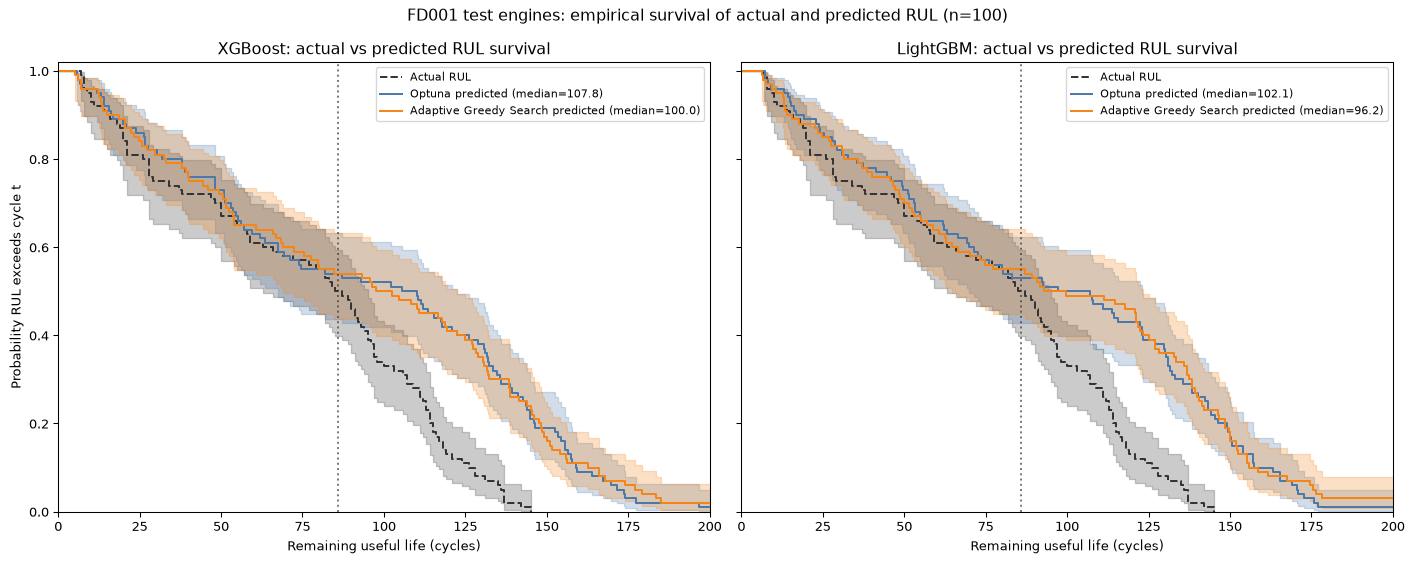

In [13]:
# Compare empirical survival of the four cell-12 predicted RUL distributions against actual FD001 test RUL.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
import lightgbm as lgb
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.metrics import mean_absolute_error, mean_squared_error

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Refit cell 12's selected configurations; use every training cycle and each test engine's last row.
train_end = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.copy()
train_rows["remaining_life"] = (
    train_rows["engine_id"].map(train_end) - train_rows["cycle"]
).astype(float)
cycle1 = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
feature_cols = [
    column for column in columns[5:]
    if cycle1[column].nunique() > 1
]
X_train = train_rows[feature_cols].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test = test_last[feature_cols].astype(float)
assert len(test_last) == len(actual_rul) == 100

best_parameters = {
    "XGBoost (Optuna)": {
        "n_estimators": 100, "max_depth": 6,
        "learning_rate": 0.08932774169703606, "min_child_weight": 10,
        "subsample": 0.867006944446638,
        "colsample_bytree": 0.7698165177110632,
        "reg_lambda": 3.7998757602349316, "gamma": 1.091725594507963,
    },
    "XGBoost (Adaptive Greedy Search)": {
        "n_estimators": 300, "max_depth": 5, "learning_rate": 0.1,
        "min_child_weight": 1, "subsample": 0.65,
        "colsample_bytree": 1.0, "reg_lambda": 2.0, "gamma": 0.75,
    },
    "LightGBM (Optuna)": {
        "n_estimators": 150, "num_leaves": 44, "max_depth": 6,
        "learning_rate": 0.030633933113171533, "min_child_samples": 48,
        "subsample": 0.8001372419555672,
        "colsample_bytree": 0.7932375424315637,
        "reg_lambda": 0.2459681648015436,
    },
    "LightGBM (Adaptive Greedy Search)": {
        "n_estimators": 150, "num_leaves": 47, "max_depth": 8,
        "learning_rate": 0.1, "min_child_samples": 10,
        "subsample": 1.0, "colsample_bytree": 1.0,
        "reg_lambda": 20.0,
    },
}

predicted_rul = {}
for model_name, params in best_parameters.items():
    if model_name.startswith("XGBoost"):
        model = xgb.XGBRegressor(
            objective="reg:squarederror", n_jobs=-1, verbosity=0,
            random_state=42, importance_type="gain", **params,
        )
    else:
        model = lgb.LGBMRegressor(
            objective="regression", n_jobs=-1, verbosity=-1,
            random_state=42, subsample_freq=1,
            importance_type="gain", **params,
        )
    model.fit(X_train, y_train)
    predicted_rul[model_name] = np.maximum(0.0, model.predict(X_test))

# These are empirical population survival curves of observed/predicted RUL values,
# not individual conditional survival functions from the regression boosters.
actual_km = KaplanMeierFitter().fit(
    actual_rul, event_observed=np.ones(len(actual_rul)), label="Actual RUL"
)
model_groups = {
    "XGBoost": [name for name in predicted_rul if name.startswith("XGBoost")],
    "LightGBM": [name for name in predicted_rul if name.startswith("LightGBM")],
}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
colors = {
    "Optuna": "#4c78a8",
    "Adaptive Greedy Search": "#f58518",
}
for ax, (family, model_names) in zip(axes, model_groups.items()):
    actual_km.plot_survival_function(
        ax=ax, ci_show=True, color="#333333", linestyle="--"
    )
    for model_name in model_names:
        predicted = predicted_rul[model_name]
        search_name = "Optuna" if "Optuna" in model_name else "Adaptive Greedy Search"
        prediction_km = KaplanMeierFitter().fit(
            predicted,
            event_observed=np.ones(len(predicted)),
            label=f"{search_name} predicted (median={np.median(predicted):.1f})",
        )
        prediction_km.plot_survival_function(
            ax=ax, ci_show=True, color=colors[search_name]
        )
    ax.axvline(np.median(actual_rul), color="#333333", alpha=0.65, linestyle=":")
    ax.set(
        title=f"{family}: actual vs predicted RUL survival",
        xlabel="Remaining useful life (cycles)",
        ylabel="Probability RUL exceeds cycle t",
        xlim=(0, max(int(actual_rul.max()), 200)),
        ylim=(0, 1.02),
    )
    ax.legend(fontsize=8)
fig.suptitle("FD001 test engines: empirical survival of actual and predicted RUL (n=100)")
fig.tight_layout()
plt.show()

median_comparison = pd.DataFrame({
    "Median RUL (cycles)": {
        "Actual": float(np.median(actual_rul)),
        **{name: float(np.median(values)) for name, values in predicted_rul.items()},
    }
})
print(median_comparison.to_string(float_format=lambda value: f"{value:.2f}"))

prediction_metrics = pd.DataFrame({
    name: {
        "MAE (cycles)": mean_absolute_error(actual_rul, values),
        "RMSE (cycles)": mean_squared_error(actual_rul, values) ** 0.5,
        "C-index": concordance_index(actual_rul, values),
    }
    for name, values in predicted_rul.items()
}).T
print("\nFD001 test-engine prediction metrics (100 engines):")
print(prediction_metrics.to_string(float_format=lambda value: f"{value:.3f}"))


**Discussion.** The survival-curve comparison now includes per-engine MAE and RMSE for each tuned model. The actual median RUL is 86 cycles; predicted medians range from 96.20 to 107.76 cycles. LightGBM Optuna has the lowest RMSE (32.31 cycles) and MAE (23.70 cycles), while LightGBM Adaptive Greedy has the closest median (96.20). The empirical curves compare distributions and do not replace per-engine error metrics.

Sensor-bin association with engine failure cycle T (Kruskal-Wallis; 100 independent engines):
   Sensor  Groups observed  Kruskal-Wallis H  p-value  BH-adjusted p  Significant (FDR 5%)                                                                     Median T by group
 sensor_4                4          3.556244 0.313540       0.705466                 False                     {'Very low': 202.0, 'Low': 189.0, 'Medium': 197.0, 'High': 191.5}
 sensor_6                1               NaN      NaN            NaN                 False                                                                   {'Very low': 199.0}
 sensor_7                5          7.803476 0.099048       0.445717                 False {'Very low': 208.5, 'Low': 184.0, 'Medium': 197.0, 'High': 194.0, 'Very high': 213.0}
 sensor_9                5          1.943560 0.746139       0.956669                 False {'Very low': 194.5, 'Low': 201.0, 'Medium': 198.0, 'High': 195.0, 'Very high': 219.5}
sensor_11            

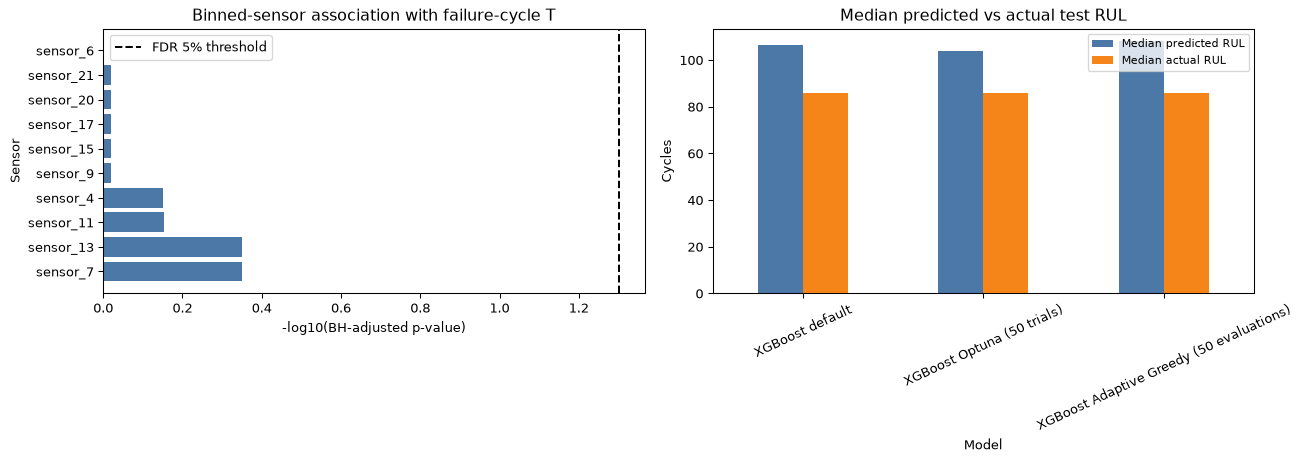

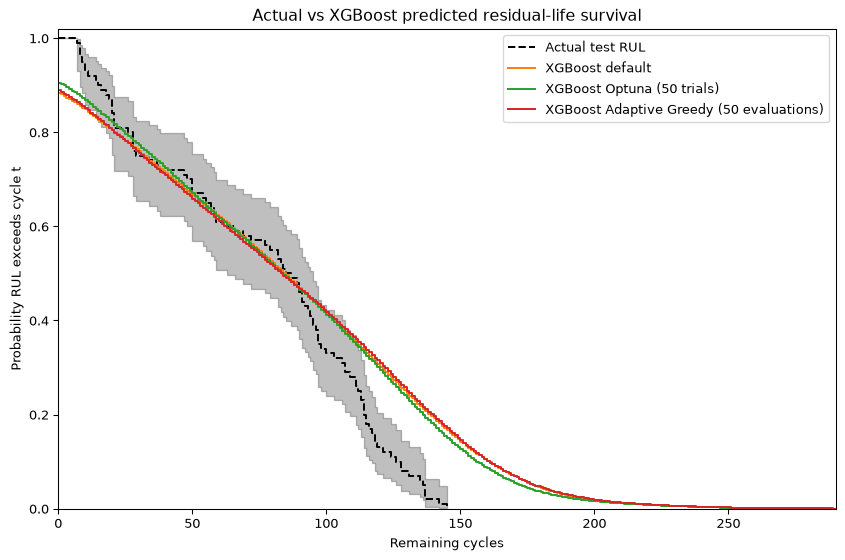

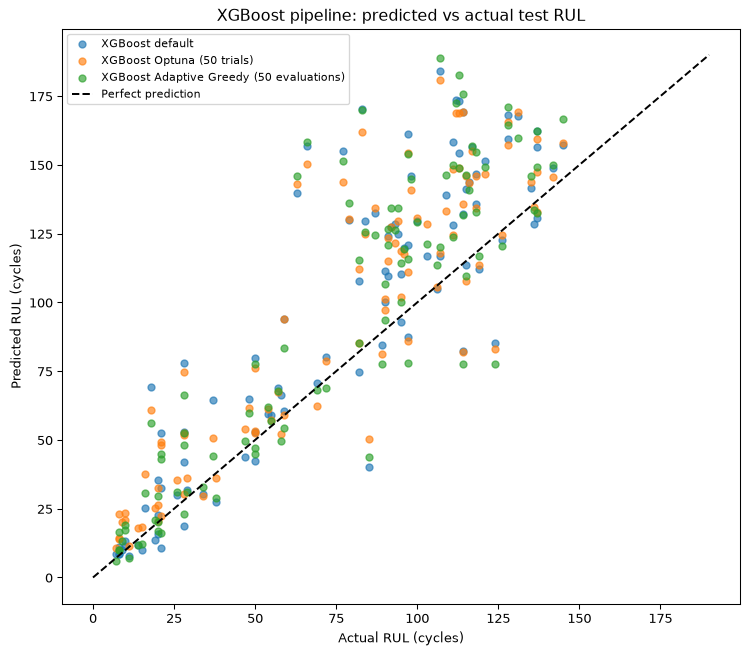

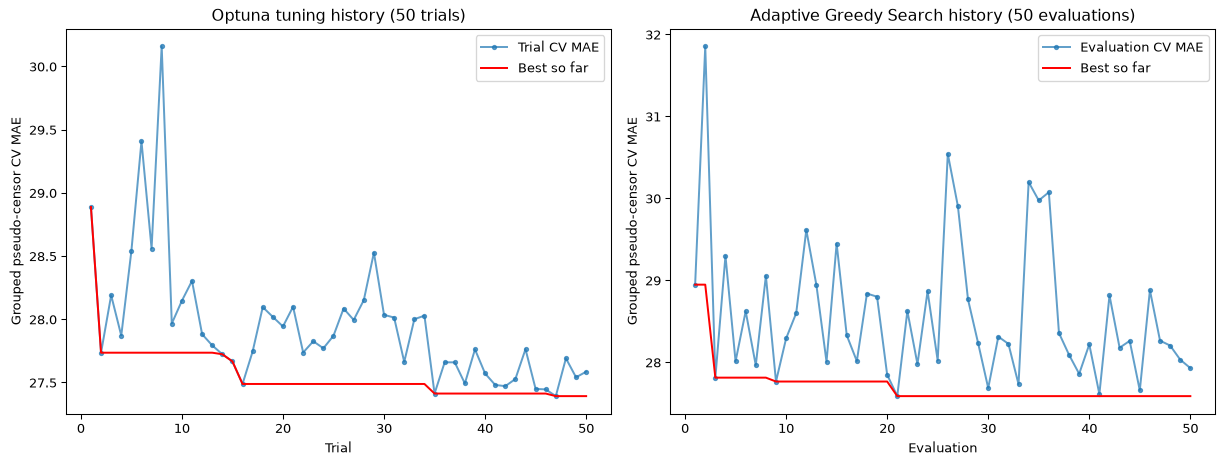

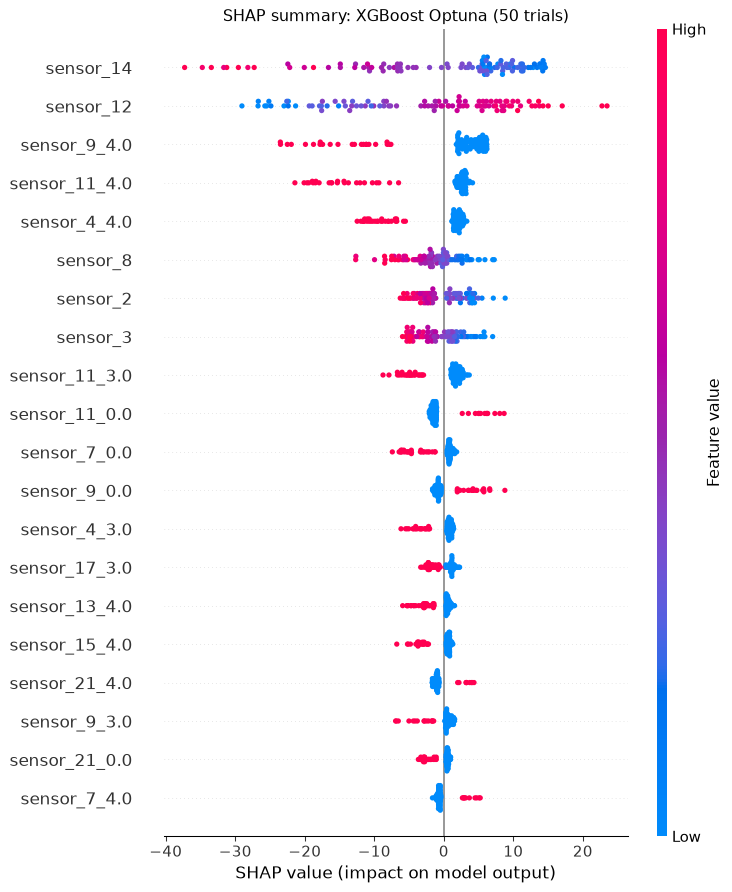

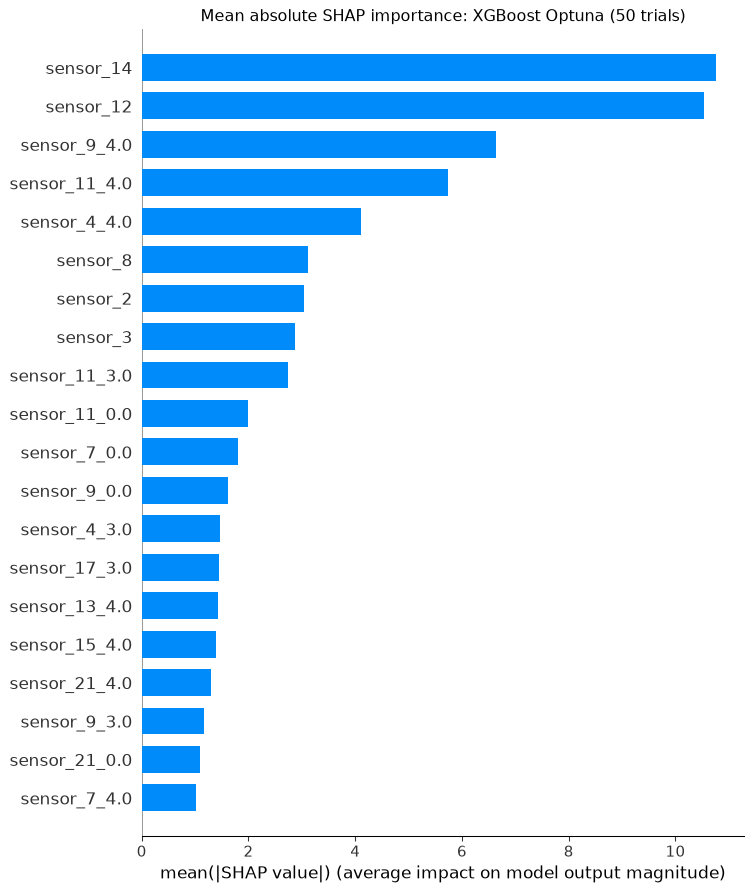

In [14]:
# Bin lower-SHAP sensors, test their association with failure-cycle T, then tune and evaluate an XGBoost preprocessing pipeline.
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import xgboost as xgb
from ags import AdaptiveGreedySearch
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from scipy.stats import kruskal
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder

optuna.logging.set_verbosity(optuna.logging.WARNING)
fd001_columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=fd001_columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=fd001_columns,
)
actual_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# Use the top five sensors from the previously computed RSF TreeExplainer SHAP ranking as numeric predictors.
important_sensors = ["sensor_12", "sensor_2", "sensor_8", "sensor_3", "sensor_14"]
train_failure_cycle = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.copy()
train_rows["remaining_life"] = (
    train_rows["engine_id"].map(train_failure_cycle) - train_rows["cycle"]
).astype(float)
train_baseline = (
    train_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)
variable_sensors = [
    column for column in fd001_columns[5:]
    if train_baseline[column].nunique() > 1
]
missing_shap_sensors = sorted(set(important_sensors) - set(variable_sensors))
if missing_shap_sensors:
    raise ValueError(f"SHAP-selected sensors are unavailable or constant: {missing_shap_sensors}")
binned_sensors = [
    column for column in variable_sensors if column not in important_sensors
]
feature_cols = [*important_sensors, *binned_sensors]
X_train_raw = train_rows[feature_cols].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
groups = train_rows["engine_id"].to_numpy()
test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test_raw = test_last[feature_cols].astype(float)
actual_test_age = test_last["cycle"].to_numpy()
assert len(train_rows) == 20631 and train_raw["engine_id"].nunique() == 100
assert len(test_last) == len(actual_rul) == 100
assert test_last["engine_id"].tolist() == list(range(1, 101))

# One engine-level baseline observation per engine is used for Kruskal-Wallis tests against failure-cycle T.
# Bin edges are fit only on training cycle rows; repeated time rows are not treated as independent test samples.
binner_for_tests = KBinsDiscretizer(
    n_bins=5, encode="ordinal", strategy="quantile", subsample=None
)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Bins whose width are too small")
    binner_for_tests.fit(X_train_raw[binned_sensors])
engine_failure_cycles = train_baseline.set_index("engine_id").index.map(train_failure_cycle).to_numpy()
baseline_bins = binner_for_tests.transform(train_baseline[binned_sensors].astype(float))
category_labels = ["Very low", "Low", "Medium", "High", "Very high"]
association_rows = []
for feature_index, sensor in enumerate(binned_sensors):
    bins = baseline_bins[:, feature_index].astype(int)
    observed_bins = np.unique(bins)
    groups_by_bin = [engine_failure_cycles[bins == bin_id] for bin_id in observed_bins]
    if len(groups_by_bin) < 2 or any(len(values) == 0 for values in groups_by_bin):
        statistic, p_value = np.nan, np.nan
    else:
        statistic, p_value = kruskal(*groups_by_bin)
    group_medians = {
        category_labels[int(bin_id)]: float(np.median(engine_failure_cycles[bins == bin_id]))
        for bin_id in observed_bins
    }
    association_rows.append({
        "Sensor": sensor,
        "Groups observed": len(observed_bins),
        "Kruskal-Wallis H": statistic,
        "p-value": p_value,
        "Median T by group": group_medians,
    })
association_table = pd.DataFrame(association_rows)
valid_p = association_table["p-value"].notna()
association_table["BH-adjusted p"] = np.nan
if valid_p.any():
    p_values = association_table.loc[valid_p, "p-value"].to_numpy()
    order = np.argsort(p_values)
    ranked = p_values[order] * len(p_values) / np.arange(1, len(p_values) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty_like(ranked)
    adjusted[order] = np.clip(ranked, 0.0, 1.0)
    association_table.loc[valid_p, "BH-adjusted p"] = adjusted
association_table["Significant (FDR 5%)"] = association_table["BH-adjusted p"] < 0.05
print("Sensor-bin association with engine failure cycle T (Kruskal-Wallis; 100 independent engines):")
print(association_table[["Sensor", "Groups observed", "Kruskal-Wallis H", "p-value", "BH-adjusted p", "Significant (FDR 5%)", "Median T by group"]].to_string(index=False))
print("Kruskal-Wallis is an unadjusted association test; Benjamini-Hochberg controls FDR across binned sensors.")

# Train-only pipeline: important sensors remain continuous; other varying sensors are quantile-binned and one-hot encoded.
preprocessor = ColumnTransformer(
    transformers=[
        ("important_numeric", "passthrough", important_sensors),
        (
            "binned_categorical",
            Pipeline([
                ("quantile_bins", KBinsDiscretizer(
                    n_bins=5, encode="ordinal", strategy="quantile", subsample=None
                )),
                ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            binned_sensors,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
def make_xgb_pipeline(params=None, n_jobs=1):
    model_params = {
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": n_jobs,
        "verbosity": 0,
    }
    if params:
        model_params.update(params)
    return Pipeline([
        ("features", preprocessor),
        ("model", xgb.XGBRegressor(**model_params)),
    ])

# Pseudo-censor validation uses future cut points from held-out engines; all their cycle rows are excluded from fitting.
# Reusing a three-fold GroupKFold avoids leakage of repeated cycles from an engine across folds.
row_at_cycle = {
    int(engine_id): {int(cycle): int(position) for position, cycle in zip(group.index, group["cycle"])}
    for engine_id, group in train_rows.groupby("engine_id", sort=False)
}
validation_fractions = (0.25, 0.45, 0.65, 0.85)
validation_splits = []
for fit_index, held_out_rows in GroupKFold(n_splits=3).split(
    X_train_raw, y_train, groups
):
    held_out_engines = np.unique(groups[held_out_rows])
    validation_index = []
    for engine_id in held_out_engines:
        failure_cycle = int(train_failure_cycle.loc[engine_id])
        for fraction in validation_fractions:
            cutoff = min(
                failure_cycle - 1,
                max(1, int(round(failure_cycle * fraction))),
            )
            validation_index.append(row_at_cycle[int(engine_id)][cutoff])
    validation_index = np.asarray(validation_index, dtype=int)
    if np.intersect1d(groups[fit_index], groups[validation_index]).size:
        raise AssertionError("Engine leakage found in pseudo-censoring validation.")
    validation_splits.append((fit_index, validation_index))

score_cache = {}
def grouped_cv_mae(params):
    key = tuple(sorted(params.items()))
    if key in score_cache:
        return score_cache[key]
    fold_scores = []
    for fit_index, validation_index in validation_splits:
        model = make_xgb_pipeline(params=params, n_jobs=1)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Bins whose width are too small")
            model.fit(X_train_raw.iloc[fit_index], y_train[fit_index])
        prediction = np.maximum(0.0, model.predict(X_train_raw.iloc[validation_index]))
        fold_scores.append(mean_absolute_error(y_train[validation_index], prediction))
    score = float(np.mean(fold_scores))
    score_cache[key] = score
    return score

def suggest_optuna_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 80, 300, step=20),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 3.0),
    }

optuna_study = optuna.create_study(
    direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
)
print("Running 50 Optuna trials for the preprocessed XGBoost pipeline...")
optuna_study.optimize(
    lambda trial: grouped_cv_mae(suggest_optuna_params(trial)),
    n_trials=50,
    n_jobs=1,
    show_progress_bar=False,
)
optuna_best_params = dict(optuna_study.best_params)
print("Optuna best grouped CV MAE:", round(optuna_study.best_value, 3))
print("Optuna best parameters:", optuna_best_params)

# AGS has no public groups argument; provide the same precomputed engine-disjoint validation splits.
class PrecomputedEngineSplits:
    def __init__(self, splits):
        self.splits = splits

    def split(self, X, y=None):
        return iter(self.splits)

    def get_n_splits(self, X=None, y=None):
        return len(self.splits)

ags_grid = {
    "model__n_estimators": [80, 120, 160, 200, 240, 280, 300],
    "model__max_depth": [2, 3, 4, 5, 6, 7],
    "model__learning_rate": [0.015, 0.025, 0.04, 0.06, 0.10, 0.15],
    "model__min_child_weight": [1, 2, 4, 6, 8, 10],
    "model__subsample": [0.65, 0.75, 0.85, 1.0],
    "model__colsample_bytree": [0.65, 0.75, 0.85, 1.0],
    "model__reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
    "model__gamma": [0.0, 0.25, 0.75, 1.5, 3.0],
}
ags_estimator = make_xgb_pipeline(n_jobs=1)
ags_search = AdaptiveGreedySearch(
    estimator=ags_estimator,
    param_grid=ags_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    max_evaluations=50,
    n_climbers=5,
    n_jobs=1,
    random_state=42,
    enable_pruning=False,
    candidate_pool_size=128,
)
ags_search._cv_splitter = PrecomputedEngineSplits(validation_splits)
print("Running 50 Adaptive Greedy Search evaluations for the preprocessed XGBoost pipeline...")
ags_search.fit(X_train_raw, y_train)
ags_best_params = {
    key.removeprefix("model__"): value
    for key, value in dict(ags_search.best_params).items()
}
ags_best_cv_mae = -float(ags_search.best_score)
print("Adaptive Greedy Search best grouped CV MAE:", round(ags_best_cv_mae, 3))
print("Adaptive Greedy Search best parameters:", ags_best_params)

# Evaluate three test predictors: default, tuned Optuna, and tuned adaptive-greedy.
best_configurations = {
    "XGBoost default": {
        "n_estimators": 250, "max_depth": 3, "learning_rate": 0.04,
        "subsample": 0.8, "colsample_bytree": 0.8,
        "reg_lambda": 5.0, "min_child_weight": 5,
    },
    "XGBoost Optuna (50 trials)": optuna_best_params,
    "XGBoost Adaptive Greedy (50 evaluations)": ags_best_params,
}
final_models = {}
test_predictions = {}
for model_name, params in best_configurations.items():
    model = make_xgb_pipeline(params=params, n_jobs=-1)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Bins whose width are too small")
        model.fit(X_train_raw, y_train)
    final_models[model_name] = model
    test_predictions[model_name] = np.maximum(0.0, model.predict(X_test_raw))

# Collect grouped out-of-fold pseudo-censor residuals using each selected configuration for survival metrics.
residuals_by_model = {}
for model_name, params in best_configurations.items():
    out_of_fold_residuals = []
    for fit_index, validation_index in validation_splits:
        fold_model = make_xgb_pipeline(params=params, n_jobs=1)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Bins whose width are too small")
            fold_model.fit(X_train_raw.iloc[fit_index], y_train[fit_index])
        validation_prediction = np.maximum(
            0.0, fold_model.predict(X_train_raw.iloc[validation_index])
        )
        out_of_fold_residuals.extend(
            (y_train[validation_index] - validation_prediction).tolist()
        )
    residuals_by_model[model_name] = np.asarray(out_of_fold_residuals)

actual_km = KaplanMeierFitter().fit(
    actual_rul, event_observed=np.ones(len(actual_rul)), label="Actual test RUL"
)
metric_horizons = np.arange(1, int(actual_rul.max()))
actual_survival = np.asarray(actual_km.predict(metric_horizons))
rul_grid = np.arange(0, int(np.ceil(max(actual_rul.max(), max(p.max() for p in test_predictions.values()) + 100))) + 1)
survival_curves = {}
metric_rows = []
for model_name, prediction in test_predictions.items():
    residuals = residuals_by_model[model_name]
    pseudo_rul_draws = np.maximum(0.0, prediction[:, None] + residuals[None, :])
    curves = np.column_stack([
        np.mean(pseudo_rul_draws > horizon, axis=1) for horizon in rul_grid
    ])
    survival_curves[model_name] = curves
    auc_values = []
    for horizon in metric_horizons:
        failed_by_horizon = (actual_rul <= horizon).astype(int)
        if np.unique(failed_by_horizon).size == 2:
            auc_values.append(roc_auc_score(
                failed_by_horizon, 1.0 - curves[:, horizon]
            ))
    mean_survival = curves.mean(axis=0)[metric_horizons]
    metric_rows.append({
        "Model": model_name,
        "C-index": concordance_index(actual_rul, prediction),
        "Cumulative/Dynamic AUC": float(np.mean(auc_values)),
        "MAE (cycles)": mean_absolute_error(actual_rul, prediction),
        "RMSE (cycles)": mean_squared_error(actual_rul, prediction) ** 0.5,
        "IAE": np.trapezoid(np.abs(mean_survival - actual_survival), metric_horizons),
        "ISE": np.trapezoid((mean_survival - actual_survival) ** 2, metric_horizons),
        "AIC": np.nan,
        "BIC": np.nan,
        "Median predicted RUL": float(np.median(prediction)),
        "Median actual RUL": float(np.median(actual_rul)),
    })
performance = pd.DataFrame(metric_rows).set_index("Model")
print("\nTest comparison against the same 100 RUL_FD001 outcomes:")
print(performance.to_string(float_format=lambda value: f"{value:.3f}", na_rep="N/A"))
print("AIC/BIC are N/A for XGBoost regression. Survival curves use engine-grouped pseudo-censor OOF residuals.")
print("Per-engine first 10 predictions:")
print(pd.DataFrame({
    "engine_id": test_last["engine_id"],
    "actual_RUL": actual_rul,
    **test_predictions,
}).head(10).to_string(index=False, float_format=lambda value: f"{value:.1f}"))

# SHAP TreeExplainer on the final model with the lowest pseudo-censor CV MAE.
best_tuning_name = (
    "XGBoost Optuna (50 trials)"
    if optuna_study.best_value <= ags_best_cv_mae
    else "XGBoost Adaptive Greedy (50 evaluations)"
)
best_model = final_models[best_tuning_name]
fitted_preprocessor = best_model.named_steps["features"]
fitted_xgb = best_model.named_steps["model"]
X_train_transformed = fitted_preprocessor.transform(X_train_raw)
X_test_transformed = fitted_preprocessor.transform(X_test_raw)
transformed_feature_names = fitted_preprocessor.get_feature_names_out()
shap_background_indices = np.linspace(
    0, len(X_train_transformed) - 1, min(200, len(X_train_transformed)), dtype=int
)
explainer = shap.TreeExplainer(
    fitted_xgb,
    data=X_train_transformed[shap_background_indices],
    feature_perturbation="interventional",
)
shap_explanation = explainer(X_test_transformed, check_additivity=False)
shap_importance = pd.Series(
    np.abs(shap_explanation.values).mean(axis=0), index=transformed_feature_names
).sort_values(ascending=False)
print(f"\nSHAP TreeExplainer model: {best_tuning_name}")
print("Top transformed-feature mean absolute SHAP values:")
print(shap_importance.head(15).to_string())

# Plot significance, test RUL survival, point predictions, tuning histories, and SHAP explanations.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_associations = association_table.sort_values("BH-adjusted p", na_position="last")
axes[0].barh(plot_associations["Sensor"], -np.log10(np.maximum(plot_associations["BH-adjusted p"].fillna(1.0), 1e-300)), color=np.where(plot_associations["Significant (FDR 5%)"], "#e45756", "#4c78a8"))
axes[0].axvline(-np.log10(0.05), color="black", linestyle="--", label="FDR 5% threshold")
axes[0].set(title="Binned-sensor association with failure-cycle T", xlabel="-log10(BH-adjusted p-value)", ylabel="Sensor")
axes[0].legend()

median_comparison = performance[["Median predicted RUL", "Median actual RUL"]]
median_comparison.plot.bar(ax=axes[1], color=["#4c78a8", "#f58518"])
axes[1].set(title="Median predicted vs actual test RUL", ylabel="Cycles", xlabel="Model")
axes[1].tick_params(axis="x", labelrotation=25)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
actual_km.plot_survival_function(ax=ax, ci_show=True, color="black", linestyle="--")
for model_name, curves in survival_curves.items():
    ax.step(rul_grid, curves.mean(axis=0), where="post", label=model_name)
ax.set(title="Actual vs XGBoost predicted residual-life survival", xlabel="Remaining cycles", ylabel="Probability RUL exceeds cycle t", xlim=(0, int(rul_grid[-1])), ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
for model_name, prediction in test_predictions.items():
    ax.scatter(actual_rul, prediction, alpha=0.65, s=28, label=model_name)
limit = max(int(actual_rul.max()), int(np.ceil(max(prediction.max() for prediction in test_predictions.values()))))
ax.plot([0, limit], [0, limit], "k--", label="Perfect prediction")
ax.set(title="XGBoost pipeline: predicted vs actual test RUL", xlabel="Actual RUL (cycles)", ylabel="Predicted RUL (cycles)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(np.arange(1, len(optuna_study.trials) + 1), [trial.value for trial in optuna_study.trials], marker=".", alpha=0.7, label="Trial CV MAE")
axes[0].plot(np.arange(1, len(optuna_study.trials) + 1), np.minimum.accumulate([trial.value for trial in optuna_study.trials]), color="red", label="Best so far")
axes[0].set(title="Optuna tuning history (50 trials)", xlabel="Trial", ylabel="Grouped pseudo-censor CV MAE")
axes[0].legend()
ags_scores = [float(value) for value in ags_search.completed_evaluations.values()]
axes[1].plot(np.arange(1, len(ags_scores) + 1), -np.asarray(ags_scores), marker=".", alpha=0.7, label="Evaluation CV MAE")
axes[1].plot(np.arange(1, len(ags_scores) + 1), np.minimum.accumulate(-np.asarray(ags_scores)), color="red", label="Best so far")
axes[1].set(title="Adaptive Greedy Search history (50 evaluations)", xlabel="Evaluation", ylabel="Grouped pseudo-censor CV MAE")
axes[1].legend()
fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_explanation.values, X_test_transformed, feature_names=transformed_feature_names, show=False)
plt.title(f"SHAP summary: {best_tuning_name}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_explanation.values, X_test_transformed, feature_names=transformed_feature_names, plot_type="bar", show=False)
plt.title(f"Mean absolute SHAP importance: {best_tuning_name}")
plt.tight_layout()
plt.show()


**Discussion.** The training-engine Kruskal?Wallis tests select `sensor_7` (p=0.099) and `sensor_13` (p=0.083) at the requested unadjusted 10% threshold; neither passes the 5% Benjamini?Hochberg correction. The 50-trial Optuna pipeline obtains test C-index 0.844, dynamic AUC 0.933, MAE 22.23 cycles, and RMSE 29.72 cycles, a modest improvement over the default pipeline. The selected categorical associations are exploratory and do not establish causal effects.

Kruskal-Wallis sensor tests against engine failure cycle T:
   sensor      H  p_value  BH_adjusted_p
 sensor_4  3.556   0.3135         0.7055
 sensor_6    NaN      NaN            NaN
 sensor_7  7.803  0.09905         0.4457
 sensor_9  1.944   0.7461         0.9567
sensor_11  4.269   0.2339         0.7016
sensor_13  8.239  0.08321         0.4457
sensor_15  1.254   0.8691         0.9567
sensor_17  1.404   0.7045         0.9567
sensor_20 0.6558   0.9567         0.9567
sensor_21    1.7   0.6369         0.9567
Using unadjusted p < 0.10 as requested: ['sensor_7', 'sensor_13']
Note: neither selected sensor passes Benjamini-Hochberg FDR 5%; bins are selected using training data only.
Median training cycle knot: 104
Training rows per segment: {'Early (cycle <= knot)': 10400, 'Late (cycle > knot)': 10231}
Continuous predictors: ['cycle', 'sensor_12', 'sensor_2', 'sensor_8', 'sensor_3', 'sensor_14']
Five-quantile categorical predictors: ['sensor_7', 'sensor_13']
Early (cycle <= knot): train rows=

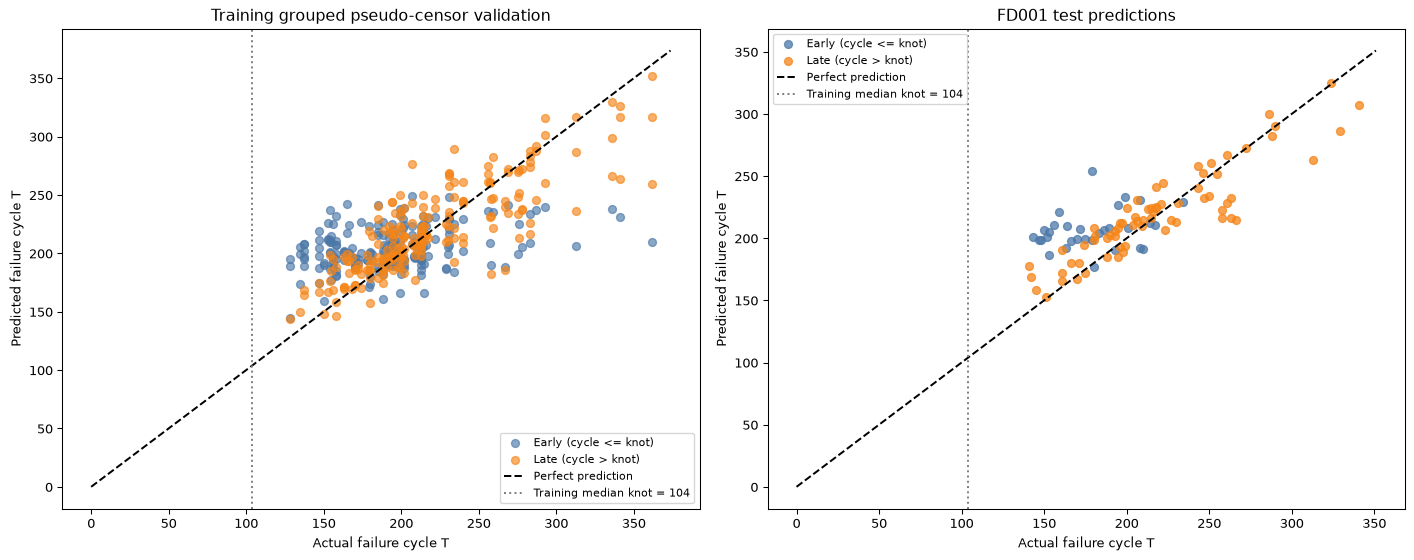

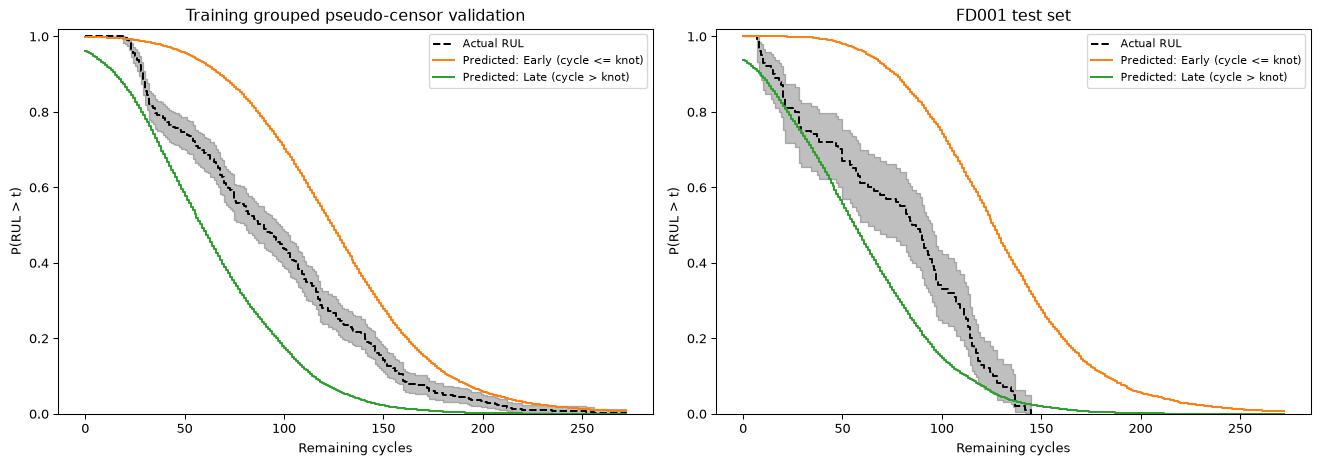

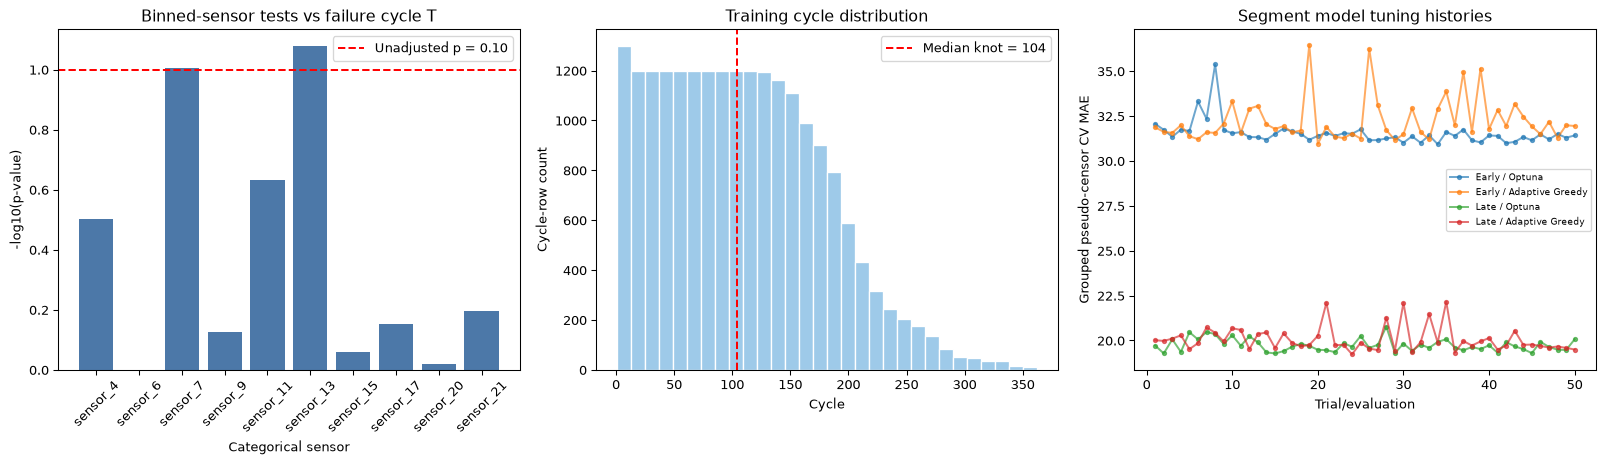

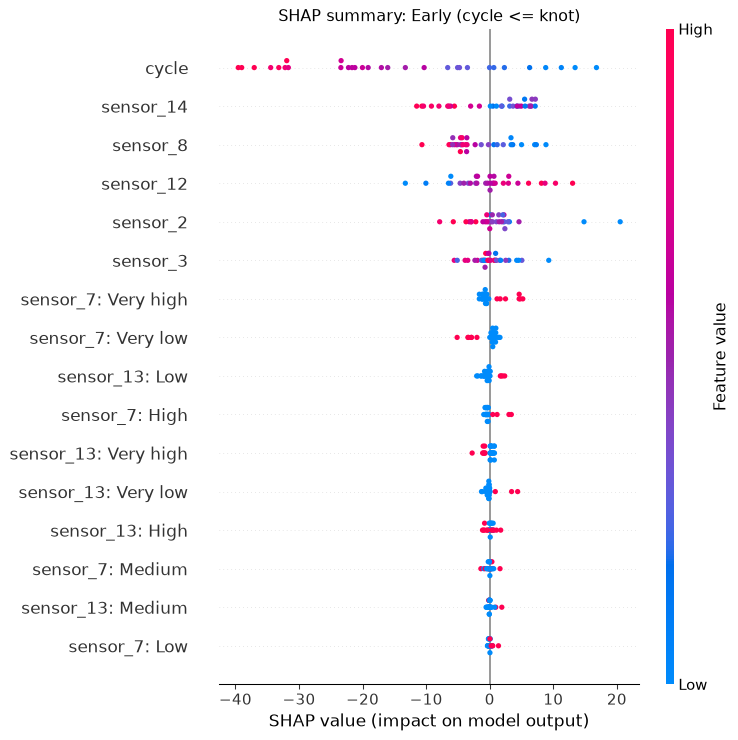

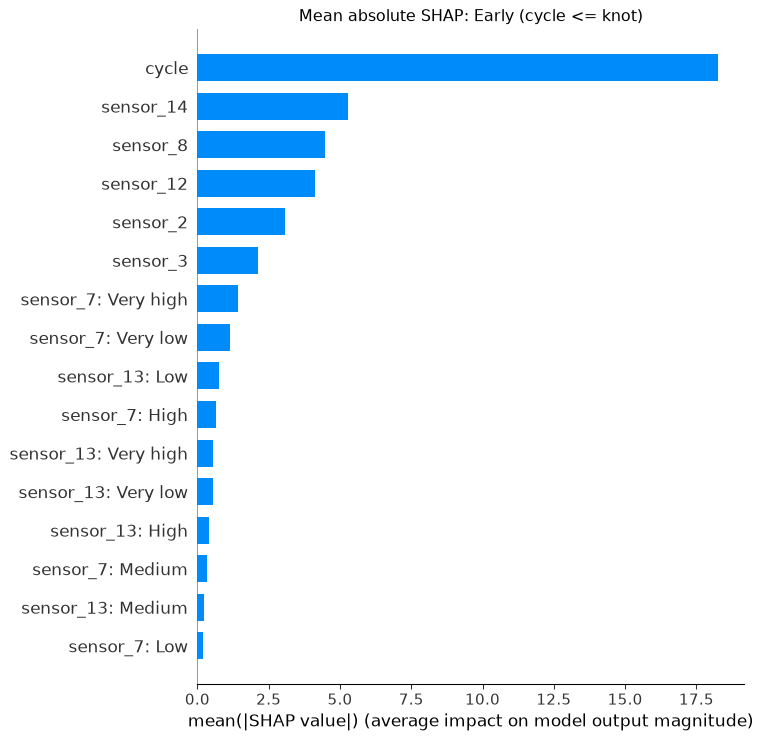

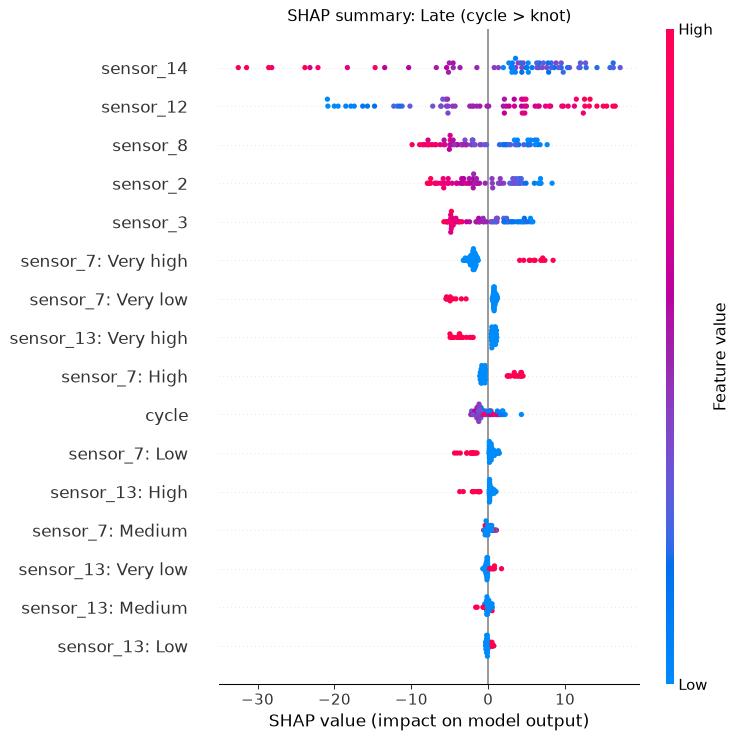

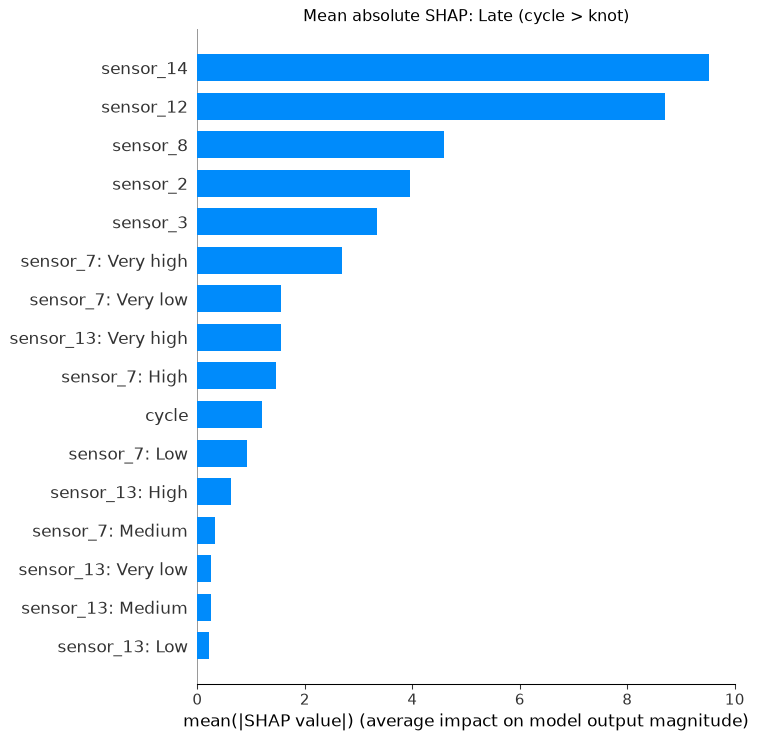

In [15]:
# Fit median-knot segmented XGBoost models using SHAP sensors and the two sensors significant at 10%.
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import xgboost as xgb
from ags import AdaptiveGreedySearch
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from scipy.stats import kruskal
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder

optuna.logging.set_verbosity(optuna.logging.WARNING)
columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_test_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy()

# T is the training engine's failure cycle; each row target is remaining cycles T - observed cycle.
train_failure_cycle = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.reset_index(drop=True).copy()
train_rows["failure_cycle_T"] = train_rows["engine_id"].map(train_failure_cycle)
train_rows["remaining_life"] = (
    train_rows["failure_cycle_T"] - train_rows["cycle"]
).astype(float)
train_baseline = (
    train_rows.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).first()
)

# Recheck training-engine Kruskal-Wallis p-values for the earlier five-quantile sensor groups.
# User requested the unadjusted 10% selection threshold; Benjamini-Hochberg results are also printed for context.
shap_numeric_sensors = ["sensor_12", "sensor_2", "sensor_8", "sensor_3", "sensor_14"]
variable_sensors = [
    sensor for sensor in columns[5:]
    if train_baseline[sensor].nunique() > 1
]
binned_candidate_sensors = [
    sensor for sensor in variable_sensors if sensor not in shap_numeric_sensors
]
engine_T = train_baseline.set_index("engine_id")["failure_cycle_T"].to_numpy()
association_rows = []
# Match the previous feature-selection analysis: learn quantile edges from all training rows,
# then test one baseline observation per engine so repeated cycles are not treated as independent.
binner_for_tests = KBinsDiscretizer(
    n_bins=5, encode="ordinal", strategy="quantile", subsample=None
)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Bins whose width are too small")
    binner_for_tests.fit(train_rows[binned_candidate_sensors].astype(float))
baseline_bins = binner_for_tests.transform(train_baseline[binned_candidate_sensors].astype(float))
for feature_index, sensor in enumerate(binned_candidate_sensors):
    bin_ids = baseline_bins[:, feature_index].astype(int)
    observed_bins = np.unique(bin_ids)
    groups_for_test = [engine_T[bin_ids == index] for index in observed_bins]
    if len(groups_for_test) < 2:
        statistic, p_value = np.nan, np.nan
    else:
        statistic, p_value = kruskal(*groups_for_test)
    association_rows.append({"sensor": sensor, "H": statistic, "p_value": p_value})
association = pd.DataFrame(association_rows)
valid = association["p_value"].notna()
association["BH_adjusted_p"] = np.nan
if valid.any():
    raw_p = association.loc[valid, "p_value"].to_numpy()
    order = np.argsort(raw_p)
    ranked = raw_p[order] * len(raw_p) / np.arange(1, len(raw_p) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty_like(ranked)
    adjusted[order] = np.clip(ranked, 0.0, 1.0)
    association.loc[valid, "BH_adjusted_p"] = adjusted
selected_categorical_sensors = association.loc[
    association["p_value"] < 0.10, "sensor"
].tolist()
if selected_categorical_sensors != ["sensor_7", "sensor_13"]:
    raise ValueError(
        "The 10% feature set changed; inspect the refreshed association table before continuing: "
        f"{selected_categorical_sensors}"
    )
print("Kruskal-Wallis sensor tests against engine failure cycle T:")
print(association.to_string(index=False, float_format=lambda value: f"{value:.4g}"))
print("Using unadjusted p < 0.10 as requested:", selected_categorical_sensors)
print("Note: neither selected sensor passes Benjamini-Hochberg FDR 5%; bins are selected using training data only.")

# One shared training-data median knot divides cycle rows into two separate regression regimes.
knot = float(train_rows["cycle"].median())
train_rows["cycle_segment"] = np.where(
    train_rows["cycle"] <= knot, "Early (cycle <= knot)", "Late (cycle > knot)"
)
print(f"Median training cycle knot: {knot:g}")
print("Training rows per segment:", train_rows["cycle_segment"].value_counts().to_dict())
print("Continuous predictors:", ["cycle", *shap_numeric_sensors])
print("Five-quantile categorical predictors:", selected_categorical_sensors)

numeric_features = ["cycle", *shap_numeric_sensors]
model_features = [*numeric_features, *selected_categorical_sensors]
X_train_raw = train_rows[model_features].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
engine_groups = train_rows["engine_id"].to_numpy()
test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test_raw = test_last[model_features].astype(float)
test_cycle = test_last["cycle"].to_numpy()
test_segment = np.where(test_cycle <= knot, "Early (cycle <= knot)", "Late (cycle > knot)")
assert len(train_rows) == 20631 and train_raw["engine_id"].nunique() == 100
assert len(test_last) == len(actual_test_rul) == 100
assert test_last["engine_id"].tolist() == list(range(1, 101))

# Pipeline learns quantile cut points and one-hot levels only from each training fold.
def make_segment_pipeline(params=None, n_jobs=1):
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", numeric_features),
            (
                "categorical_bins",
                Pipeline([
                    ("quantiles", KBinsDiscretizer(
                        n_bins=5, encode="ordinal", strategy="quantile", subsample=None
                    )),
                    ("one_hot", OneHotEncoder(
                        categories=[np.arange(5) for _ in selected_categorical_sensors],
                        handle_unknown="ignore", sparse_output=False,
                    )),
                ]),
                selected_categorical_sensors,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    model_params = {
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": n_jobs,
        "verbosity": 0,
    }
    if params:
        model_params.update(params)
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", xgb.XGBRegressor(**model_params)),
    ])

# Build engine-grouped pseudo-censor folds. Validation cutoffs mimic engines observed before failure.
row_at_cycle = {
    int(engine_id): {
        int(cycle): int(position)
        for position, cycle in zip(group.index, group["cycle"])
    }
    for engine_id, group in train_rows.groupby("engine_id", sort=False)
}
cut_fractions = (0.25, 0.45, 0.65, 0.85)
grouped_splits = []
for fit_indices, held_out_rows in GroupKFold(n_splits=3).split(
    X_train_raw, y_train, engine_groups
):
    held_out_engines = np.unique(engine_groups[held_out_rows])
    validation_indices = []
    for engine_id in held_out_engines:
        failure_cycle = int(train_failure_cycle.loc[engine_id])
        for fraction in cut_fractions:
            cutoff = min(
                failure_cycle - 1,
                max(1, int(round(failure_cycle * fraction))),
            )
            validation_indices.append(row_at_cycle[int(engine_id)][cutoff])
    validation_indices = np.asarray(validation_indices, dtype=int)
    if np.intersect1d(engine_groups[fit_indices], engine_groups[validation_indices]).size:
        raise AssertionError("Engine leakage found in segmented pseudo-censor validation.")
    grouped_splits.append((fit_indices, validation_indices))

segment_masks = {
    "Early (cycle <= knot)": (train_rows["cycle"].to_numpy() <= knot),
    "Late (cycle > knot)": (train_rows["cycle"].to_numpy() > knot),
}
segment_splits = {}
for segment_name, segment_mask in segment_masks.items():
    splits = []
    for fit_indices, validation_indices in grouped_splits:
        fit_segment = fit_indices[segment_mask[fit_indices]]
        validation_segment = validation_indices[segment_mask[validation_indices]]
        if len(fit_segment) == 0 or len(validation_segment) == 0:
            raise ValueError(f"Empty training or validation segment for {segment_name}.")
        splits.append((fit_segment, validation_segment))
    segment_splits[segment_name] = splits
    print(f"{segment_name}: train rows={int(segment_mask.sum())}; "
          f"validation cutoffs per fold={[len(v) for _, v in splits]}")

# Each segment is tuned separately with 50 Optuna trials and 50 adaptive-greedy evaluations.
def make_search_space():
    return {
        "model__n_estimators": [60, 100, 140, 180, 220, 260],
        "model__max_depth": [2, 3, 4, 5, 6, 7],
        "model__learning_rate": [0.015, 0.025, 0.04, 0.06, 0.10, 0.15],
        "model__min_child_weight": [1, 2, 4, 6, 8, 10],
        "model__subsample": [0.65, 0.75, 0.85, 1.0],
        "model__colsample_bytree": [0.65, 0.75, 0.85, 1.0],
        "model__reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
        "model__gamma": [0.0, 0.25, 0.75, 1.5, 3.0],
    }
def suggest_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 60, 260, step=20),
        "max_depth": trial.suggest_int("max_depth", 2, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 3.0),
    }
def cv_mae(params, splits):
    scores = []
    for fit_indices, validation_indices in splits:
        model = make_segment_pipeline(params=params, n_jobs=1)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Bins whose width are too small")
            model.fit(X_train_raw.iloc[fit_indices], y_train[fit_indices])
        prediction = np.maximum(0.0, model.predict(X_train_raw.iloc[validation_indices]))
        scores.append(mean_absolute_error(y_train[validation_indices], prediction))
    return float(np.mean(scores))

class PrecomputedSegmentSplits:
    def __init__(self, splits):
        self.splits = splits
    def split(self, X, y=None):
        return iter(self.splits)
    def get_n_splits(self, X=None, y=None):
        return len(self.splits)

search_results = {}
tuning_records = []
for segment_index, (segment_name, segment_mask) in enumerate(segment_masks.items()):
    splits = segment_splits[segment_name]
    print(f"\nTuning {segment_name}: 50 Optuna trials...")
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42 + segment_index)
    )
    study.optimize(
        lambda trial: cv_mae(suggest_params(trial), splits),
        n_trials=50, n_jobs=1, show_progress_bar=False,
    )
    print("Optuna best grouped CV MAE:", round(study.best_value, 3))
    print("Optuna best params:", study.best_params)
    tuning_records.append({
        "segment": segment_name,
        "method": "Optuna",
        "score": float(study.best_value),
        "params": dict(study.best_params),
        "history": [float(trial.value) for trial in study.trials],
    })

    print(f"Tuning {segment_name}: 50 Adaptive Greedy Search evaluations...")
    estimator = make_segment_pipeline(n_jobs=1)
    greedy = AdaptiveGreedySearch(
        estimator=estimator,
        param_grid=make_search_space(),
        cv=3,
        scoring="neg_mean_absolute_error",
        max_evaluations=50,
        n_climbers=5,
        n_jobs=1,
        random_state=42 + segment_index,
        enable_pruning=False,
        candidate_pool_size=128,
    )
    greedy._cv_splitter = PrecomputedSegmentSplits(splits)
    greedy.fit(X_train_raw, y_train)
    greedy_params = {
        key.removeprefix("model__"): value
        for key, value in dict(greedy.best_params).items()
    }
    greedy_score = -float(greedy.best_score)
    print("Adaptive Greedy best grouped CV MAE:", round(greedy_score, 3))
    print("Adaptive Greedy best params:", greedy_params)
    tuning_records.append({
        "segment": segment_name,
        "method": "Adaptive Greedy",
        "score": greedy_score,
        "params": greedy_params,
        "history": [-float(value) for value in greedy.completed_evaluations.values()],
    })
    best_record = min(
        [record for record in tuning_records if record["segment"] == segment_name],
        key=lambda record: record["score"],
    )
    search_results[segment_name] = {
        "best_method": best_record["method"],
        "best_cv_mae": best_record["score"],
        "best_params": best_record["params"],
        "optuna_study": study,
        "ags_search": greedy,
    }
    print("Selected search method for segment:", best_record["method"])

# Fit the selected early/late estimators on all training rows belonging to that segment.
segment_models = {}
for segment_name, segment_mask in segment_masks.items():
    selected = search_results[segment_name]
    model = make_segment_pipeline(params=selected["best_params"], n_jobs=-1)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Bins whose width are too small")
        model.fit(X_train_raw.loc[segment_mask], y_train[segment_mask])
    segment_models[segment_name] = model

# Gather group-held-out predictions at four pseudo-censor points per engine for honest training validation summaries.
train_validation_rows = []
for segment_name, segment_mask in segment_masks.items():
    for fold_number, (fit_indices, validation_indices) in enumerate(segment_splits[segment_name], 1):
        model = make_segment_pipeline(
            params=search_results[segment_name]["best_params"], n_jobs=1
        )
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Bins whose width are too small")
            model.fit(X_train_raw.iloc[fit_indices], y_train[fit_indices])
        predictions = np.maximum(0.0, model.predict(X_train_raw.iloc[validation_indices]))
        for row_index, prediction in zip(validation_indices, predictions):
            train_validation_rows.append({
                "engine_id": int(train_rows.iloc[row_index]["engine_id"]),
                "cycle": int(train_rows.iloc[row_index]["cycle"]),
                "segment": segment_name,
                "actual_RUL": float(y_train[row_index]),
                "predicted_RUL": float(prediction),
                "actual_failure_cycle": float(train_rows.iloc[row_index]["failure_cycle_T"]),
                "predicted_failure_cycle": float(train_rows.iloc[row_index]["cycle"] + prediction),
                "fold": fold_number,
            })
train_validation = pd.DataFrame(train_validation_rows)

# Apparent training fit metrics are shown separately and are not generalization estimates.
train_fit_rows = []
for segment_name, segment_mask in segment_masks.items():
    fit_prediction = np.maximum(
        0.0,
        segment_models[segment_name].predict(X_train_raw.loc[segment_mask]),
    )
    fit_actual = y_train[segment_mask]
    train_fit_rows.append({
        "Segment": segment_name,
        "Rows": int(segment_mask.sum()),
        "Apparent train MAE": mean_absolute_error(fit_actual, fit_prediction),
        "Apparent train RMSE": mean_squared_error(fit_actual, fit_prediction) ** 0.5,
        "Apparent train R2": r2_score(fit_actual, fit_prediction),
        "Grouped pseudo-censor CV MAE": mean_absolute_error(
            train_validation.loc[train_validation.segment == segment_name, "actual_RUL"],
            train_validation.loc[train_validation.segment == segment_name, "predicted_RUL"],
        ),
        "Grouped pseudo-censor CV RMSE": mean_squared_error(
            train_validation.loc[train_validation.segment == segment_name, "actual_RUL"],
            train_validation.loc[train_validation.segment == segment_name, "predicted_RUL"],
        ) ** 0.5,
    })
train_metrics = pd.DataFrame(train_fit_rows).set_index("Segment")
print("\nTraining results by segment (apparent fit metrics are optimistic; grouped pseudo-censor CV is the validation estimate):")
print(train_metrics.to_string(float_format=lambda value: f"{value:.3f}"))

# Apply the corresponding segment model at each test engine's last observed cycle.
test_predictions = np.empty(len(test_last), dtype=float)
for segment_name in segment_models:
    mask = test_segment == segment_name
    if mask.any():
        test_predictions[mask] = np.maximum(
            0.0, segment_models[segment_name].predict(X_test_raw.loc[mask])
        )
test_actual_failure_cycle = test_cycle + actual_test_rul
test_predicted_failure_cycle = test_cycle + test_predictions

# Build residual-life survival curves from group-held-out pseudo-censor residuals for each segment.
validation_residuals = {}
for segment_name in segment_models:
    part = train_validation.loc[train_validation.segment == segment_name]
    validation_residuals[segment_name] = (
        part["actual_RUL"].to_numpy() - part["predicted_RUL"].to_numpy()
    )
if any(len(values) == 0 for values in validation_residuals.values()):
    raise ValueError("A segment has no held-out residuals for survival prediction.")
max_horizon = int(max(actual_test_rul.max(), train_validation.actual_RUL.max()))
horizon_grid = np.arange(0, max_horizon + 1)
def residual_survival(predictions, segments):
    curves = np.zeros((len(predictions), len(horizon_grid)), dtype=float)
    for row_index, (prediction, segment_name) in enumerate(zip(predictions, segments)):
        simulated_remaining_life = np.maximum(
            0.0, prediction + validation_residuals[segment_name]
        )
        curves[row_index] = np.mean(
            simulated_remaining_life[:, None] > horizon_grid[None, :], axis=0
        )
    return curves
train_segments = train_validation["segment"].to_numpy()
train_cv_predictions = train_validation["predicted_RUL"].to_numpy()
train_cv_actual = train_validation["actual_RUL"].to_numpy()
train_cv_survival = residual_survival(train_cv_predictions, train_segments)
test_survival = residual_survival(test_predictions, test_segment)

# Use the same C-index, cumulative/dynamic AUC, MAE, IAE, and ISE definitions as earlier notebook comparisons.
def survival_performance(actual, predictions, curves):
    actual_km = KaplanMeierFitter().fit(
        actual, event_observed=np.ones(len(actual)), label="Actual RUL"
    )
    horizons = np.arange(1, int(np.max(actual)))
    actual_curve = np.asarray(actual_km.predict(horizons))
    auc_values = []
    for horizon in horizons:
        event_by_horizon = (actual <= horizon).astype(int)
        if np.unique(event_by_horizon).size == 2:
            auc_values.append(roc_auc_score(
                event_by_horizon, 1.0 - curves[:, horizon]
            ))
    predicted_mean = curves.mean(axis=0)[horizons]
    actual_mean = actual_curve
    return {
        "C-index": concordance_index(actual, predictions),
        "Cumulative/Dynamic AUC": float(np.mean(auc_values)),
        "MAE (cycles)": mean_absolute_error(actual, predictions),
        "RMSE (cycles)": mean_squared_error(actual, predictions) ** 0.5,
        "IAE": np.trapezoid(np.abs(predicted_mean - actual_mean), horizons),
        "ISE": np.trapezoid((predicted_mean - actual_mean) ** 2, horizons),
        "Median predicted RUL": float(np.median(predictions)),
        "Median actual RUL": float(np.median(actual)),
        "AIC": np.nan,
        "BIC": np.nan,
    }
train_validation_metrics = survival_performance(
    train_cv_actual, train_cv_predictions, train_cv_survival
)
test_metrics = survival_performance(actual_test_rul, test_predictions, test_survival)
performance = pd.DataFrame(
    [train_validation_metrics, test_metrics],
    index=["Training grouped pseudo-censor CV", "FD001 test (RUL_FD001)"],
)
print("\nSegmented model performance (train row is grouped pseudo-censor validation, not in-sample fit):")
print(performance.to_string(float_format=lambda value: f"{value:.3f}", na_rep="N/A"))
print("AIC/BIC are not defined for the separate XGBoost regressors.")
print("Survival curves use out-of-engine pseudo-censor residuals, stratified by early/late cycle segment.")
print("Test actual failure cycle = final observed cycle + RUL_FD001; predicted failure cycle uses predicted RUL.")
print("Test engines per segment:", pd.Series(test_segment).value_counts().to_dict())
print("Selected models:")
for segment_name, result in search_results.items():
    print(segment_name, "<-", result["best_method"], "CV MAE", round(result["best_cv_mae"], 3), result["best_params"])

# Show training pseudo-censor and test failure-cycle predictions against their actual failure cycles.
train_plot = train_validation.copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for segment_name, color in zip(segment_models, ("#4c78a8", "#f58518")):
    part = train_plot[train_plot.segment == segment_name]
    axes[0].scatter(
        part["actual_failure_cycle"], part["predicted_failure_cycle"],
        label=segment_name, alpha=0.65, color=color,
    )
    test_mask = test_segment == segment_name
    axes[1].scatter(
        test_actual_failure_cycle[test_mask], test_predicted_failure_cycle[test_mask],
        label=segment_name, alpha=0.75, color=color,
    )
for axis, title in zip(axes, ("Training grouped pseudo-censor validation", "FD001 test predictions")):
    limit = max(axis.get_xlim()[1], axis.get_ylim()[1])
    lower = min(0, axis.get_xlim()[0], axis.get_ylim()[0])
    axis.plot([lower, limit], [lower, limit], "k--", label="Perfect prediction")
    axis.axvline(knot, color="gray", linestyle=":", label=f"Training median knot = {knot:g}")
    axis.set(title=title, xlabel="Actual failure cycle T", ylabel="Predicted failure cycle T")
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Compare actual and predicted residual-life survival in training validation and test cohorts.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, actual, curves, title in [
    (axes[0], train_cv_actual, train_cv_survival, "Training grouped pseudo-censor validation"),
    (axes[1], actual_test_rul, test_survival, "FD001 test set"),
]:
    actual_km = KaplanMeierFitter().fit(
        actual, event_observed=np.ones(len(actual)), label="Actual RUL"
    )
    actual_km.plot_survival_function(ax=axis, ci_show=True, color="black", linestyle="--")
    for segment_name in segment_models:
        mask = (train_segments == segment_name) if title.startswith("Training") else (test_segment == segment_name)
        if mask.any():
            axis.step(
                horizon_grid, curves[mask].mean(axis=0), where="post",
                label=f"Predicted: {segment_name}",
            )
    axis.set(title=title, xlabel="Remaining cycles", ylabel="P(RUL > t)", ylim=(0, 1.02))
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Plot significance, cycle knot, and each segment's tuning trajectory.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].bar(association["sensor"], -np.log10(np.maximum(association["p_value"], 1e-300)), color="#4c78a8")
axes[0].axhline(-np.log10(0.10), color="red", linestyle="--", label="Unadjusted p = 0.10")
axes[0].set(title="Binned-sensor tests vs failure cycle T", xlabel="Categorical sensor", ylabel="-log10(p-value)")
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].legend()
axes[1].hist(train_rows["cycle"], bins=30, color="#9ecae9", edgecolor="white")
axes[1].axvline(knot, color="red", linestyle="--", label=f"Median knot = {knot:g}")
axes[1].set(title="Training cycle distribution", xlabel="Cycle", ylabel="Cycle-row count")
axes[1].legend()
for record in tuning_records:
    axis = axes[2] if record["segment"].startswith("Early") else axes[2]
    axis.plot(
        np.arange(1, len(record["history"]) + 1), record["history"],
        marker=".", alpha=0.65, label=f"{record['segment'].split()[0]} / {record['method']}",
    )
axes[2].set(title="Segment model tuning histories", xlabel="Trial/evaluation", ylabel="Grouped pseudo-censor CV MAE")
axes[2].legend(fontsize=7)
fig.tight_layout()
plt.show()

# Explain both fitted segment models using SHAP TreeExplainer on their transformed test features.
shap_values_by_segment = {}
for segment_name in segment_models:
    test_mask = test_segment == segment_name
    train_mask = segment_masks[segment_name]
    if not test_mask.any():
        print(f"No test engines fall in {segment_name}; skipping its test SHAP plot.")
        continue
    pipeline = segment_models[segment_name]
    fitted_preprocessor = pipeline.named_steps["preprocess"]
    fitted_booster = pipeline.named_steps["model"]
    X_background = fitted_preprocessor.transform(X_train_raw.loc[train_mask])
    X_segment_test = fitted_preprocessor.transform(X_test_raw.loc[test_mask])
    feature_names = fitted_preprocessor.get_feature_names_out().astype(str)
    category_labels = ["Very low", "Low", "Medium", "High", "Very high"]
    for feature_index, categorical_sensor in enumerate(selected_categorical_sensors):
        for bin_index, label in enumerate(category_labels):
            feature_names = np.where(
                feature_names == f"{categorical_sensor}_{float(bin_index)}",
                f"{categorical_sensor}: {label}",
                feature_names,
            )
    background_indices = np.linspace(
        0, len(X_background) - 1, min(100, len(X_background)), dtype=int
    )
    explainer = shap.TreeExplainer(
        fitted_booster,
        data=X_background[background_indices],
        feature_perturbation="interventional",
    )
    explanation = explainer(X_segment_test, check_additivity=False)
    shap_values_by_segment[segment_name] = {
        "explanation": explanation,
        "values": X_segment_test,
        "feature_names": feature_names,
        "test_mask": test_mask,
    }
    print(f"\n{segment_name} SHAP mean absolute values:")
    print(pd.Series(
        np.abs(explanation.values).mean(axis=0), index=feature_names
    ).sort_values(ascending=False).head(12).to_string())
    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        explanation.values, X_segment_test,
        feature_names=feature_names, show=False,
    )
    plt.title(f"SHAP summary: {segment_name}")
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        explanation.values, X_segment_test,
        feature_names=feature_names, plot_type="bar", show=False,
    )
    plt.title(f"Mean absolute SHAP: {segment_name}")
    plt.tight_layout()
    plt.show()


**Discussion.** Separate early/late XGBoost models split at the training-row median cycle (knot 104) use cycle, the five prior SHAP-selected numeric sensors, and the two selected binned sensors. Grouped pseudo-censor validation MAE/RMSE are 30.94/39.58 cycles for the early segment and 19.24/26.59 for the late segment. On the 100 test engines the combined model has C-index 0.830, dynamic AUC 0.924, MAE 20.11 cycles, and RMSE 26.31 cycles. Apparent training scores are optimistic, and AIC/BIC are not defined for these XGBoost regressors.

C:\Users\User\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FD001 training rows=20,631; engines=100; test engines=100
Fixed training Q0.5 cycle threshold: 104.0
Training rows by segment: {'Segment 1: cycle <= Q0.5': 10400, 'Segment 2: cycle > Q0.5': 10231}
Operating settings included: ['setting_1', 'setting_2', 'setting_3']
Constant PCA inputs (included but contain no varying signal): ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Training PCA components to explain >=90% variance: 9/24
First two PCs explain 0.654 of training variance.
Segment 1: cycle <= Q0.5: fold train rows=[6968, 6864, 6968]; validation cutoffs=[132, 136, 132]
Segment 2: cycle > Q0.5: fold train rows=[6828, 6805, 6829]; validation cutoffs=[132, 136, 132]

Tuning Segment 1: cycle <= Q0.5 with 30 Adaptive Greedy Search evaluations...


Best grouped-CV MAE: 33.35
Completed evaluations: 30
Best parameters: {'n_estimators': 140, 'max_depth': 2, 'learning_rate': 0.1, 'min_child_weight': 10, 'subsample': 0.85, 'colsample_bytree': 0.85, 'reg_lambda': 20.0, 'gamma': 0.25}

Tuning Segment 2: cycle > Q0.5 with 30 Adaptive Greedy Search evaluations...


Best grouped-CV MAE: 12.672
Completed evaluations: 30
Best parameters: {'n_estimators': 180, 'max_depth': 5, 'learning_rate': 0.025, 'min_child_weight': 1, 'subsample': 0.65, 'colsample_bytree': 1.0, 'reg_lambda': 0.5, 'gamma': 3.0}
Segment 1: cycle <= Q0.5: final model retained 12 PCs.


Segment 2: cycle > Q0.5: final model retained 9 PCs.



Apparent training fit (optimistic):
                           Rows  Apparent MAE  Apparent RMSE  Apparent R2
Segment                                                                  
Segment 1: cycle <= Q0.5  10400        31.995         42.447        0.405
Segment 2: cycle > Q0.5   10231        15.617         23.366        0.746

Engine-held-out pseudo-censor validation:
                          Pseudo-censor rows  Held-out engines  Grouped CV MAE  Grouped CV RMSE  Grouped CV R2
Segment                                                                                                       
Segment 1: cycle <= Q0.5                 400               100          33.354           44.053          0.326
Segment 2: cycle > Q0.5                  400               100          12.705           20.053          0.663

Test results by segment:
                          Test engines    MAE   RMSE     R2
Segment                                                    
Segment 1: cycle <= Q0.5          

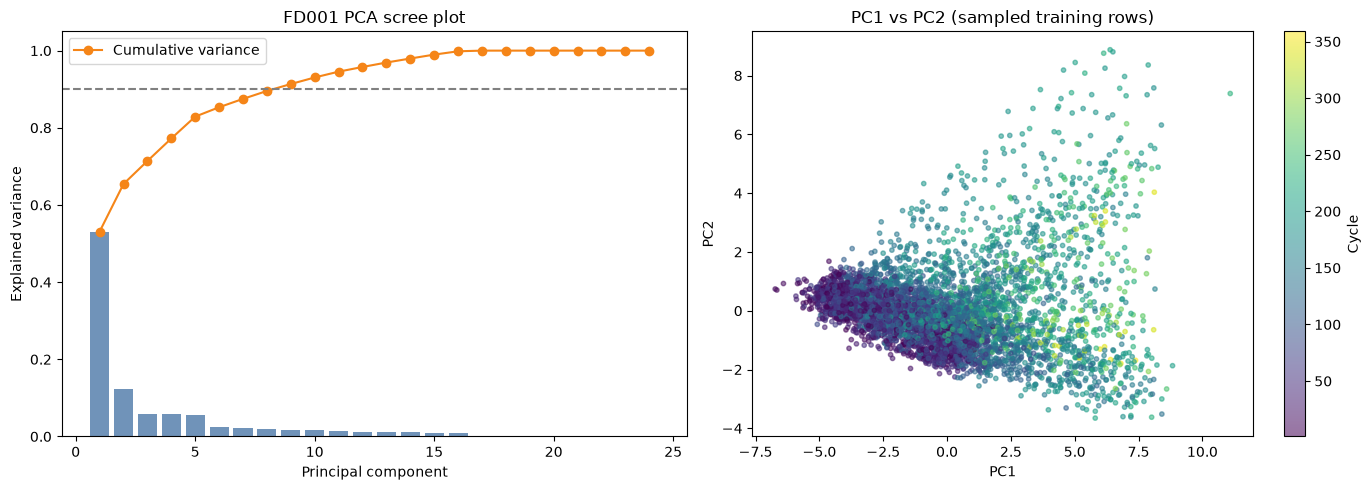

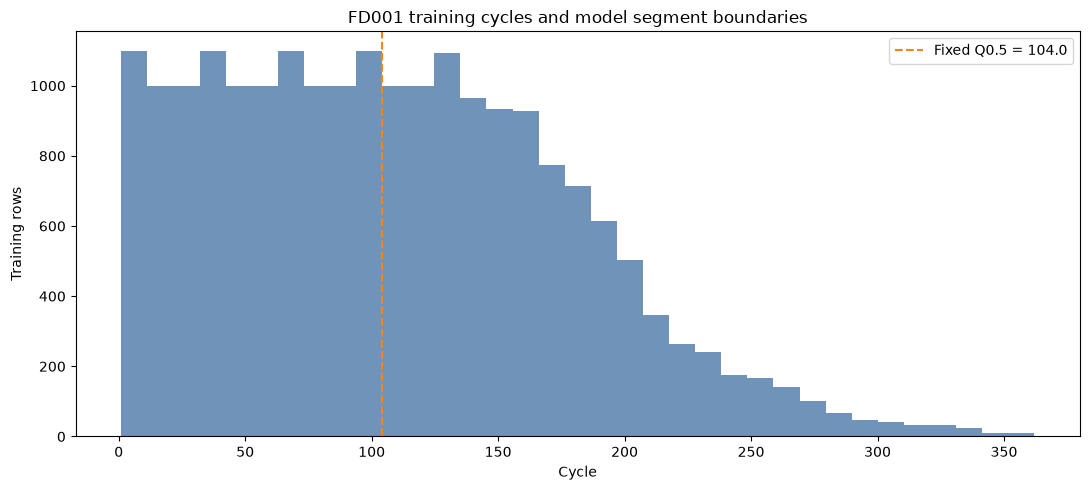

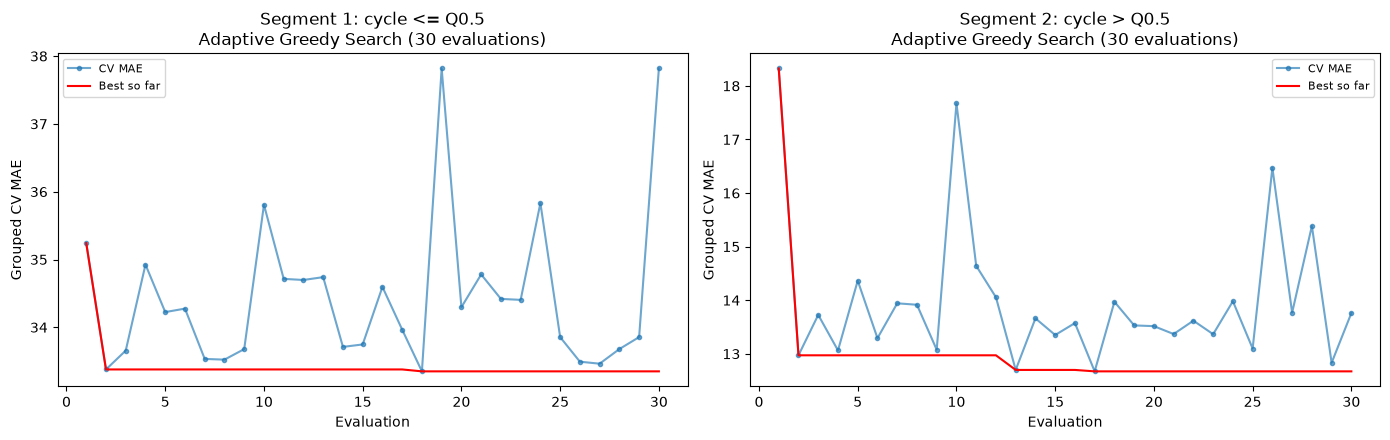

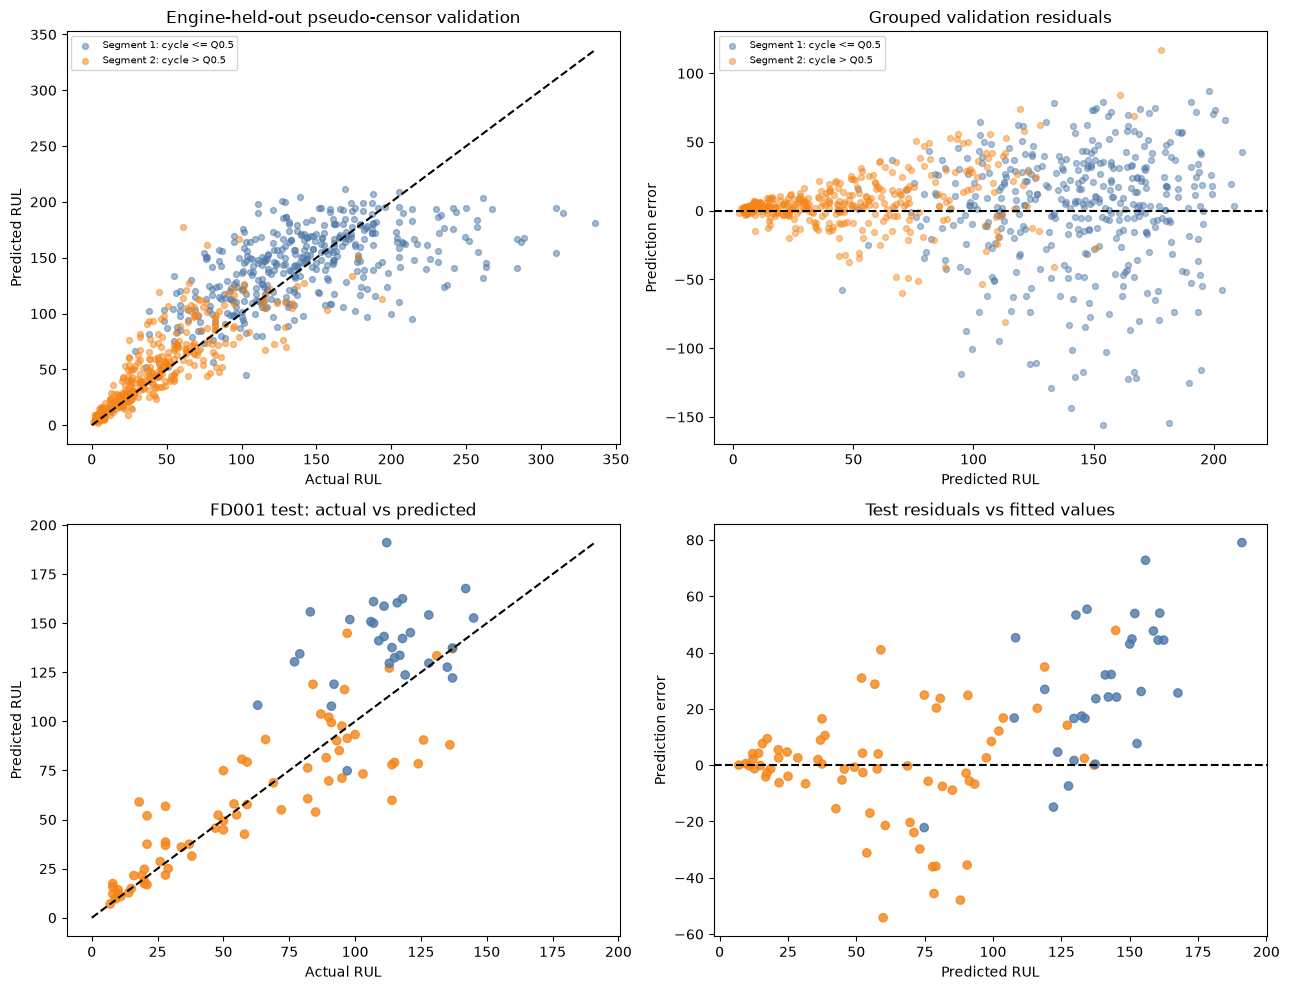

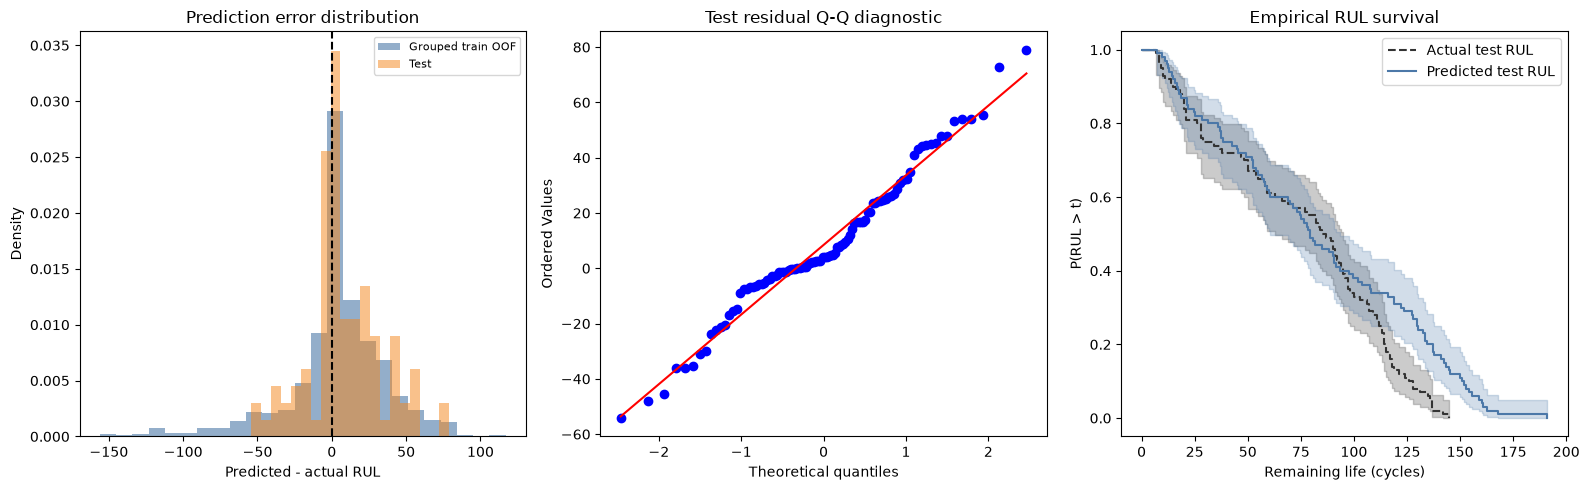


Segment 1: cycle <= Q0.5: top mean absolute SHAP values
cycle__cycle: 21.8795
pca__pca0: 12.7419
pca__pca1: 5.9255
pca__pca10: 0.8788
pca__pca8: 0.6751
pca__pca6: 0.6025
pca__pca9: 0.5686
pca__pca2: 0.5395
pca__pca5: 0.4613
pca__pca11: 0.3737


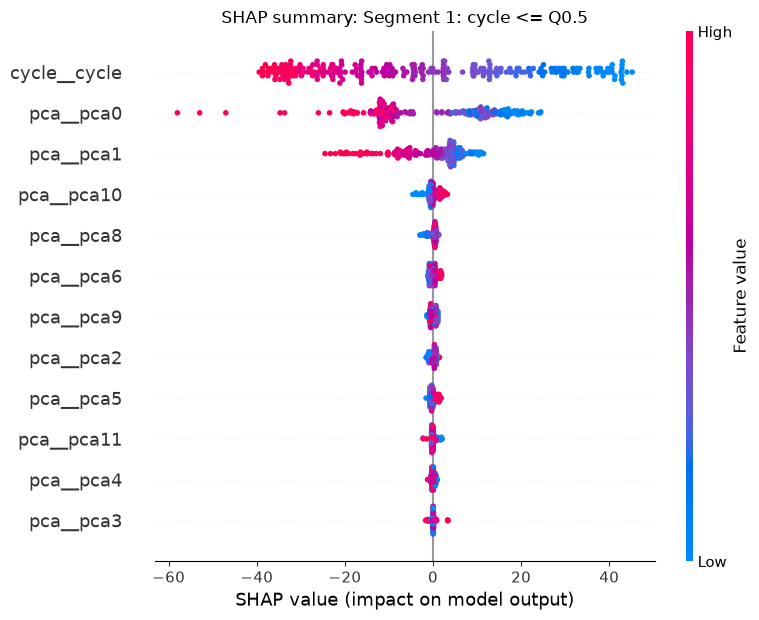

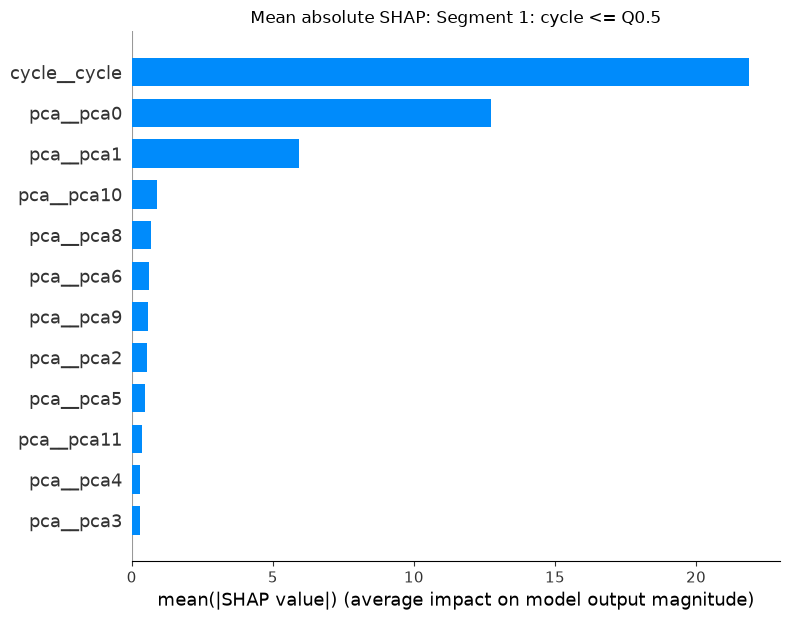


Segment 2: cycle > Q0.5: top mean absolute SHAP values
pca__pca0: 28.3560
pca__pca1: 11.0057
cycle__cycle: 1.8835
pca__pca7: 0.5352
pca__pca8: 0.5312
pca__pca6: 0.4746
pca__pca5: 0.3908
pca__pca2: 0.2975
pca__pca4: 0.1919
pca__pca3: 0.1799


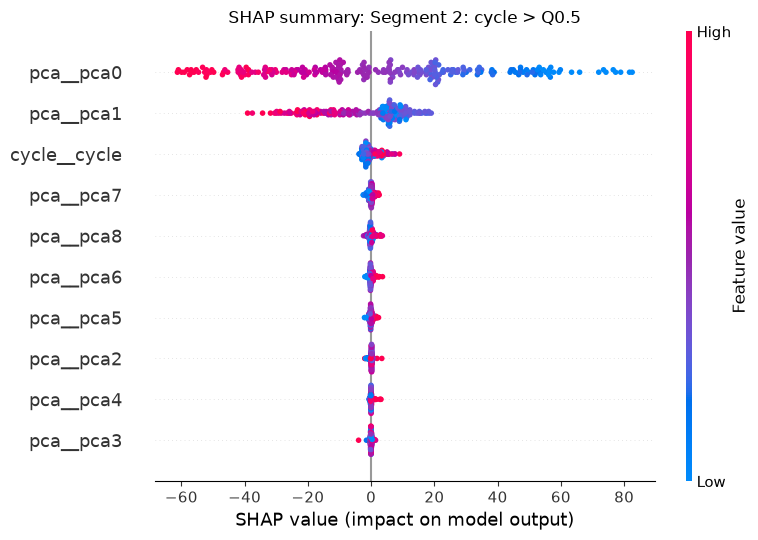

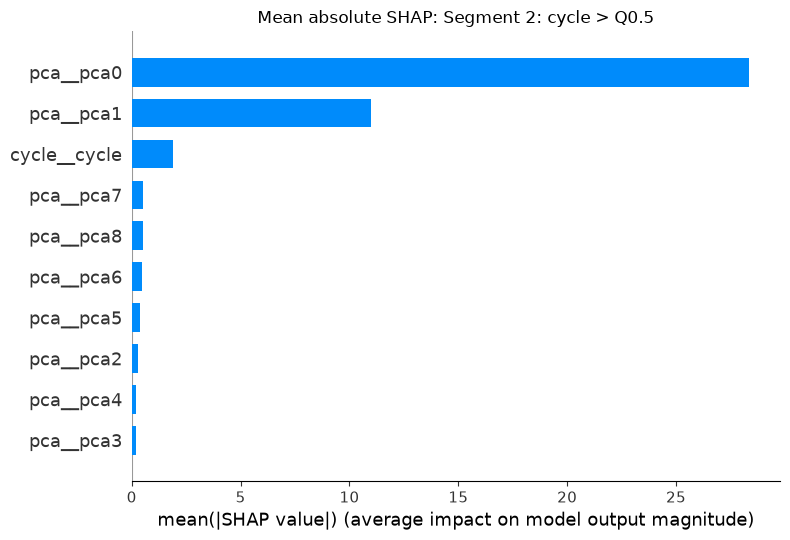

In [16]:
# Fit two fixed-Q0.5 PCA-XGBoost models with 30-evaluation Adaptive Greedy Search and Tree SHAP.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import shap
import xgboost as xgb
from ags import AdaptiveGreedySearch
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_test_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy(dtype=float)

# Target is residual life T - cycle; all operating settings and sensors enter PCA.
train_failure_cycle = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.reset_index(drop=True).copy()
train_rows["failure_cycle_T"] = train_rows["engine_id"].map(train_failure_cycle)
train_rows["remaining_life"] = (
    train_rows["failure_cycle_T"] - train_rows["cycle"]
).astype(float)
pca_features = columns[2:]
feature_columns = ["cycle", *pca_features]
X_train = train_rows[feature_columns].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
engine_groups = train_rows["engine_id"].to_numpy()

# Freeze the training-data median (50th-percentile) as the common cycle threshold for train and test.
threshold = float(train_rows["cycle"].quantile(0.5))
segment_names = ["Segment 1: cycle <= Q0.5", "Segment 2: cycle > Q0.5"]
train_segment = np.where(train_rows["cycle"].to_numpy() <= threshold, segment_names[0], segment_names[1])
segment_masks = {name: train_segment == name for name in segment_names}

test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test = test_last[feature_columns].astype(float)
test_cycles = test_last["cycle"].to_numpy(dtype=float)
test_segment = np.where(test_cycles <= threshold, segment_names[0], segment_names[1])
assert len(train_rows) == 20631 and train_raw["engine_id"].nunique() == 100
assert len(test_last) == len(actual_test_rul) == 100
assert test_last["engine_id"].tolist() == list(range(1, 101))
print(
    f"FD001 training rows={len(train_rows):,}; engines={train_raw['engine_id'].nunique()}; "
    f"test engines={len(test_last)}"
)
print(f"Fixed training Q0.5 cycle threshold: {threshold:.1f}")
print("Training rows by segment:", {
    name: int(mask.sum()) for name, mask in segment_masks.items()
})
constant_inputs = [name for name in pca_features if train_rows[name].nunique() <= 1]
print("Operating settings included:", [name for name in pca_features if name.startswith("setting_")])
print("Constant PCA inputs (included but contain no varying signal):", constant_inputs)

# Descriptive scree diagnostics use training data; fitted pipelines repeat PCA within each fold.
diagnostic_scaler = StandardScaler()
diagnostic_scaled = diagnostic_scaler.fit_transform(train_rows[pca_features].astype(float))
diagnostic_pca = PCA(svd_solver="full")
diagnostic_scores = diagnostic_pca.fit_transform(diagnostic_scaled)
cumulative_variance = np.cumsum(diagnostic_pca.explained_variance_ratio_)
n_components_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
print(
    f"Training PCA components to explain >=90% variance: "
    f"{n_components_90}/{len(pca_features)}"
)
print(f"First two PCs explain {cumulative_variance[1]:.3f} of training variance.")

# Cycle is retained directly; scaler and PCA are fit using each fold's training engines only.
def make_pipeline(params=None, n_jobs=1):
    preprocessor = ColumnTransformer(
        transformers=[
            ("cycle", "passthrough", ["cycle"]),
            (
                "pca",
                Pipeline([
                    ("scale", StandardScaler()),
                    ("reduce", PCA(n_components=0.90, svd_solver="full")),
                ]),
                pca_features,
            ),
        ],
        remainder="drop",
    )
    xgb_params = {
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": n_jobs,
        "verbosity": 0,
    }
    if params:
        xgb_params.update(params)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", xgb.XGBRegressor(**xgb_params)),
    ])

# Engine-disjoint folds evaluate multiple pseudo-censoring cutoffs per held-out engine.
row_at_cycle = {
    int(engine_id): {int(cycle): int(index) for cycle, index in zip(group["cycle"], group.index)}
    for engine_id, group in train_rows.groupby("engine_id")
}
grouped_splits = []
for fit_indices, held_out_rows in GroupKFold(n_splits=3).split(
    X_train, y_train, groups=engine_groups
):
    validation_indices = []
    for engine_id in np.unique(engine_groups[held_out_rows]):
        failure_cycle = int(train_failure_cycle.loc[engine_id])
        for fraction in (0.25, 0.50, 0.75, 0.95):
            early_cutoff = min(
                failure_cycle - 1, max(1, int(round(threshold * fraction)))
            )
            late_cutoff = min(
                failure_cycle - 1,
                max(threshold + 1, int(round(threshold + (failure_cycle - threshold) * fraction))),
            )
            validation_indices.append(row_at_cycle[int(engine_id)][early_cutoff])
            validation_indices.append(row_at_cycle[int(engine_id)][late_cutoff])
    validation_indices = np.asarray(validation_indices, dtype=int)
    if np.intersect1d(engine_groups[fit_indices], engine_groups[validation_indices]).size:
        raise AssertionError("Engine leakage found in grouped validation.")
    grouped_splits.append((fit_indices, validation_indices))

segment_splits = {}
for name, mask in segment_masks.items():
    splits = []
    for fit_indices, validation_indices in grouped_splits:
        fit_segment = fit_indices[mask[fit_indices]]
        validation_segment = validation_indices[mask[validation_indices]]
        if not len(fit_segment) or not len(validation_segment):
            raise ValueError(f"Empty train or validation rows for {name}.")
        splits.append((fit_segment, validation_segment))
    segment_splits[name] = splits
    print(
        f"{name}: fold train rows={[len(fit) for fit, _ in splits]}; "
        f"validation cutoffs={[len(valid) for _, valid in splits]}"
    )

def grouped_cv_mae(params, splits):
    scores = []
    for fit_indices, validation_indices in splits:
        model = make_pipeline(params=params, n_jobs=1)
        model.fit(X_train.iloc[fit_indices], y_train[fit_indices])
        predicted = np.maximum(0.0, model.predict(X_train.iloc[validation_indices]))
        scores.append(mean_absolute_error(y_train[validation_indices], predicted))
    return float(np.mean(scores))

class PrecomputedSplits:
    def __init__(self, splits):
        self.splits = splits

    def split(self, X, y=None):
        return iter(self.splits)

    def get_n_splits(self, X=None, y=None):
        return len(self.splits)

ags_grid = {
    "model__n_estimators": [60, 100, 140, 180, 220, 260],
    "model__max_depth": [2, 3, 4, 5, 6, 7],
    "model__learning_rate": [0.015, 0.025, 0.04, 0.06, 0.10, 0.15],
    "model__min_child_weight": [1, 2, 4, 6, 8, 10],
    "model__subsample": [0.65, 0.75, 0.85, 1.0],
    "model__colsample_bytree": [0.65, 0.75, 0.85, 1.0],
    "model__reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
    "model__gamma": [0.0, 0.25, 0.75, 1.5, 3.0],
}

# Tune both cycle segments with 30 Adaptive Greedy Search evaluations each.
segment_searches = {}
best_params = {}
for segment_index, name in enumerate(segment_names):
    search = AdaptiveGreedySearch(
        estimator=make_pipeline(n_jobs=1), param_grid=ags_grid, cv=3,
        scoring="neg_mean_absolute_error", max_evaluations=30,
        n_climbers=5, n_jobs=1, random_state=42 + segment_index,
        enable_pruning=False, candidate_pool_size=128,
    )
    search._cv_splitter = PrecomputedSplits(segment_splits[name])
    print(f"\nTuning {name} with 30 Adaptive Greedy Search evaluations...")
    search.fit(X_train, y_train)
    params = {
        key.removeprefix("model__"): value
        for key, value in dict(search.best_params).items()
    }
    segment_searches[name] = {"method": "Adaptive Greedy Search", "search": search}
    best_params[name] = params
    print("Best grouped-CV MAE:", round(-float(search.best_score), 3))
    print("Completed evaluations:", len(search.completed_evaluations))
    print("Best parameters:", params)

# Refit the chosen PCA/XGBoost pipeline separately for each cycle segment.
segment_models = {}
for name in segment_names:
    model = make_pipeline(params=best_params[name], n_jobs=-1)
    mask = segment_masks[name]
    model.fit(X_train.loc[mask], y_train[mask])
    segment_models[name] = model
    fitted_pca = (
        model.named_steps["preprocessor"]
        .named_transformers_["pca"]
        .named_steps["reduce"]
    )
    print(f"{name}: final model retained {fitted_pca.n_components_} PCs.")

# Apparent fit and grouped held-out pseudo-censor performance are kept separate.
apparent_rows = []
for name in segment_names:
    mask = segment_masks[name]
    actual = y_train[mask]
    predicted = np.maximum(0.0, segment_models[name].predict(X_train.loc[mask]))
    apparent_rows.append({
        "Segment": name,
        "Rows": int(mask.sum()),
        "Apparent MAE": mean_absolute_error(actual, predicted),
        "Apparent RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "Apparent R2": r2_score(actual, predicted),
    })
apparent_results = pd.DataFrame(apparent_rows).set_index("Segment")

oof_rows = []
for name in segment_names:
    for fold_number, (fit_indices, validation_indices) in enumerate(segment_splits[name], 1):
        model = make_pipeline(params=best_params[name], n_jobs=1)
        model.fit(X_train.iloc[fit_indices], y_train[fit_indices])
        predicted = np.maximum(0.0, model.predict(X_train.iloc[validation_indices]))
        for row_index, prediction in zip(validation_indices, predicted):
            oof_rows.append({
                "engine_id": int(train_rows.iloc[row_index]["engine_id"]),
                "cycle": float(train_rows.iloc[row_index]["cycle"]),
                "segment": name,
                "actual_RUL": float(y_train[row_index]),
                "predicted_RUL": float(prediction),
                "fold": fold_number,
            })
oof = pd.DataFrame(oof_rows)
oof["error"] = oof["predicted_RUL"] - oof["actual_RUL"]
oof_rows_by_segment = []
for name in segment_names:
    subset = oof[oof["segment"] == name]
    oof_rows_by_segment.append({
        "Segment": name,
        "Pseudo-censor rows": len(subset),
        "Held-out engines": subset["engine_id"].nunique(),
        "Grouped CV MAE": mean_absolute_error(subset["actual_RUL"], subset["predicted_RUL"]),
        "Grouped CV RMSE": mean_squared_error(subset["actual_RUL"], subset["predicted_RUL"]) ** 0.5,
        "Grouped CV R2": r2_score(subset["actual_RUL"], subset["predicted_RUL"]),
    })
oof_results = pd.DataFrame(oof_rows_by_segment).set_index("Segment")
print("\nApparent training fit (optimistic):")
print(apparent_results.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nEngine-held-out pseudo-censor validation:")
print(oof_results.to_string(float_format=lambda value: f"{value:.3f}"))

# Predict each test engine at its final observed cycle using the matching segment model.
test_predictions = np.empty(len(test_last), dtype=float)
for name in segment_names:
    mask = test_segment == name
    if mask.any():
        test_predictions[mask] = np.maximum(
            0.0, segment_models[name].predict(X_test.loc[mask])
        )
test_error = test_predictions - actual_test_rul
test_metric_rows = []
for name in segment_names:
    mask = test_segment == name
    test_metric_rows.append({
        "Segment": name,
        "Test engines": int(mask.sum()),
        "MAE": mean_absolute_error(actual_test_rul[mask], test_predictions[mask]),
        "RMSE": mean_squared_error(actual_test_rul[mask], test_predictions[mask]) ** 0.5,
        "R2": r2_score(actual_test_rul[mask], test_predictions[mask]) if mask.sum() > 1 else np.nan,
    })
test_segment_results = pd.DataFrame(test_metric_rows).set_index("Segment")
test_metrics = pd.Series({
    "Test engines": len(actual_test_rul),
    "C-index": concordance_index(actual_test_rul, test_predictions),
    "MAE (cycles)": mean_absolute_error(actual_test_rul, test_predictions),
    "RMSE (cycles)": mean_squared_error(actual_test_rul, test_predictions) ** 0.5,
    "R2": r2_score(actual_test_rul, test_predictions),
    "Median predicted RUL": float(np.median(test_predictions)),
    "Median actual RUL": float(np.median(actual_test_rul)),
})
print("\nTest results by segment:")
print(test_segment_results.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nOverall FD001 test-engine metrics:")
print(test_metrics.to_string(float_format=lambda value: f"{value:.3f}"))

# Residual tests are diagnostic only; normal errors are not an XGBoost requirement.
def residual_diagnostics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = predicted - actual
    shapiro_result = stats.shapiro(errors) if 3 <= len(errors) <= 5000 else None
    wilcoxon_result = stats.wilcoxon(errors) if np.any(errors != 0) else None
    abs_error_rho, abs_error_p = stats.spearmanr(np.abs(errors), predicted)
    return {
        "Shapiro residual p-value": float(shapiro_result.pvalue) if shapiro_result else np.nan,
        "Wilcoxon median-zero p-value": float(wilcoxon_result.pvalue) if wilcoxon_result else np.nan,
        "Spearman |error|-prediction rho": float(abs_error_rho),
        "Spearman |error|-prediction p-value": float(abs_error_p),
    }
diagnostics = pd.DataFrame({
    "Grouped train pseudo-censor OOF": residual_diagnostics(
        oof["actual_RUL"], oof["predicted_RUL"]
    ),
    "Test engines": residual_diagnostics(actual_test_rul, test_predictions),
}).T
print("\nResidual diagnostic tests (descriptive; OOF cutoffs share engines):")
print(diagnostics.to_string(float_format=lambda value: f"{value:.4g}"))

# PCA variance and score plots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
component_numbers = np.arange(1, len(cumulative_variance) + 1)
axes[0].bar(component_numbers, diagnostic_pca.explained_variance_ratio_, color="#4c78a8", alpha=0.8)
axes[0].plot(component_numbers, cumulative_variance, color="#f58518", marker="o", label="Cumulative variance")
axes[0].axhline(0.90, color="gray", linestyle="--")
axes[0].set(title="FD001 PCA scree plot", xlabel="Principal component", ylabel="Explained variance")
axes[0].legend()
sample_rows = np.linspace(0, len(diagnostic_scores) - 1, min(5000, len(diagnostic_scores)), dtype=int)
scatter = axes[1].scatter(
    diagnostic_scores[sample_rows, 0], diagnostic_scores[sample_rows, 1],
    c=train_rows.iloc[sample_rows]["cycle"], cmap="viridis", s=10, alpha=0.55,
)
axes[1].set(title="PC1 vs PC2 (sampled training rows)", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=axes[1], label="Cycle")
fig.tight_layout()
plt.show()

# Training cycle quantiles and segment sizes.
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(train_rows["cycle"], bins=35, color="#4c78a8", alpha=0.8)
ax.axvline(threshold, color="#f58518", linestyle="--", label=f"Fixed Q0.5 = {threshold:.1f}")
ax.set(title="FD001 training cycles and model segment boundaries", xlabel="Cycle", ylabel="Training rows")
ax.legend()
fig.tight_layout()
plt.show()

# Search histories for the two 30-evaluation Adaptive Greedy searches.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, segment_names):
    scores = [-float(value) for value in segment_searches[name]["search"].completed_evaluations.values()]
    ax.plot(np.arange(1, len(scores) + 1), scores, marker=".", alpha=0.65, label="CV MAE")
    ax.plot(np.arange(1, len(scores) + 1), np.minimum.accumulate(scores), color="red", label="Best so far")
    ax.set(title=f"{name}\nAdaptive Greedy Search (30 evaluations)", xlabel="Evaluation", ylabel="Grouped CV MAE")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Grouped OOF and test calibration and residuals.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
colors = dict(zip(segment_names, ("#4c78a8", "#f58518", "#54a24b")))
for name in segment_names:
    subset = oof[oof["segment"] == name]
    axes[0, 0].scatter(subset["actual_RUL"], subset["predicted_RUL"], s=18, alpha=0.5, color=colors[name], label=name)
limit = max(float(oof["actual_RUL"].max()), float(oof["predicted_RUL"].max()))
axes[0, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[0, 0].set(title="Engine-held-out pseudo-censor validation", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[0, 0].legend(fontsize=7)
for name in segment_names:
    subset = oof[oof["segment"] == name]
    axes[0, 1].scatter(subset["predicted_RUL"], subset["error"], s=18, alpha=0.45, color=colors[name], label=name)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Grouped validation residuals", xlabel="Predicted RUL", ylabel="Prediction error")
axes[0, 1].legend(fontsize=7)
test_colors = [colors[name] for name in test_segment]
axes[1, 0].scatter(actual_test_rul, test_predictions, c=test_colors, alpha=0.8)
limit = max(float(actual_test_rul.max()), float(test_predictions.max()))
axes[1, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[1, 0].set(title="FD001 test: actual vs predicted", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[1, 1].scatter(test_predictions, test_error, c=test_colors, alpha=0.8)
axes[1, 1].axhline(0, color="black", linestyle="--")
axes[1, 1].set(title="Test residuals vs fitted values", xlabel="Predicted RUL", ylabel="Prediction error")
fig.tight_layout()
plt.show()

# Residual distribution, Q-Q plot, and empirical actual/predicted survival curves.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].hist(oof["error"], bins=25, density=True, alpha=0.6, color="#4c78a8", label="Grouped train OOF")
axes[0].hist(test_error, bins=20, density=True, alpha=0.5, color="#f58518", label="Test")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title="Prediction error distribution", xlabel="Predicted - actual RUL", ylabel="Density")
axes[0].legend(fontsize=8)
stats.probplot(test_error, dist="norm", plot=axes[1])
axes[1].set(title="Test residual Q-Q diagnostic")
KaplanMeierFitter().fit(
    actual_test_rul, event_observed=np.ones(len(actual_test_rul)), label="Actual test RUL"
).plot_survival_function(ax=axes[2], ci_show=True, color="#333333", linestyle="--")
KaplanMeierFitter().fit(
    test_predictions, event_observed=np.ones(len(test_predictions)), label="Predicted test RUL"
).plot_survival_function(ax=axes[2], ci_show=True, color="#4c78a8")
axes[2].set(title="Empirical RUL survival", xlabel="Remaining life (cycles)", ylabel="P(RUL > t)")
fig.tight_layout()
plt.show()

# Explain each fitted segment model with SHAP TreeExplainer on PCA-transformed training examples.
shap_explanations = {}
for name in segment_names:
    segment_rows = X_train.loc[segment_masks[name]]
    sample = segment_rows.sample(n=min(250, len(segment_rows)), random_state=42)
    model = segment_models[name]
    transformed = model.named_steps["preprocessor"].transform(sample)
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()
    explainer = shap.TreeExplainer(model.named_steps["model"])
    explanation = explainer(transformed)
    shap_explanations[name] = explanation
    mean_abs_shap = np.abs(explanation.values).mean(axis=0)
    order = np.argsort(mean_abs_shap)[::-1]
    print(f"\n{name}: top mean absolute SHAP values")
    for feature_index in order[:10]:
        print(f"{feature_names[feature_index]}: {mean_abs_shap[feature_index]:.4f}")
    plt.figure(figsize=(10, 6))
    shap.summary_plot(explanation.values, transformed, feature_names=feature_names, show=False, max_display=12)
    plt.title(f"SHAP summary: {name}")
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(10, 6))
    shap.summary_plot(explanation.values, transformed, feature_names=feature_names, plot_type="bar", show=False, max_display=12)
    plt.title(f"Mean absolute SHAP: {name}")
    plt.tight_layout()
    plt.show()


**Discussion.** Both PCA-XGBoost models now use the fixed training-cycle Q0.5 knot at cycle 104. This model uses all varying operating settings and sensors, separate PCA transforms (12 early and 9 late components), and 30 AGS evaluations per segment. Grouped pseudo-censor validation MAE/RMSE/R-squared are 33.354/44.053/0.326 early and 12.705/20.053/0.663 late. On the 100 test engines, the aggregate metrics are C-index 0.836, MAE 19.128 cycles, RMSE 26.404, and R-squared 0.596. The early test segment has 31 engines and MAE 31.593 (R-squared -2.785); the late segment has 69 engines and MAE 13.528 (R-squared 0.746). The early estimate is weak and the negative R-squared means it does worse than predicting that segment's test-label mean. Component-level SHAP does not attribute directly to individual sensors.

Fixed Q0.5 knot: {np.float64(0.5): np.float64(104.0)}
All variable operating settings and sensors are screened for PCA: ['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


knot=104, fold=1: validation rows=198, MAE=21.048


knot=104, fold=2: validation rows=204, MAE=25.342


knot=104, fold=3: validation rows=198, MAE=24.458

Grouped pseudo-censor scores at the fixed Q0.5 knot:
 Knot cycle  Knot quantile  Validation MAE  Validation RMSE  Fold MAE SD  Fold RMSE SD  Validation rows
    104.000          0.500          23.634           32.752        2.267         1.953              600

Fixed Q0.5 knot: cycle 104 (training cycle-row quantile 0.500); grouped pseudo-censor MAE=23.634, RMSE=32.752.
Selection method: fixed training-cycle Q0.5; 3-fold engine-grouped pseudo-censor validation (no knot tuning).


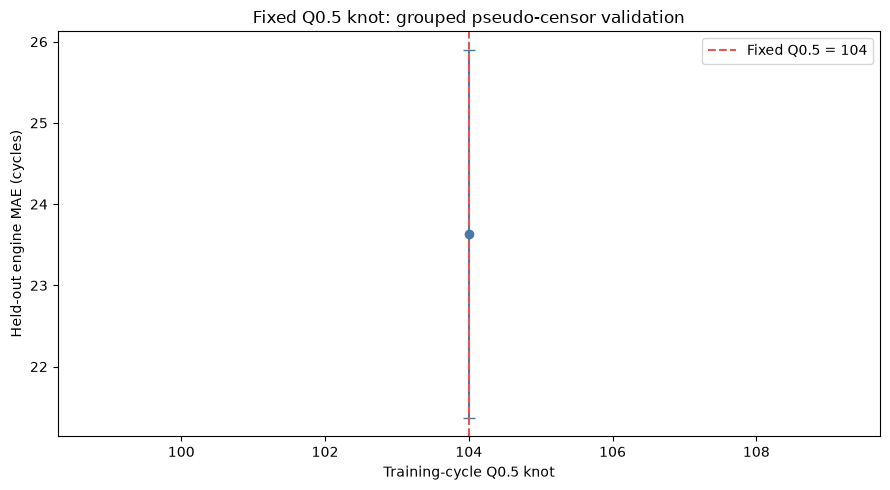

In [17]:
# Validate a fixed Q0.5 knot using engine-grouped pseudo-censor validation for PCA-XGBoost.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

columns = [
    "engine_id", "cycle", "setting_1", "setting_2", "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+", header=None, names=columns,
)
actual_test_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+", header=None, names=["RUL"],
)["RUL"].to_numpy(dtype=float)

train_failure_cycle = train_raw.groupby("engine_id")["cycle"].max()
train_rows = train_raw.reset_index(drop=True).copy()
train_rows["failure_cycle_T"] = train_rows["engine_id"].map(train_failure_cycle)
train_rows["remaining_life"] = (
    train_rows["failure_cycle_T"] - train_rows["cycle"]
).astype(float)
predictor_columns = [
    col for col in columns[2:] if train_rows[col].nunique() > 1
]
model_columns = ["cycle", *predictor_columns]
X_train = train_rows[model_columns].astype(float)
y_train = train_rows["remaining_life"].to_numpy()
engine_groups = train_rows["engine_id"].to_numpy()

test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False).tail(1)
    .sort_values("engine_id").reset_index(drop=True)
)
X_test = test_last[model_columns].astype(float)
test_cycles = test_last["cycle"].to_numpy(dtype=float)
assert len(train_rows) == 20631 and train_raw["engine_id"].nunique() == 100
assert len(test_last) == len(actual_test_rul) == 100

# Fix the knot at the median of training cycle-row values (Q0.5).
knot_quantiles = np.array([0.5])
knot_candidates = np.unique(
    np.quantile(train_rows["cycle"].to_numpy(), knot_quantiles).astype(float)
)
if len(knot_candidates) < 1:
    raise ValueError("The training-cycle median did not produce a valid knot.")
print("Fixed Q0.5 knot:", dict(zip(knot_quantiles.round(2), knot_candidates)))
print("All variable operating settings and sensors are screened for PCA:", predictor_columns)

# Create six pseudo-censor cutoffs per held-out engine; no engine appears in both sets.
row_at_cycle = {
    int(engine_id): {
        int(cycle): int(index)
        for cycle, index in zip(group["cycle"], group.index)
    }
    for engine_id, group in train_rows.groupby("engine_id")
}
grouped_validation_splits = []
for fit_indices, held_out_rows in GroupKFold(n_splits=3).split(
    X_train, y_train, groups=engine_groups
):
    validation_indices = []
    for engine_id in np.unique(engine_groups[held_out_rows]):
        failure_cycle = int(train_failure_cycle.loc[engine_id])
        for fraction in (0.20, 0.35, 0.50, 0.65, 0.80, 0.95):
            cutoff = min(
                failure_cycle - 1,
                max(1, int(round(failure_cycle * fraction))),
            )
            validation_indices.append(row_at_cycle[int(engine_id)][cutoff])
    validation_indices = np.asarray(validation_indices, dtype=int)
    if np.intersect1d(
        engine_groups[fit_indices], engine_groups[validation_indices]
    ).size:
        raise AssertionError("Engine leakage found while constructing knot folds.")
    grouped_validation_splits.append((fit_indices, validation_indices))

def make_fixed_xgb(params=None, n_jobs=1):
    transform = ColumnTransformer(
        [
            ("cycle", "passthrough", ["cycle"]),
            (
                "pca",
                Pipeline([
                    ("scale", StandardScaler()),
                    ("reduce", PCA(n_components=0.90, svd_solver="full")),
                ]),
                predictor_columns,
            ),
        ],
        remainder="drop",
    )
    xgb_params = {
        "n_estimators": 100,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_lambda": 5.0,
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": n_jobs,
        "verbosity": 0,
    }
    if params:
        xgb_params.update(params)
    return Pipeline([
        ("preprocessor", transform),
        ("model", xgb.XGBRegressor(**xgb_params)),
    ])

# The fixed median knot is evaluated on engine-held-out pseudo-censor RUL; each PCA fit is fold-local.
knot_score_rows = []
for candidate in knot_candidates:
    all_actual = []
    all_predicted = []
    fold_mae = []
    fold_rmse = []
    for fold_number, (fit_indices, validation_indices) in enumerate(
        grouped_validation_splits, 1
    ):
        fit_cycles = train_rows.iloc[fit_indices]["cycle"].to_numpy()
        validation_cycles = train_rows.iloc[validation_indices]["cycle"].to_numpy()
        fold_predictions = np.full(len(validation_indices), np.nan, dtype=float)
        for is_early, train_segment_mask, validation_segment_mask in (
            (True, fit_cycles <= candidate, validation_cycles <= candidate),
            (False, fit_cycles > candidate, validation_cycles > candidate),
        ):
            segment_fit = fit_indices[train_segment_mask]
            segment_positions = np.flatnonzero(validation_segment_mask)
            if not len(segment_fit) or not len(segment_positions):
                continue
            model = make_fixed_xgb(n_jobs=1)
            model.fit(X_train.iloc[segment_fit], y_train[segment_fit])
            fold_predictions[segment_positions] = np.maximum(
                0.0,
                model.predict(
                    X_train.iloc[validation_indices[segment_positions]]
                ),
            )
        valid = np.isfinite(fold_predictions)
        if not valid.any():
            raise ValueError(f"No held-out predictions for candidate knot {candidate}.")
        observed = y_train[validation_indices][valid]
        predicted = fold_predictions[valid]
        all_actual.extend(observed.tolist())
        all_predicted.extend(predicted.tolist())
        fold_mae.append(mean_absolute_error(observed, predicted))
        fold_rmse.append(mean_squared_error(observed, predicted) ** 0.5)
        print(
            f"knot={candidate:g}, fold={fold_number}: "
            f"validation rows={int(valid.sum())}, MAE={fold_mae[-1]:.3f}"
        )
    knot_score_rows.append({
        "Knot cycle": float(candidate),
        "Knot quantile": float(knot_quantiles[0]),
        "Validation MAE": mean_absolute_error(all_actual, all_predicted),
        "Validation RMSE": mean_squared_error(all_actual, all_predicted) ** 0.5,
        "Fold MAE SD": float(np.std(fold_mae, ddof=1)),
        "Fold RMSE SD": float(np.std(fold_rmse, ddof=1)),
        "Validation rows": len(all_actual),
    })
knot_results = pd.DataFrame(knot_score_rows).sort_values("Knot cycle").reset_index(drop=True)
best_knot_row = knot_results.loc[knot_results["Validation MAE"].idxmin()]
optimal_knot = float(best_knot_row["Knot cycle"])
best_knot_quantile = float(best_knot_row["Knot quantile"])
print("\nGrouped pseudo-censor scores at the fixed Q0.5 knot:")
print(knot_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(
    f"\nFixed Q0.5 knot: cycle {optimal_knot:g} "
    f"(training cycle-row quantile {best_knot_quantile:.3f}); "
    f"grouped pseudo-censor MAE={best_knot_row['Validation MAE']:.3f}, "
    f"RMSE={best_knot_row['Validation RMSE']:.3f}."
)
print(
    "Selection method: fixed training-cycle Q0.5; "
    "3-fold engine-grouped pseudo-censor validation (no knot tuning)."
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    knot_results["Knot cycle"],
    knot_results["Validation MAE"],
    yerr=knot_results["Fold MAE SD"],
    marker="o", capsize=4, color="#4c78a8",
)
ax.axvline(optimal_knot, color="#e45756", linestyle="--", label=f"Fixed Q0.5 = {optimal_knot:g}")
ax.set(
    title="Fixed Q0.5 knot: grouped pseudo-censor validation",
    xlabel="Training-cycle Q0.5 knot",
    ylabel="Held-out engine MAE (cycles)",
)
ax.legend()
fig.tight_layout()
Path("images").mkdir(exist_ok=True)
fig.savefig(Path("images") / "knot_optimization.png", dpi=160, bbox_inches="tight")
plt.show()


**Discussion.** The knot is fixed at the training-cycle-row median, Q0.5 = cycle 104; the validation is not used to select among candidate knots. Three-fold engine-grouped pseudo-censor validation yielded pooled MAE 23.634 and RMSE 32.752 on 600 validation rows (fold MAEs 21.048, 25.342, and 24.458). The cycle split and validation use training data only; the fixed knot is then reused by the PCA-XGBoost and LSTM experiments. See [`segmented_regression_results.md`](./segmented_regression_results.md) for all updated results and limitations.

C:\Users\User\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using fixed Q0.5 knot cycle=104 (training quantile 0.500)
Training rows by segment: {'Early: cycle <= 104': 10400, 'Late: cycle > 104': 10231}
Test engines by segment: {'Late: cycle > 104': 69, 'Early: cycle <= 104': 31}

Tuning Early: cycle <= 104: 30 Adaptive Greedy Search evaluations...


Best grouped-validation MAE: 31.45
Completed evaluations: 30
Best parameters: {'n_estimators': 220, 'max_depth': 2, 'learning_rate': 0.025, 'min_child_weight': 1, 'subsample': 0.75, 'colsample_bytree': 1.0, 'reg_lambda': 10.0, 'gamma': 1.5}


Final model retained 12 PCs for >=90% variance.

Tuning Late: cycle > 104: 30 Adaptive Greedy Search evaluations...


Best grouped-validation MAE: 16.871
Completed evaluations: 30
Best parameters: {'n_estimators': 140, 'max_depth': 2, 'learning_rate': 0.06, 'min_child_weight': 4, 'subsample': 1.0, 'colsample_bytree': 0.85, 'reg_lambda': 0.1, 'gamma': 1.5}
Final model retained 9 PCs for >=90% variance.



Apparent training fit (optimistic):
                      Rows  Apparent MAE  Apparent RMSE  Apparent R2
Segment                                                             
Early: cycle <= 104  10400        32.269         42.958        0.390
Late: cycle > 104    10231        17.640         25.611        0.695

Engine-held-out pseudo-censor results:
                     Pseudo-censor rows  Held-out engines  Grouped CV MAE  Grouped CV RMSE  Grouped CV R2
Segment                                                                                                  
Early: cycle <= 104                 275               100          31.486           39.702          0.190
Late: cycle > 104                   325               100          16.876           25.267          0.651

Q0.5-knot test results:
Test engines           100.000
C-index                  0.830
MAE (cycles)            19.844
RMSE (cycles)           26.262
R2                       0.601
Median predicted RUL    81.041
Median actua

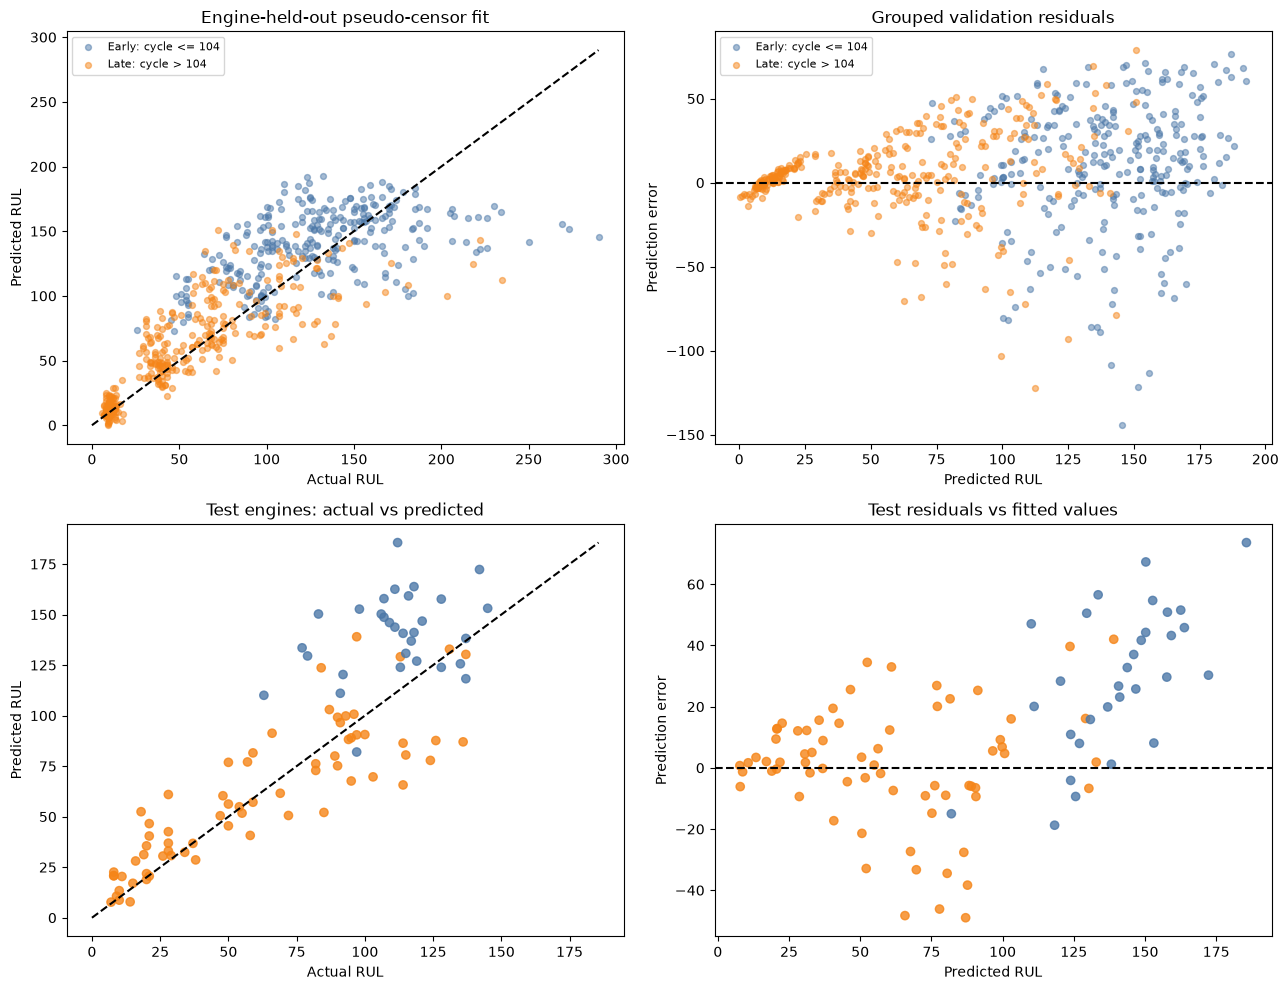

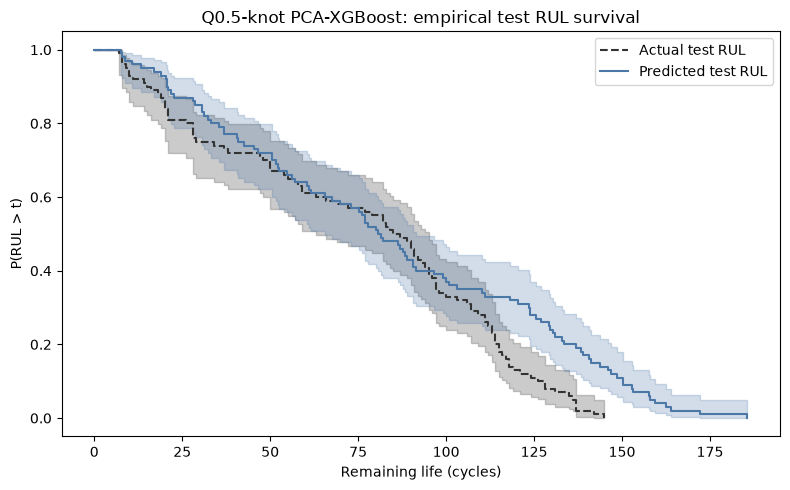

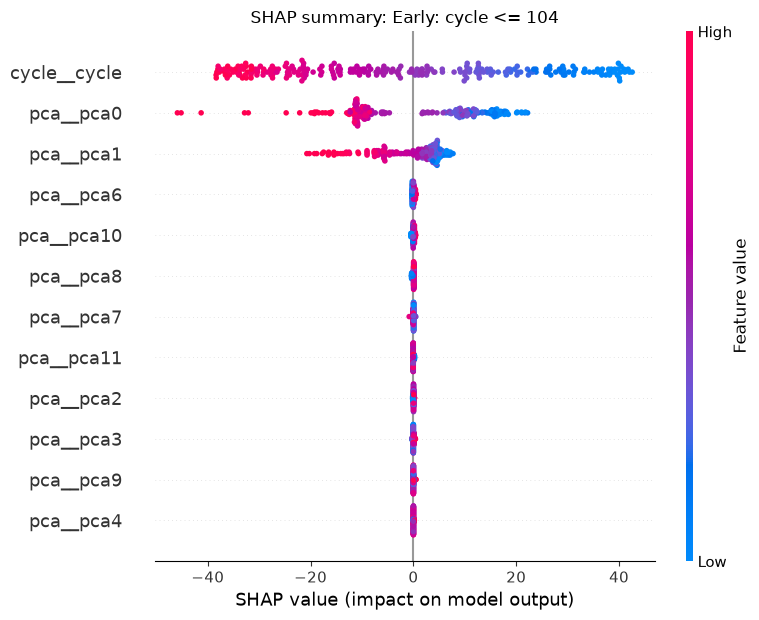

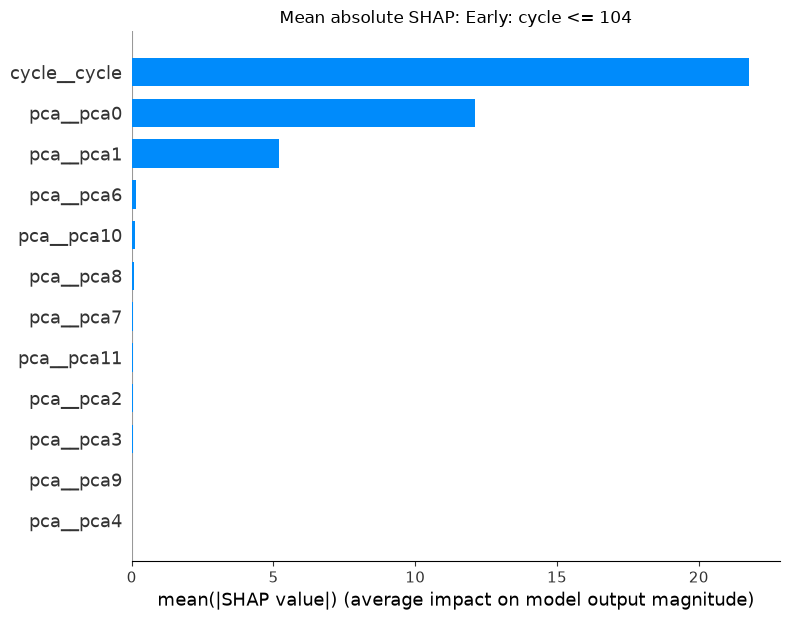

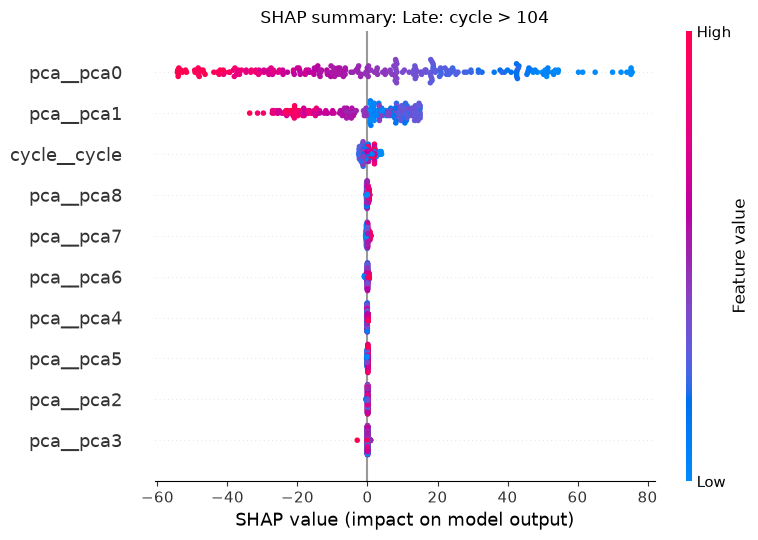

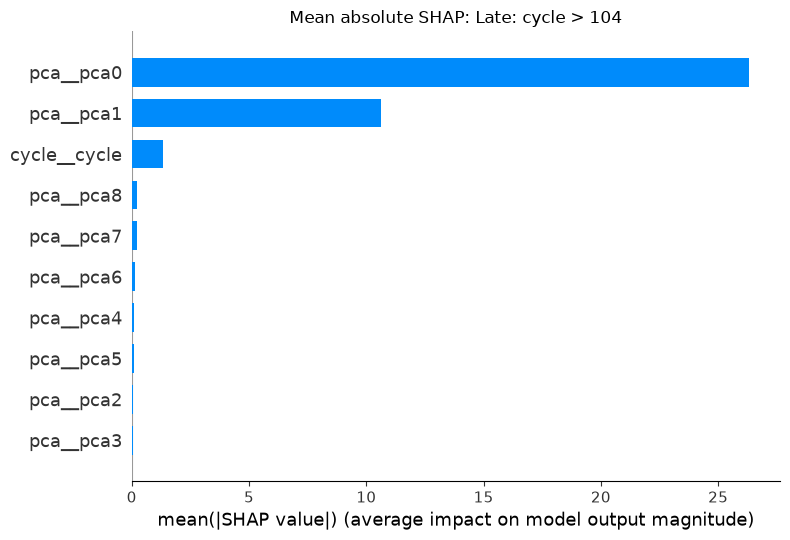

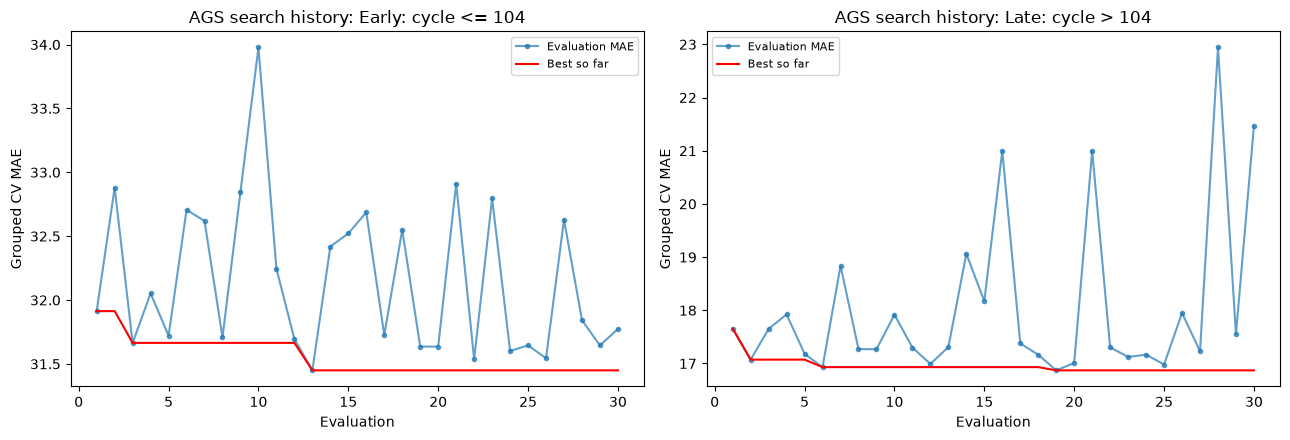

In [18]:
# Fit the fixed-Q0.5 PCA-XGBoost model with segment-specific AGS tuning and TreeExplainer SHAP.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import shap
import xgboost as xgb
from ags import AdaptiveGreedySearch
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

if "optimal_knot" not in globals():
    raise RuntimeError("Run the preceding knot-optimization cell first.")
images_dir = Path("images")
images_dir.mkdir(exist_ok=True)
knotted_segment_names = [
    f"Early: cycle <= {optimal_knot:g}",
    f"Late: cycle > {optimal_knot:g}",
]
train_cycle_values = train_rows["cycle"].to_numpy()
knotted_train_segments = np.where(
    train_cycle_values <= optimal_knot,
    knotted_segment_names[0],
    knotted_segment_names[1],
)
knotted_segment_masks = {
    name: knotted_train_segments == name for name in knotted_segment_names
}
knotted_test_segments = np.where(
    test_cycles <= optimal_knot,
    knotted_segment_names[0],
    knotted_segment_names[1],
)
print(f"Using fixed Q0.5 knot cycle={optimal_knot:g} (training quantile {best_knot_quantile:.3f})")
print("Training rows by segment:", {
    name: int(mask.sum()) for name, mask in knotted_segment_masks.items()
})
print("Test engines by segment:", pd.Series(knotted_test_segments).value_counts().to_dict())

def make_knotted_pipeline(params=None, n_jobs=1):
    preprocessor = ColumnTransformer(
        [
            ("cycle", "passthrough", ["cycle"]),
            (
                "pca",
                Pipeline([
                    ("scale", StandardScaler()),
                    ("reduce", PCA(n_components=0.90, svd_solver="full")),
                ]),
                predictor_columns,
            ),
        ],
        remainder="drop",
    )
    xgb_params = {
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": n_jobs,
        "verbosity": 0,
    }
    if params:
        xgb_params.update(params)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", xgb.XGBRegressor(**xgb_params)),
    ])

knotted_segment_splits = {}
for name, mask in knotted_segment_masks.items():
    splits = []
    for fit_indices, validation_indices in grouped_validation_splits:
        fit_segment = fit_indices[mask[fit_indices]]
        validation_segment = validation_indices[mask[validation_indices]]
        if not len(fit_segment) or not len(validation_segment):
            raise ValueError(f"Empty grouped fold for Q0.5 segment {name}.")
        splits.append((fit_segment, validation_segment))
    knotted_segment_splits[name] = splits

def knotted_cv_mae(params, splits):
    fold_scores = []
    for fit_indices, validation_indices in splits:
        model = make_knotted_pipeline(params=params, n_jobs=1)
        model.fit(X_train.iloc[fit_indices], y_train[fit_indices])
        predicted = np.maximum(0.0, model.predict(X_train.iloc[validation_indices]))
        fold_scores.append(
            mean_absolute_error(y_train[validation_indices], predicted)
        )
    return float(np.mean(fold_scores))

ags_grid = {
    "model__n_estimators": [60, 100, 140, 180, 220, 260],
    "model__max_depth": [2, 3, 4, 5, 6, 7],
    "model__learning_rate": [0.015, 0.025, 0.04, 0.06, 0.10, 0.15],
    "model__min_child_weight": [1, 2, 4, 6, 8, 10],
    "model__subsample": [0.65, 0.75, 0.85, 1.0],
    "model__colsample_bytree": [0.65, 0.75, 0.85, 1.0],
    "model__reg_lambda": [0.1, 0.5, 2.0, 5.0, 10.0, 20.0],
    "model__gamma": [0.0, 0.25, 0.75, 1.5, 3.0],
}

class KnottedPrecomputedSplits:
    def __init__(self, splits):
        self.splits = splits

    def split(self, X, y=None):
        return iter(self.splits)

    def get_n_splits(self, X=None, y=None):
        return len(self.splits)

# Independently tune each side of the fixed Q0.5 knot with 30 AGS evaluations.
knotted_searches = {}
knotted_best_params = {}
knotted_models = {}
for segment_index, name in enumerate(knotted_segment_names):
    search = AdaptiveGreedySearch(
        estimator=make_knotted_pipeline(n_jobs=1),
        param_grid=ags_grid,
        cv=3,
        scoring="neg_mean_absolute_error",
        max_evaluations=30,
        n_climbers=5,
        n_jobs=1,
        random_state=72 + segment_index,
        enable_pruning=False,
        candidate_pool_size=128,
    )
    search._cv_splitter = KnottedPrecomputedSplits(knotted_segment_splits[name])
    print(f"\nTuning {name}: 30 Adaptive Greedy Search evaluations...")
    search.fit(X_train, y_train)
    params = {
        key.removeprefix("model__"): value
        for key, value in dict(search.best_params).items()
    }
    knotted_searches[name] = search
    knotted_best_params[name] = params
    print("Best grouped-validation MAE:", round(-float(search.best_score), 3))
    print("Completed evaluations:", len(search.completed_evaluations))
    print("Best parameters:", params)
    model = make_knotted_pipeline(params=params, n_jobs=-1)
    model.fit(X_train.loc[knotted_segment_masks[name]], y_train[knotted_segment_masks[name]])
    knotted_models[name] = model
    pca_fit = (
        model.named_steps["preprocessor"]
        .named_transformers_["pca"]
        .named_steps["reduce"]
    )
    print(f"Final model retained {pca_fit.n_components_} PCs for >=90% variance.")

# Apparent segment-specific training metrics.
knotted_apparent_rows = []
for name in knotted_segment_names:
    mask = knotted_segment_masks[name]
    predicted = np.maximum(0.0, knotted_models[name].predict(X_train.loc[mask]))
    actual = y_train[mask]
    knotted_apparent_rows.append({
        "Segment": name,
        "Rows": int(mask.sum()),
        "Apparent MAE": mean_absolute_error(actual, predicted),
        "Apparent RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "Apparent R2": r2_score(actual, predicted),
    })
knotted_apparent = pd.DataFrame(knotted_apparent_rows).set_index("Segment")

# Cross-fitted predictions use the fixed Q0.5 knot and AGS parameters, holding engines out.
knotted_oof_rows = []
for name in knotted_segment_names:
    for fold_number, (fit_indices, validation_indices) in enumerate(
        knotted_segment_splits[name], 1
    ):
        model = make_knotted_pipeline(params=knotted_best_params[name], n_jobs=1)
        model.fit(X_train.iloc[fit_indices], y_train[fit_indices])
        predicted = np.maximum(0.0, model.predict(X_train.iloc[validation_indices]))
        for row_index, prediction in zip(validation_indices, predicted):
            knotted_oof_rows.append({
                "engine_id": int(train_rows.iloc[row_index]["engine_id"]),
                "cycle": float(train_rows.iloc[row_index]["cycle"]),
                "segment": name,
                "actual_RUL": float(y_train[row_index]),
                "predicted_RUL": float(prediction),
                "fold": fold_number,
            })
knotted_oof = pd.DataFrame(knotted_oof_rows)
knotted_oof["error"] = knotted_oof["predicted_RUL"] - knotted_oof["actual_RUL"]
knotted_oof_metrics = []
for name in knotted_segment_names:
    subset = knotted_oof[knotted_oof["segment"] == name]
    knotted_oof_metrics.append({
        "Segment": name,
        "Pseudo-censor rows": len(subset),
        "Held-out engines": subset["engine_id"].nunique(),
        "Grouped CV MAE": mean_absolute_error(subset["actual_RUL"], subset["predicted_RUL"]),
        "Grouped CV RMSE": mean_squared_error(subset["actual_RUL"], subset["predicted_RUL"]) ** 0.5,
        "Grouped CV R2": r2_score(subset["actual_RUL"], subset["predicted_RUL"]),
    })
knotted_oof_metrics = pd.DataFrame(knotted_oof_metrics).set_index("Segment")
print("\nApparent training fit (optimistic):")
print(knotted_apparent.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nEngine-held-out pseudo-censor results:")
print(knotted_oof_metrics.to_string(float_format=lambda value: f"{value:.3f}"))

# Score each test engine using the model for its last-observed-cycle segment.
knotted_test_predictions = np.empty(len(test_last), dtype=float)
for name in knotted_segment_names:
    mask = knotted_test_segments == name
    if mask.any():
        knotted_test_predictions[mask] = np.maximum(
            0.0, knotted_models[name].predict(X_test.loc[mask])
        )
knotted_test_error = knotted_test_predictions - actual_test_rul
knotted_test_metrics = {
    "Test engines": len(actual_test_rul),
    "C-index": concordance_index(actual_test_rul, knotted_test_predictions),
    "MAE (cycles)": mean_absolute_error(actual_test_rul, knotted_test_predictions),
    "RMSE (cycles)": mean_squared_error(actual_test_rul, knotted_test_predictions) ** 0.5,
    "R2": r2_score(actual_test_rul, knotted_test_predictions),
    "Median predicted RUL": float(np.median(knotted_test_predictions)),
    "Median actual RUL": float(np.median(actual_test_rul)),
}
print("\nQ0.5-knot test results:")
print(pd.Series(knotted_test_metrics).to_string(float_format=lambda value: f"{value:.3f}"))
print("Test engines by segment:", pd.Series(knotted_test_segments).value_counts().to_dict())

def regression_diagnostics(actual, predicted):
    error = np.asarray(predicted) - np.asarray(actual)
    shapiro = stats.shapiro(error) if 3 <= len(error) <= 5000 else None
    return {
        "Shapiro residual p-value": float(shapiro.pvalue) if shapiro else np.nan,
        "Wilcoxon error median-zero p-value": float(stats.wilcoxon(error).pvalue),
        "Spearman |error|-prediction rho": float(stats.spearmanr(np.abs(error), predicted).statistic),
    }
knotted_diagnostics = pd.DataFrame({
    "Grouped train pseudo-censor OOF": regression_diagnostics(
        knotted_oof["actual_RUL"], knotted_oof["predicted_RUL"]
    ),
    "Test engines": regression_diagnostics(actual_test_rul, knotted_test_predictions),
}).T
print("\nResidual diagnostics (descriptive; non-normal errors are not an XGBoost assumption):")
print(knotted_diagnostics.to_string(float_format=lambda value: f"{value:.4g}"))

# Diagnostic plots: grouped OOF/test calibration, residuals, and survival.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
colors = {knotted_segment_names[0]: "#4c78a8", knotted_segment_names[1]: "#f58518"}
for name in knotted_segment_names:
    subset = knotted_oof[knotted_oof["segment"] == name]
    axes[0, 0].scatter(subset["actual_RUL"], subset["predicted_RUL"], s=18, alpha=0.5, color=colors[name], label=name)
limit = max(float(knotted_oof["actual_RUL"].max()), float(knotted_oof["predicted_RUL"].max()))
axes[0, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[0, 0].set(title="Engine-held-out pseudo-censor fit", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[0, 0].legend(fontsize=8)
for name in knotted_segment_names:
    subset = knotted_oof[knotted_oof["segment"] == name]
    axes[0, 1].scatter(subset["predicted_RUL"], subset["error"], s=18, alpha=0.5, color=colors[name], label=name)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Grouped validation residuals", xlabel="Predicted RUL", ylabel="Prediction error")
axes[0, 1].legend(fontsize=8)
test_colors = [colors[name] for name in knotted_test_segments]
axes[1, 0].scatter(actual_test_rul, knotted_test_predictions, c=test_colors, alpha=0.8)
limit = max(float(actual_test_rul.max()), float(knotted_test_predictions.max()))
axes[1, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[1, 0].set(title="Test engines: actual vs predicted", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[1, 1].scatter(knotted_test_predictions, knotted_test_error, c=test_colors, alpha=0.8)
axes[1, 1].axhline(0, color="black", linestyle="--")
axes[1, 1].set(title="Test residuals vs fitted values", xlabel="Predicted RUL", ylabel="Prediction error")
fig.tight_layout()
fig.savefig(images_dir / "optimized_knot_xgb_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
KaplanMeierFitter().fit(
    actual_test_rul, event_observed=np.ones(len(actual_test_rul)), label="Actual test RUL"
).plot_survival_function(ax=ax, ci_show=True, color="#333333", linestyle="--")
KaplanMeierFitter().fit(
    knotted_test_predictions, event_observed=np.ones(len(knotted_test_predictions)),
    label="Predicted test RUL",
).plot_survival_function(ax=ax, ci_show=True, color="#4c78a8")
ax.set(title="Q0.5-knot PCA-XGBoost: empirical test RUL survival", xlabel="Remaining life (cycles)", ylabel="P(RUL > t)")
fig.tight_layout()
fig.savefig(images_dir / "optimized_knot_xgb_survival.png", dpi=160, bbox_inches="tight")
plt.show()

# TreeExplainer SHAP on each model's PCA-transformed rows.
knotted_shap_results = {}
for name in knotted_segment_names:
    sample = X_train.loc[knotted_segment_masks[name]].sample(
        n=min(250, int(knotted_segment_masks[name].sum())), random_state=42
    )
    model = knotted_models[name]
    transformed = model.named_steps["preprocessor"].transform(sample)
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()
    explanation = shap.TreeExplainer(model.named_steps["model"])(transformed)
    knotted_shap_results[name] = (explanation, transformed, feature_names)
    shap.summary_plot(
        explanation.values, transformed, feature_names=feature_names,
        show=False, max_display=12,
    )
    plt.title(f"SHAP summary: {name}")
    plt.tight_layout()
    plt.savefig(
        images_dir / f"optimized_knot_xgb_shap_{'early' if name == knotted_segment_names[0] else 'late'}.png",
        dpi=160, bbox_inches="tight",
    )
    plt.show()
    plt.figure(figsize=(9, 6))
    shap.summary_plot(
        explanation.values, transformed, feature_names=feature_names,
        plot_type="bar", show=False, max_display=12,
    )
    plt.title(f"Mean absolute SHAP: {name}")
    plt.tight_layout()
    plt.savefig(
        images_dir / f"optimized_knot_xgb_shap_bar_{'early' if name == knotted_segment_names[0] else 'late'}.png",
        dpi=160, bbox_inches="tight",
    )
    plt.show()

# Search diagnostics for each segment's AGS run.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, knotted_segment_names):
    scores = [-float(value) for value in knotted_searches[name].completed_evaluations.values()]
    ax.plot(np.arange(1, len(scores) + 1), scores, marker=".", alpha=0.7, label="Evaluation MAE")
    ax.plot(np.arange(1, len(scores) + 1), np.minimum.accumulate(scores), color="red", label="Best so far")
    ax.set(title=f"AGS search history: {name}", xlabel="Evaluation", ylabel="Grouped CV MAE")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(images_dir / "optimized_knot_xgb_ags_history.png", dpi=160, bbox_inches="tight")
plt.show()


**Discussion.** The second PCA-XGBoost setup also uses the fixed Q0.5 knot at cycle 104, with separate 12-PC and 9-PC pipelines and 30 AGS evaluations per segment. Engine-held-out pseudo-censor validation MAE/RMSE/R-squared were 31.486/39.702/0.190 early and 16.876/25.267/0.651 late. On the 100 test engines, C-index was 0.830, MAE 19.844 cycles, RMSE 26.262, and R-squared 0.601 (31 early, 69 late). Test Shapiro p=0.3421, Wilcoxon median-zero p=0.0003826, and the Spearman correlation between absolute error and prediction was 0.5707. These are descriptive diagnostics; PCA component SHAP values are not raw-sensor or causal effects.

LSTM engine split: training engines=80, validation engines=20, test engines=100



Early: cycle <= 104: SHAP-selected LSTM explanatory variables:
  sensor_14: mean |SHAP|=6.6709
  sensor_11: mean |SHAP|=5.9450
  sensor_9: mean |SHAP|=5.0966
  sensor_4: mean |SHAP|=2.9257
  sensor_12: mean |SHAP|=2.7188
  sensor_21: mean |SHAP|=2.5460
  sensor_15: mean |SHAP|=2.3799
  sensor_2: mean |SHAP|=1.8434



Late: cycle > 104: SHAP-selected LSTM explanatory variables:
  sensor_11: mean |SHAP|=9.3357
  sensor_9: mean |SHAP|=6.5954
  sensor_4: mean |SHAP|=6.4218
  sensor_14: mean |SHAP|=4.9421
  sensor_12: mean |SHAP|=3.9809
  sensor_7: mean |SHAP|=3.6154
  sensor_15: mean |SHAP|=3.0890
  sensor_20: mean |SHAP|=2.4037



Training LSTM for Early: cycle <= 104: 8320 training windows, 33 held-out pseudo-censor windows, 8 SHAP-selected variables.


Early-stopping selected epoch: 5



Training LSTM for Late: cycle > 104: 8241 training windows, 47 held-out pseudo-censor windows, 8 SHAP-selected variables.


Early-stopping selected epoch: 21



LSTM apparent train performance:
                     Training rows  Best epoch  Apparent MAE  Apparent RMSE  Apparent R2
Segment                                                                                 
Early: cycle <= 104          10400           5        32.526         43.386        0.378
Late: cycle > 104            10231          21        14.869         22.362        0.768

LSTM engine-held-out pseudo-censor validation:
                     Pseudo-censor rows  Held-out engines  Validation MAE  Validation RMSE  Validation R2
Segment                                                                                                  
Early: cycle <= 104                  33                20          28.530           34.509          0.368
Late: cycle > 104                    47                20          10.207           14.780          0.841

LSTM FD001 test metrics:
Test engines           100.000
C-index                  0.826
MAE (cycles)            22.349
RMSE (cycles)      

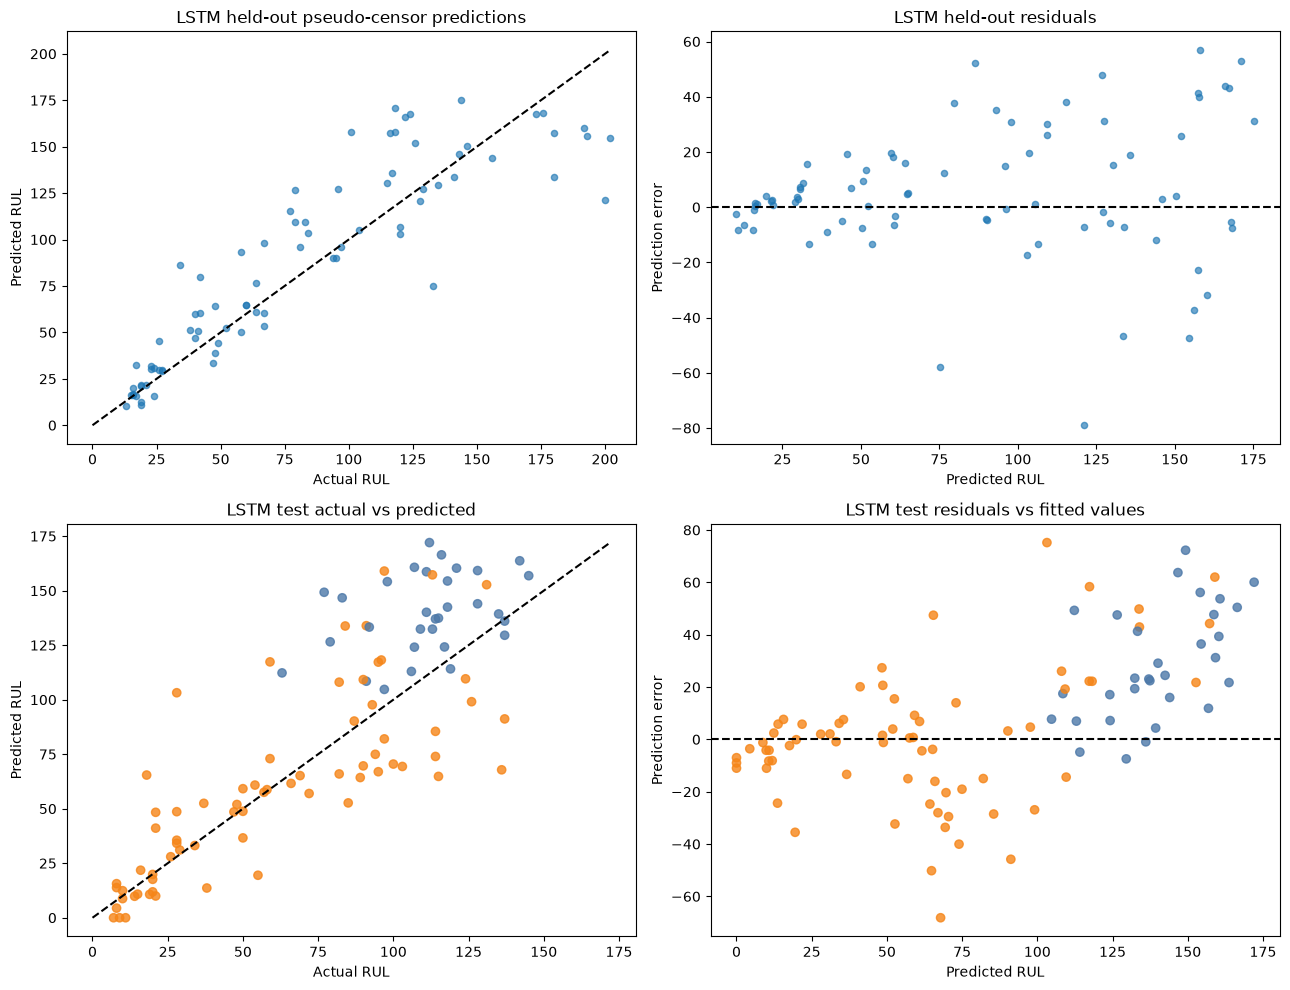

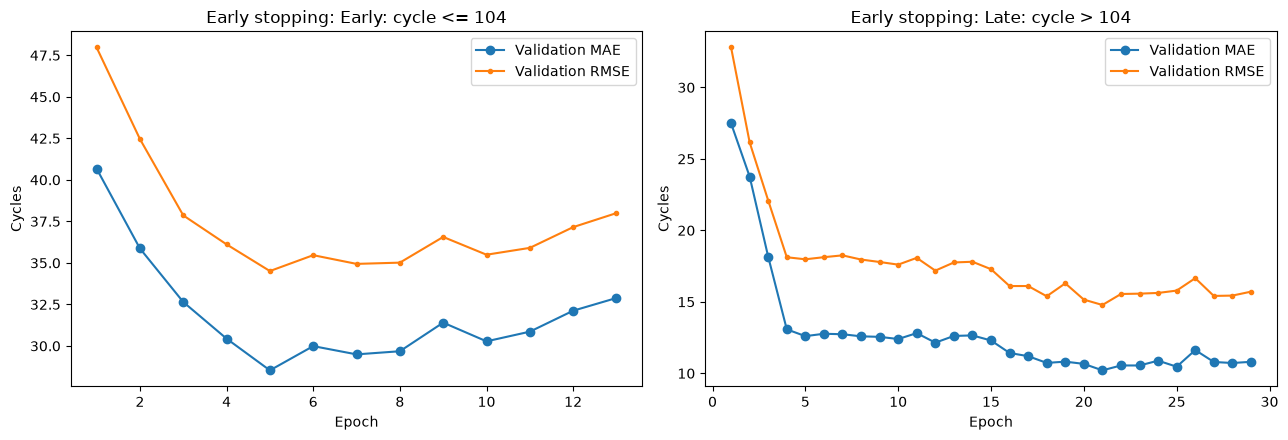

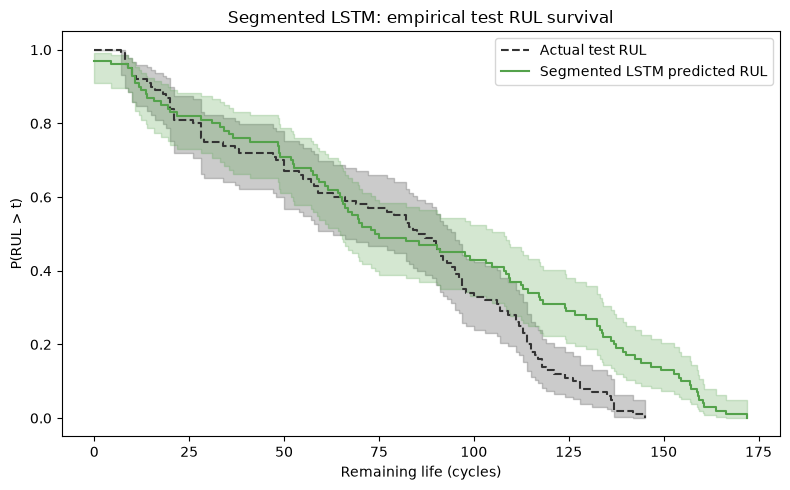

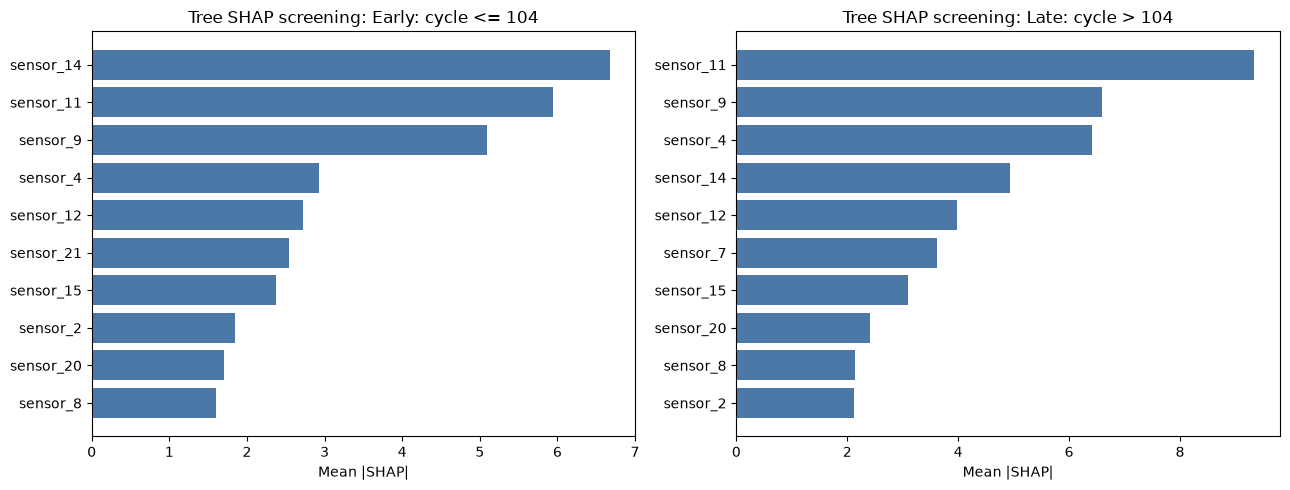

In [19]:
# Select LSTM inputs from training-only Tree SHAP and predict RUL with the fixed Q0.5 cycle knot.
from pathlib import Path
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
import scipy.stats as stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

if "optimal_knot" not in globals():
    raise RuntimeError("Run the preceding knot-optimization cell first.")
torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(min(4, torch.get_num_threads()))
sequence_length = 15
max_epochs = 60
batch_size = 512
patience = 8
images_dir = Path("images")
images_dir.mkdir(exist_ok=True)
lstm_segment_names = [
    f"Early: cycle <= {optimal_knot:g}",
    f"Late: cycle > {optimal_knot:g}",
]
train_cycle = train_rows["cycle"].to_numpy()
lstm_train_segment = np.where(
    train_cycle <= optimal_knot, lstm_segment_names[0], lstm_segment_names[1]
)
lstm_segment_masks = {
    name: lstm_train_segment == name for name in lstm_segment_names
}
lstm_test_segment = np.where(
    test_cycles <= optimal_knot, lstm_segment_names[0], lstm_segment_names[1]
)

# Hold out whole engines for validation; SHAP feature selection only sees training engines.
unique_engines = np.sort(np.unique(engine_groups))
engine_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
fit_engine_positions, validation_engine_positions = next(
    engine_splitter.split(unique_engines, groups=unique_engines)
)
fit_engines = set(unique_engines[fit_engine_positions].tolist())
validation_engines = set(unique_engines[validation_engine_positions].tolist())
assert not fit_engines.intersection(validation_engines)
print(
    f"LSTM engine split: training engines={len(fit_engines)}, "
    f"validation engines={len(validation_engines)}, test engines={len(test_last)}"
)

# Tree SHAP screening on the original variable scale selects interpretable settings/sensors.
raw_explanatory_features = predictor_columns
selected_lstm_features = {}
shap_screen_models = {}
shap_screen_values = {}
for segment_index, name in enumerate(lstm_segment_names):
    eligible = (
        lstm_segment_masks[name]
        & train_rows["engine_id"].isin(fit_engines).to_numpy()
    )
    screening_model = xgb.XGBRegressor(
        objective="reg:squarederror",
        n_estimators=140,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=4,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=5.0,
        random_state=42 + segment_index,
        n_jobs=-1,
        verbosity=0,
    )
    screening_model.fit(
        train_rows.loc[eligible, raw_explanatory_features].astype(float),
        y_train[eligible],
    )
    screening_sample = train_rows.loc[
        eligible, raw_explanatory_features
    ].sample(n=min(300, int(eligible.sum())), random_state=42)
    explanation = shap.TreeExplainer(screening_model)(
        screening_sample.astype(float)
    )
    mean_abs = np.abs(explanation.values).mean(axis=0)
    ranking = np.argsort(mean_abs)[::-1]
    chosen_indices = ranking[:min(8, len(ranking))]
    selected_lstm_features[name] = [
        raw_explanatory_features[index] for index in chosen_indices
    ]
    shap_screen_models[name] = screening_model
    shap_screen_values[name] = (screening_sample, explanation, mean_abs)
    print(f"\n{name}: SHAP-selected LSTM explanatory variables:")
    for index in chosen_indices:
        print(f"  {raw_explanatory_features[index]}: mean |SHAP|={mean_abs[index]:.4f}")

# Convert engine trajectories into trailing fixed-length windows; left-pad early history.
def make_windows(frame, scaled_values, target_mask, targets=None):
    sequences = []
    labels = []
    row_indices = []
    for _, group in frame.groupby("engine_id", sort=False):
        indices = group.index.to_numpy(dtype=int)
        for position, row_index in enumerate(indices):
            if not target_mask[row_index]:
                continue
            start = max(0, position - sequence_length + 1)
            window = scaled_values[indices[start:position + 1]]
            if len(window) < sequence_length:
                pad = np.repeat(window[:1], sequence_length - len(window), axis=0)
                window = np.concatenate([pad, window], axis=0)
            sequences.append(window)
            row_indices.append(row_index)
            if targets is not None:
                labels.append(float(targets[row_index]))
    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(labels, dtype=np.float32),
        np.asarray(row_indices, dtype=int),
    )

class RUL_LSTM(nn.Module):
    def __init__(self, input_size, hidden_size=24):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=1, batch_first=True,
        )
        self.regression = nn.Linear(hidden_size, 1)

    def forward(self, sequence):
        output, _ = self.recurrent(sequence)
        return self.regression(output[:, -1, :]).squeeze(-1)

def train_with_validation(train_x, train_y, valid_x, valid_y, seed):
    torch.manual_seed(seed)
    target_mean = float(np.mean(train_y))
    target_scale = float(np.std(train_y))
    if target_scale <= 0:
        raise ValueError("Training RUL target has no variation.")
    train_y_scaled = (train_y - target_mean) / target_scale
    model = RUL_LSTM(train_x.shape[-1]).cpu()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_function = nn.MSELoss()
    train_data = TensorDataset(
        torch.from_numpy(train_x), torch.from_numpy(train_y_scaled.astype(np.float32))
    )
    loader = DataLoader(
        train_data, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    valid_tensor = torch.from_numpy(valid_x)
    best_mae = float("inf")
    best_epoch = 1
    best_state = copy.deepcopy(model.state_dict())
    stale_epochs = 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        for batch_x, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(batch_x), batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        model.eval()
        with torch.no_grad():
            valid_prediction = model(valid_tensor).numpy() * target_scale + target_mean
        valid_mae = mean_absolute_error(valid_y, valid_prediction)
        valid_rmse = mean_squared_error(valid_y, valid_prediction) ** 0.5
        history.append({
            "epoch": epoch, "validation_mae": valid_mae,
            "validation_rmse": valid_rmse,
        })
        if valid_mae < best_mae:
            best_mae = valid_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_epoch, pd.DataFrame(history), target_mean, target_scale

def fit_fixed_epochs(train_x, train_y, epochs, seed, target_mean, target_scale):
    torch.manual_seed(seed)
    train_y_scaled = (train_y - target_mean) / target_scale
    model = RUL_LSTM(train_x.shape[-1]).cpu()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_function = nn.MSELoss()
    data = TensorDataset(
        torch.from_numpy(train_x), torch.from_numpy(train_y_scaled.astype(np.float32))
    )
    loader = DataLoader(
        data, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    for _ in range(epochs):
        model.train()
        for batch_x, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(batch_x), batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
    return model

lstm_models = {}
lstm_target_scalers = {}
lstm_scalers = {}
lstm_epoch_histories = {}
lstm_validation_rows = []
lstm_train_apparent_rows = []
lstm_test_predictions = np.empty(len(test_last), dtype=float)
lstm_test_feature_arrays = {}
lstm_test_sequence_arrays = {}

for segment_index, name in enumerate(lstm_segment_names):
    selected_features = selected_lstm_features[name]
    input_features = ["cycle", *selected_features]
    fit_mask = (
        train_rows["engine_id"].isin(fit_engines).to_numpy()
        & lstm_segment_masks[name]
    )
    valid_engine_mask = train_rows["engine_id"].isin(validation_engines).to_numpy()
    scaler = StandardScaler().fit(
        train_rows.loc[fit_mask, input_features].astype(float)
    )
    train_scaled = scaler.transform(train_rows[input_features].astype(float)).astype(np.float32)
    test_scaled = scaler.transform(test_last[input_features].astype(float)).astype(np.float32)
    all_train_target_mask = lstm_segment_masks[name]
    all_train_sequences, all_train_targets, all_train_row_ids = make_windows(
        train_rows, train_scaled, all_train_target_mask, y_train
    )
    row_to_position = {
        int(row_index): position
        for position, row_index in enumerate(all_train_row_ids)
    }

    # One early-stopping validation cutoff per held-out engine at each pre-failure fraction.
    validation_row_ids = []
    for engine_id in sorted(validation_engines):
        failure_cycle = int(train_failure_cycle.loc[engine_id])
        for fraction in (0.25, 0.50, 0.75, 0.90):
            cutoff = min(failure_cycle - 1, max(1, int(round(failure_cycle * fraction))))
            validation_row_ids.append(row_at_cycle[int(engine_id)][cutoff])
    validation_row_ids = np.asarray(validation_row_ids, dtype=int)
    validation_row_ids = validation_row_ids[
        lstm_segment_masks[name][validation_row_ids]
    ]
    validation_positions = np.asarray(
        [row_to_position[index] for index in validation_row_ids], dtype=int
    )
    train_positions = np.asarray([
        position for position, row_index in enumerate(all_train_row_ids)
        if train_rows.iloc[row_index]["engine_id"] in fit_engines
    ], dtype=int)
    if not len(validation_positions):
        raise ValueError(f"No pseudo-censor validation examples for LSTM {name}.")
    if np.intersect1d(
        train_rows.iloc[all_train_row_ids[train_positions]]["engine_id"].unique(),
        train_rows.iloc[validation_row_ids]["engine_id"].unique(),
    ).size:
        raise AssertionError("Engine leakage in LSTM train/validation split.")

    print(
        f"\nTraining LSTM for {name}: {len(train_positions)} training windows, "
        f"{len(validation_positions)} held-out pseudo-censor windows, "
        f"{len(selected_features)} SHAP-selected variables."
    )
    early_model, best_epoch, history, target_mean, target_scale = train_with_validation(
        all_train_sequences[train_positions],
        all_train_targets[train_positions],
        all_train_sequences[validation_positions],
        all_train_targets[validation_positions],
        seed=100 + segment_index,
    )
    lstm_epoch_histories[name] = history
    validation_prediction = np.maximum(
        0.0,
        early_model(torch.from_numpy(all_train_sequences[validation_positions]))
        .detach().numpy() * target_scale + target_mean,
    )
    for row_index, prediction in zip(validation_row_ids, validation_prediction):
        lstm_validation_rows.append({
            "engine_id": int(train_rows.iloc[row_index]["engine_id"]),
            "segment": name,
            "actual_RUL": float(y_train[row_index]),
            "predicted_RUL": float(prediction),
        })
    print(f"Early-stopping selected epoch: {best_epoch}")

    # Refit on every training engine for the selected epoch count.
    final_model = fit_fixed_epochs(
        all_train_sequences,
        all_train_targets,
        best_epoch,
        seed=200 + segment_index,
        target_mean=float(np.mean(all_train_targets)),
        target_scale=float(np.std(all_train_targets)),
    )
    lstm_models[name] = final_model
    lstm_target_scalers[name] = (float(np.mean(all_train_targets)), float(np.std(all_train_targets)))
    lstm_scalers[name] = scaler
    apparent_prediction = np.maximum(
        0.0,
        final_model(torch.from_numpy(all_train_sequences)).detach().numpy()
        * lstm_target_scalers[name][1] + lstm_target_scalers[name][0],
    )
    lstm_train_apparent_rows.append({
        "Segment": name,
        "Training rows": len(all_train_targets),
        "Best epoch": best_epoch,
        "Apparent MAE": mean_absolute_error(all_train_targets, apparent_prediction),
        "Apparent RMSE": mean_squared_error(all_train_targets, apparent_prediction) ** 0.5,
        "Apparent R2": r2_score(all_train_targets, apparent_prediction),
    })

    test_mask = lstm_test_segment == name
    # Only each engine's final sequence is needed for the test RUL prediction.
    test_frame = test_last.copy()
    test_target_mask = np.ones(len(test_frame), dtype=bool)
    test_sequences, _, test_row_ids = make_windows(
        test_frame, test_scaled, test_target_mask, targets=None
    )
    with torch.no_grad():
        predicted = np.maximum(
            0.0,
            final_model(torch.from_numpy(test_sequences)).numpy()
            * lstm_target_scalers[name][1] + lstm_target_scalers[name][0],
        )
    lstm_test_predictions[test_row_ids[test_mask]] = predicted[test_mask]
    lstm_test_feature_arrays[name] = (test_frame[input_features].to_numpy(), input_features)
    lstm_test_sequence_arrays[name] = test_sequences[test_mask]

lstm_train_apparent = pd.DataFrame(lstm_train_apparent_rows).set_index("Segment")
lstm_validation = pd.DataFrame(lstm_validation_rows)
lstm_validation_metrics = []
for name in lstm_segment_names:
    subset = lstm_validation[lstm_validation["segment"] == name]
    lstm_validation_metrics.append({
        "Segment": name,
        "Pseudo-censor rows": len(subset),
        "Held-out engines": subset["engine_id"].nunique(),
        "Validation MAE": mean_absolute_error(subset["actual_RUL"], subset["predicted_RUL"]),
        "Validation RMSE": mean_squared_error(subset["actual_RUL"], subset["predicted_RUL"]) ** 0.5,
        "Validation R2": r2_score(subset["actual_RUL"], subset["predicted_RUL"]),
    })
lstm_validation_metrics = pd.DataFrame(lstm_validation_metrics).set_index("Segment")
lstm_test_error = lstm_test_predictions - actual_test_rul
lstm_test_metrics = {
    "Test engines": len(actual_test_rul),
    "C-index": concordance_index(actual_test_rul, lstm_test_predictions),
    "MAE (cycles)": mean_absolute_error(actual_test_rul, lstm_test_predictions),
    "RMSE (cycles)": mean_squared_error(actual_test_rul, lstm_test_predictions) ** 0.5,
    "R2": r2_score(actual_test_rul, lstm_test_predictions),
    "Median predicted RUL": float(np.median(lstm_test_predictions)),
    "Median actual RUL": float(np.median(actual_test_rul)),
}
print("\nLSTM apparent train performance:")
print(lstm_train_apparent.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nLSTM engine-held-out pseudo-censor validation:")
print(lstm_validation_metrics.to_string(float_format=lambda value: f"{value:.3f}"))
print("\nLSTM FD001 test metrics:")
print(pd.Series(lstm_test_metrics).to_string(float_format=lambda value: f"{value:.3f}"))
print("LSTM test engines by segment:", pd.Series(lstm_test_segment).value_counts().to_dict())

# Diagnostic metrics and visual comparisons.
lstm_shapiro = pd.DataFrame({
    "Held-out validation": {
        "Shapiro residual p-value": float(stats.shapiro(
            lstm_validation["predicted_RUL"] - lstm_validation["actual_RUL"]
        ).pvalue),
    },
    "Test engines": {
        "Shapiro residual p-value": float(stats.shapiro(lstm_test_error).pvalue),
    },
}).T
print("\nLSTM residual normality diagnostic (descriptive, not an LSTM assumption):")
print(lstm_shapiro.to_string(float_format=lambda value: f"{value:.4g}"))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(lstm_validation["actual_RUL"], lstm_validation["predicted_RUL"], alpha=0.65, s=20)
limit = max(float(lstm_validation["actual_RUL"].max()), float(lstm_validation["predicted_RUL"].max()))
axes[0, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[0, 0].set(title="LSTM held-out pseudo-censor predictions", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[0, 1].scatter(lstm_validation["predicted_RUL"], lstm_validation["predicted_RUL"] - lstm_validation["actual_RUL"], alpha=0.65, s=20)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="LSTM held-out residuals", xlabel="Predicted RUL", ylabel="Prediction error")
axes[1, 0].scatter(actual_test_rul, lstm_test_predictions, c=np.where(lstm_test_segment == lstm_segment_names[0], "#4c78a8", "#f58518"), alpha=0.8)
limit = max(float(actual_test_rul.max()), float(lstm_test_predictions.max()))
axes[1, 0].plot([0, limit], [0, limit], color="black", linestyle="--")
axes[1, 0].set(title="LSTM test actual vs predicted", xlabel="Actual RUL", ylabel="Predicted RUL")
axes[1, 1].scatter(lstm_test_predictions, lstm_test_error, c=np.where(lstm_test_segment == lstm_segment_names[0], "#4c78a8", "#f58518"), alpha=0.8)
axes[1, 1].axhline(0, color="black", linestyle="--")
axes[1, 1].set(title="LSTM test residuals vs fitted values", xlabel="Predicted RUL", ylabel="Prediction error")
fig.tight_layout()
fig.savefig(images_dir / "segmented_lstm_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, lstm_segment_names):
    history = lstm_epoch_histories[name]
    ax.plot(history["epoch"], history["validation_mae"], marker="o", label="Validation MAE")
    ax.plot(history["epoch"], history["validation_rmse"], marker=".", label="Validation RMSE")
    ax.set(title=f"Early stopping: {name}", xlabel="Epoch", ylabel="Cycles")
    ax.legend()
fig.tight_layout()
fig.savefig(images_dir / "segmented_lstm_training.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
KaplanMeierFitter().fit(
    actual_test_rul, event_observed=np.ones(len(actual_test_rul)), label="Actual test RUL"
).plot_survival_function(ax=ax, ci_show=True, color="#333333", linestyle="--")
KaplanMeierFitter().fit(
    lstm_test_predictions, event_observed=np.ones(len(lstm_test_predictions)),
    label="Segmented LSTM predicted RUL",
).plot_survival_function(ax=ax, ci_show=True, color="#54a24b")
ax.set(title="Segmented LSTM: empirical test RUL survival", xlabel="Remaining life (cycles)", ylabel="P(RUL > t)")
fig.tight_layout()
fig.savefig(images_dir / "segmented_lstm_survival.png", dpi=160, bbox_inches="tight")
plt.show()

# Show SHAP screening importance by segment; the recurrent model uses the selected raw variables.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, lstm_segment_names):
    _, _, mean_abs = shap_screen_values[name]
    order = np.argsort(mean_abs)[-10:]
    ax.barh(
        np.asarray(raw_explanatory_features)[order],
        mean_abs[order],
        color="#4c78a8",
    )
    ax.set(title=f"Tree SHAP screening: {name}", xlabel="Mean |SHAP|")
fig.tight_layout()
fig.savefig(images_dir / "segmented_lstm_shap_selection.png", dpi=160, bbox_inches="tight")
plt.show()


**Discussion.** The Q0.5 segmented LSTM uses 15-cycle sequences, separate early/late networks, standardized RUL, engine-disjoint 80/20 training/validation, and early stopping at epochs 5 and 21. Held-out pseudo-censor validation MAE/RMSE/R-squared were 28.530/34.509/0.368 early and 10.207/14.780/0.841 late. Test metrics were C-index 0.826, MAE 22.349 cycles, RMSE 29.437, and R-squared 0.498; 31 test engines are early and 69 late. The test residual Shapiro p-value is 0.3768, while validation residual p=0.003584; normality is not an LSTM requirement. SHAP-selected inputs come from tree surrogates, not direct LSTM explanations. The modest validation cohort and single reused test set limit model-ranking claims.

### 4. Fixed-parameter Q0.5 segmented LightGBM

To include LightGBM in the median-knot regression comparison, this experiment fits separate models for cycles <=104 and >104 using cycle and all varying settings/sensors. It uses fixed LightGBM parameters rather than a new hyperparameter search. Three-fold GroupKFold pseudo-censor validation keeps engines disjoint; test engines are routed by their last observed cycle. Gain-based feature importance is reported, not SHAP.


In [20]:
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
from lifelines.utils import concordance_index
from scipy.stats import shapiro, spearmanr, wilcoxon
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    *[f"sensor_{i}" for i in range(1, 22)],
]
train_raw = pd.read_csv(
    Path("CMAPSSData") / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
test_raw = pd.read_csv(
    Path("CMAPSSData") / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)
actual_test_rul = pd.read_csv(
    Path("CMAPSSData") / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"],
)["RUL"].to_numpy(dtype=float)

train_rows = train_raw.copy()
train_rows["failure_cycle_T"] = train_rows["engine_id"].map(
    train_rows.groupby("engine_id")["cycle"].max()
)
train_rows["remaining_life"] = (
    train_rows["failure_cycle_T"] - train_rows["cycle"]
)
feature_columns = [
    "cycle",
    *[column for column in columns[2:] if train_rows[column].nunique() > 1],
]
knot = float(train_rows["cycle"].quantile(0.5))
segments = [f"Early: cycle <= {knot:g}", f"Late: cycle > {knot:g}"]


def make_model():
    return lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        importance_type="gain",
        random_state=42,
        verbosity=-1,
        n_jobs=1,
    )


def score(actual, predicted):
    return {
        "Rows / engines": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R-squared": r2_score(actual, predicted),
    }


def pseudo_rows(rows):
    selected = []
    for _, engine in rows.groupby("engine_id", sort=False):
        lifetime = int(engine["failure_cycle_T"].iloc[0])
        cutoffs = np.unique(
            np.clip(
                np.rint(lifetime * np.array([0.3, 0.5, 0.7, 0.9])).astype(int),
                1,
                lifetime - 1,
            )
        )
        selected.append(engine.loc[engine["cycle"].isin(cutoffs)])
    return pd.concat(selected, ignore_index=True)


validation = []
folds = GroupKFold(n_splits=3)
for fold, (fit_idx, held_idx) in enumerate(
    folds.split(train_rows, groups=train_rows["engine_id"]),
    start=1,
):
    fit = train_rows.iloc[fit_idx]
    held = pseudo_rows(train_rows.iloc[held_idx])
    for segment_index, segment in enumerate(segments):
        fit_cycles = fit["cycle"].to_numpy()
        held_cycles = held["cycle"].to_numpy()
        fit_mask = fit_cycles <= knot if segment_index == 0 else fit_cycles > knot
        held_mask = held_cycles <= knot if segment_index == 0 else held_cycles > knot
        if not fit_mask.any() or not held_mask.any():
            continue
        model = make_model().fit(
            fit.loc[fit_mask, feature_columns],
            fit.loc[fit_mask, "remaining_life"],
        )
        part = held.loc[
            held_mask,
            ["engine_id", "remaining_life"],
        ].copy()
        part["fold"] = fold
        part["segment"] = segment
        part["prediction"] = np.maximum(
            0,
            model.predict(held.loc[held_mask, feature_columns]),
        )
        validation.append(part)

validation = pd.concat(validation, ignore_index=True)
print(f"Fixed training-cycle Q0.5 knot: {knot:g}")
print("Grouped pseudo-censor validation:")
validation_results = [
    {
        "Segment": name,
        **score(group["remaining_life"], group["prediction"]),
    }
    for name, group in validation.groupby("segment", sort=False)
]
print(
    pd.DataFrame(validation_results)
    .set_index("Segment")
    .to_string(float_format=lambda value: f"{value:.3f}")
)

final_models = {}
for segment_index, segment in enumerate(segments):
    cycles = train_rows["cycle"].to_numpy()
    mask = cycles <= knot if segment_index == 0 else cycles > knot
    final_models[segment] = make_model().fit(
        train_rows.loc[mask, feature_columns],
        train_rows.loc[mask, "remaining_life"],
    )

test_last = (
    test_raw.sort_values(["engine_id", "cycle"])
    .groupby("engine_id", as_index=False)
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)
assert len(test_last) == len(actual_test_rul) == 100
test_segments = np.where(
    test_last["cycle"].to_numpy() <= knot,
    segments[0],
    segments[1],
)
test_predictions = np.empty(len(test_last))
for segment in segments:
    mask = test_segments == segment
    test_predictions[mask] = np.maximum(
        0,
        final_models[segment].predict(test_last.loc[mask, feature_columns]),
    )

print("\nTest results by segment:")
test_results = [
    {
        "Segment": segment,
        **score(
            actual_test_rul[test_segments == segment],
            test_predictions[test_segments == segment],
        ),
    }
    for segment in segments
]
print(
    pd.DataFrame(test_results)
    .set_index("Segment")
    .to_string(float_format=lambda value: f"{value:.3f}")
)
print("\nOverall test metrics:")
overall_metrics = {
    "Test engines": len(actual_test_rul),
    "C-index": concordance_index(actual_test_rul, test_predictions),
    "MAE (cycles)": mean_absolute_error(actual_test_rul, test_predictions),
    "RMSE (cycles)": mean_squared_error(actual_test_rul, test_predictions) ** 0.5,
    "R-squared": r2_score(actual_test_rul, test_predictions),
    "Median predicted RUL": np.median(test_predictions),
    "Median actual RUL": np.median(actual_test_rul),
}
print(pd.Series(overall_metrics).to_string(float_format=lambda value: f"{value:.3f}"))
print("Test engines by segment:", pd.Series(test_segments).value_counts().to_dict())

residual = test_predictions - actual_test_rul
print("\nDescriptive residual diagnostics:")
residual_diagnostics = {
    "Shapiro p-value": shapiro(residual).pvalue,
    "Wilcoxon median-zero p-value": wilcoxon(residual).pvalue,
    "Spearman |error|-prediction rho": spearmanr(
        np.abs(residual), test_predictions
    ).statistic,
}
print(pd.Series(residual_diagnostics).to_string(float_format=lambda value: f"{value:.4g}"))
for segment, model in final_models.items():
    print(f"\n{segment}: top LightGBM gain importances (not SHAP)")
    importances = pd.Series(
        model.feature_importances_,
        index=feature_columns,
    ).sort_values(ascending=False).head(10)
    print(importances.to_string(float_format=lambda value: f"{value:.3f}"))


Fixed training-cycle Q0.5 knot: 104
Grouped pseudo-censor validation:
                     Rows / engines    MAE   RMSE  R-squared
Segment                                                     
Early: cycle <= 104             167 34.571 42.043     -0.187
Late: cycle > 104               233 18.219 27.999      0.529



Test results by segment:
                     Rows / engines    MAE   RMSE  R-squared
Segment                                                     
Early: cycle <= 104              31 34.440 40.109     -3.363
Late: cycle > 104                69 14.579 20.093      0.733

Overall test metrics:
Test engines           100.000
C-index                  0.836
MAE (cycles)            20.736
RMSE (cycles)           27.880
R-squared                0.550
Median predicted RUL    79.208
Median actual RUL       86.000
Test engines by segment: {'Late: cycle > 104': 69, 'Early: cycle <= 104': 31}

Descriptive residual diagnostics:
Shapiro p-value                   0.09165
Wilcoxon median-zero p-value        0.001
Spearman |error|-prediction rho    0.6571

Early: cycle <= 104: top LightGBM gain importances (not SHAP)
cycle       92361801.484
sensor_11   18523064.596
sensor_12   10565659.567
sensor_14    9649813.792
sensor_4     9552901.909
sensor_9     9017698.696
sensor_15    7245519.830
sensor_7     

## Q0.5 segmented regression comparison

All rows use the same supplied FD001 test set of 100 engines and the fixed training-cycle-row median knot, cycle 104. Lower MAE/RMSE are better; higher C-index/R-squared are better. The two PCA-XGBoost experiments use different validation and training pipelines and should not be read as a controlled head-to-head comparison.

| Regression model | Segment-specific test engines | C-index | MAE (cycles) | RMSE (cycles) | R-squared |
|---|---:|---:|---:|---:|---:|
| SHAP-screened XGBoost with sensor bins | 31 / 69 | 0.830 | 20.108 | 26.310 | N/A |
| PCA-XGBoost + AGS, fixed Q0.5 pipeline | 31 / 69 | **0.836** | **19.128** | 26.404 | 0.596 |
| PCA-XGBoost + AGS, grouped-CV tuned pipeline | 31 / 69 | 0.830 | 19.844 | **26.262** | **0.601** |
| Segmented LightGBM, fixed parameters | 31 / 69 | **0.836** | 20.736 | 27.880 | 0.550 |
| SHAP-informed segmented LSTM | 31 / 69 | 0.826 | 22.349 | 29.437 | 0.498 |

The fixed Q0.5 PCA-XGBoost pipeline has the lowest MAE in this table; another PCA-XGBoost variant has the lowest RMSE and R-squared. LightGBM ties the highest C-index but has larger point errors. The test split is imbalanced (31 early, 69 late), and early-segment test R-squared is negative for the fixed PCA-XGBoost and LightGBM models. Thus, aggregate scores hide substantial early-regime difficulty. These are benchmark results on one supplied test set, not evidence that the knot is a biological change point or that one architecture generalizes best. The survival estimators remain duration-based; this cycle-knot regression approach is not directly applicable to their estimands. See [`segmented_regression_results.md`](./segmented_regression_results.md) for methodology, per-segment metrics, validation, diagnostics, importance, and limitations.

## Model disclosure and scope

This notebook analyzes the NASA CMAPSS FD001 subset. Training data comprise 20,631 engine-cycle rows from 100 engines; the test set contains 100 engines evaluated against `RUL_FD001.txt`. Survival analyses use failure cycle **T** and engine-level baselines where specified. Remaining-life regressors predict residual life in cycles using training engine-cycle rows and test engines' last observed cycles. Engine-grouped pseudo-censor validation prevents an engine's rows from crossing a training/validation boundary.

The regression experiments use the training-cycle-row median (Q0.5, cycle 104) as a fixed knot. The knot is calculated from training rows only; test engines are assigned using their last observed cycle. Segment-specific XGBoost, PCA-XGBoost, LightGBM, and LSTM models are evaluated. The fixed-knot validation reports performance but does not choose the knot. The survival models remain in their duration-based form because the segmented-regression split is not a direct replacement for survival-function or hazard modeling.

The supplied test metrics are descriptive estimates on the 100-engine FD001 benchmark, not external validation. Engine-cycle rows are repeated measurements and must not be interpreted as 20,631 independent engines. RMSE complements MAE by penalizing larger errors. AIC/BIC are not applicable to Kaplan-Meier, RSF, or these XGBoost/LightGBM/LSTM prediction fits. Exploratory sensor tests, model feature importance, and SHAP values do not establish causal effects. Full knot methodology, outputs, interpretation, diagnostics, and limitations are in [`segmented_regression_results.md`](./segmented_regression_results.md).